# BottleQC — train detection trên Colab GPU

Trong VS Code chọn **Select Kernel → Colab → runtime GPU**, chạy **1 → 2 → 3 → 4**.
Cell 4 bắt đầu train thật; cell 5 đánh giá sau khi train xong. Không cần chạy lại 9A–9E.

Baseline khởi đầu: **YOLO11n pretrained, 640px, batch 16, tối đa 100 epoch**, early stopping patience 20.
Đây chưa phải cấu hình tối ưu hoặc cam kết accuracy. Dataset: **3849 train / 307 val / 201 test**.
Train dùng train/val; test chỉ dùng đánh giá cuối. Nhãn và tính độc lập phiên chụp chưa được kiểm tra đầy đủ.

Mỗi epoch hoàn tất sao lưu checkpoint lên Drive, kiểm tra SHA trước khi cập nhật con trỏ.
Giữ snapshot theo epoch để checkpoint cũ vẫn còn khi lần ghi sau bị ngắt; có thể tốn vài GB Drive.
Nếu server mất: kết nối GPU mới, chạy lại **1 → 4 cùng RUN_NAME và cấu hình** để resume.
Epoch đang dở bị mất; trước checkpoint đầu tiên phải chạy lại từ đầu.
Drive lỗi/đầy sẽ làm dừng job khi sao lưu, không tự chuyển sang CPU.

[Ultralytics train/resume](https://docs.ultralytics.com/modes/train/) ·
[Colab VS Code](https://github.com/googlecolab/colab-vscode)

**Chỉ thử video bằng model đã train:** chỉ chạy cell 6 ở cuối; cell này tự thiết lập trên runtime Colab mới, không cần chạy lại 1–5.


## 1 — Kiểm tra GPU và mount Drive

In [1]:
import sys, os, json, hashlib, shutil, subprocess, zipfile, stat, uuid
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone

def require_gpu():
    if sys.platform != "linux" or not Path("/content").is_dir():
        raise RuntimeError("Chọn Colab remote kernel; không chạy trên Windows.")
    import google.colab
    import torch
    if not torch.cuda.is_available():
        raise RuntimeError("Runtime không có CUDA GPU. Dừng, không chạy CPU.")
    return torch

torch = require_gpu()
print(sys.version)
print("GPU_OK:", torch.cuda.get_device_name(0), "torch=", torch.__version__)
subprocess.run(["nvidia-smi"], check=True)
DRIVE = Path("/content/drive/MyDrive")
if not DRIVE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")
if not DRIVE.is_dir():
    raise RuntimeError("Dùng lệnh VS Code: Colab: Mount Google Drive to Server...")
print("DRIVE_OK:", DRIVE)

Mounted at /content/drive
DRIVE_OK: /content/drive/MyDrive


## 2 — Cài dependency train trên Colab

Không cần cài toàn bộ ứng dụng hoặc Python 3.13 của Windows.
Nếu pip yêu cầu restart kernel: restart rồi chạy lại 1–2.

In [2]:
require_gpu()
ULTRALYTICS_VERSION = "8.4.193"  # cùng pin với real-model trong pyproject.toml
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                "ultralytics==" + ULTRALYTICS_VERSION], check=True)
import ultralytics, yaml
from ultralytics import YOLO
require_gpu()
if ultralytics.__version__ != ULTRALYTICS_VERSION:
    raise RuntimeError("Import khác bản vừa cài; restart kernel rồi chạy lại 1–2.")
print("TRAIN_DEPS_OK:", ultralytics.__version__, "torch=", torch.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
TRAIN_DEPS_OK: 8.4.193 torch= 2.11.0+cu130


## 3 — Khôi phục dữ liệu và chọn cấu hình

Nếu dùng account khác, chỉnh **CANDIDATE_DIR** tới folder Drive đã chia sẻ/copy đủ
prepared-candidate.zip, COMPLETE.json và residual-dhash-review.json.
Ảnh giải nén vào disk Colab để đọc nhanh; kết quả lưu Drive.
Muốn thí nghiệm cấu hình khác, đổi RUN_NAME trước khi train. Resume giữ nguyên tên/cấu hình.

In [3]:
require_gpu()
CANDIDATE_DIR = DRIVE / "BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5"
EXPECTED_SHA = "28ee24280bce8184acd1cdf9a97e850788e908109bfa662efecb07a8a7b179eb"
EXPECTED_COUNTS = {"train": 3849, "val": 307, "test": 201}
CLASSES = {0: "bottle", 1: "cap", 2: "label"}
RUN_NAME = "bottleqc-yolo11n-640-v1"
CONFIG = dict(model="yolo11n.pt", epochs=100, imgsz=640, batch=16, patience=20,
              seed=42, workers=2, device=0, cache=False, amp=True)

def sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + "." + uuid.uuid4().hex + ".part")
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    tmp.replace(path)

def copy_verified(source, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    expected = sha(source)
    tmp = destination.with_name(destination.name + "." + uuid.uuid4().hex + ".part")
    shutil.copyfile(source, tmp)
    if sha(tmp) != expected:
        raise RuntimeError("Copy sai SHA: " + str(destination))
    tmp.replace(destination)
    return expected

def restore_candidate(candidate_dir, destination, expected_sha, expected_counts):
    complete = json.loads((candidate_dir / "COMPLETE.json").read_text())
    residual = json.loads((candidate_dir / "residual-dhash-review.json").read_text())
    if (complete.get("archive_sha256") != expected_sha
            or residual.get("archive_sha256") != expected_sha
            or residual.get("requires_review") != 0
            or residual.get("decisions_changed_since_9d") is not False
            or residual.get("status") != "ALL_WARNINGS_ALREADY_REVIEWED_DIFFERENT"):
        raise RuntimeError("Candidate hoặc báo cáo 9E khác bản đã chọn.")
    archive = candidate_dir / "prepared-candidate.zip"
    if sha(archive) != expected_sha:
        raise RuntimeError("ZIP trên Drive sai SHA.")
    local_zip = destination.parent / (expected_sha[:16] + ".zip")
    copy_verified(archive, local_zip)
    with zipfile.ZipFile(local_zip) as z:
        seen = set()
        for item in z.infolist():
            p = PurePosixPath(item.filename)
            if (p.is_absolute() or ".." in p.parts or chr(92) in item.filename
                    or ":" in item.filename or stat.S_ISLNK(item.external_attr >> 16)
                    or item.filename in seen):
                raise RuntimeError("ZIP có đường dẫn không an toàn/trùng tên.")
            seen.add(item.filename)
        records = json.loads(z.read("retained-checksums.json"))
        cfg = yaml.safe_load(z.read("data.yaml"))
        names = cfg["names"]
        if isinstance(names, list):
            names = dict(enumerate(names))
        if names != CLASSES:
            raise RuntimeError("Sai class mapping bottle/cap/label.")
        expected_files = {r[k] for r in records for k in ("image", "label")}
        if expected_files != {n for n in seen if n.startswith(("images/", "labels/"))}:
            raise RuntimeError("Ảnh/nhãn không khớp retained checksums.")
        destination.mkdir(parents=True, exist_ok=False)
        z.extractall(destination)
    counts = dict.fromkeys(expected_counts, 0)
    for r in records:
        for key, checksum in (("image", "image_sha256"), ("label", "label_sha256")):
            p = (destination / r[key]).resolve()
            if not p.is_relative_to(destination.resolve()) or sha(p) != r[checksum]:
                raise RuntimeError("File candidate sai checksum/path: " + r[key])
        counts[r["split"]] += 1
    if counts != expected_counts:
        raise RuntimeError("Sai số ảnh candidate: " + str(counts))
    cfg.update(path=str(destination), train="images/train", val="images/val", test="images/test")
    data_yaml = destination / "data.yaml"
    data_yaml.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding="utf-8")
    return data_yaml

import re
if not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]{0,79}", RUN_NAME):
    raise ValueError("RUN_NAME không hợp lệ.")
WORK = Path("/content/bottleqc")
WORK.mkdir(exist_ok=True)
# Cùng đường dẫn ở các runtime: checkpoint resume vẫn trỏ đúng data.yaml.
DATA_ROOT = WORK / ("train-data-" + EXPECTED_SHA[:16])
if DATA_ROOT.exists():
    # Rerun cell 3 uses a new directory, then resume receives explicit data= below.
    DATA_ROOT = WORK / ("train-data-" + EXPECTED_SHA[:16] + "-" + uuid.uuid4().hex[:8])
DATA_YAML = restore_candidate(CANDIDATE_DIR, DATA_ROOT, EXPECTED_SHA, EXPECTED_COUNTS)
LOCAL_RUN = WORK / "runs" / RUN_NAME
RUN = DRIVE / "BottleQC/training-runs" / RUN_NAME
RUN.mkdir(parents=True, exist_ok=True)
probe = RUN / (".write-probe-" + uuid.uuid4().hex)
probe.write_text("ok")
if probe.read_text() != "ok":
    raise RuntimeError("Drive không ghi được.")
probe.unlink()
BINDING = dict(dataset_sha256=EXPECTED_SHA, config=CONFIG, ultralytics=ultralytics.__version__,
               torch=torch.__version__, classes=CLASSES)
BINDING = json.loads(json.dumps(BINDING))
binding_file = RUN / "run-config.json"
if binding_file.exists() and json.loads(binding_file.read_text()) != BINDING:
    raise RuntimeError("Run đã có cấu hình/runtime khác. Giữ bản cũ để resume hoặc đổi RUN_NAME.")
write_json(binding_file, BINDING)
print("DATA_READY:", EXPECTED_COUNTS, "DATA_YAML:", DATA_YAML)
print("RUN:", RUN)
print("CONFIG:", CONFIG)

DATA_READY: {'train': 3849, 'val': 307, 'test': 201} DATA_YAML: /content/bottleqc/train-data-28ee24280bce8184/data.yaml
RUN: /content/drive/MyDrive/BottleQC/training-runs/bottleqc-yolo11n-640-v1
CONFIG: {'model': 'yolo11n.pt', 'epochs': 100, 'imgsz': 640, 'batch': 16, 'patience': 20, 'seed': 42, 'workers': 2, 'device': 0, 'cache': False, 'amp': True}


## 4 — TRAIN / RESUME (cell này bắt đầu train thật)

Lần đầu tải pretrained YOLO11n trực tiếp vào Colab; lần sau tự resume từ checkpoint Drive.
**CHECKPOINT_ON_DRIVE** xác nhận epoch vừa được sao lưu và kiểm tra SHA.
Chờ **TRAIN_FINISHED** rồi chạy cell 5.
Nếu hết VRAM, dừng để chỉnh batch cho run mới; không tự dùng CPU.

In [4]:
require_gpu()

def read_snapshot(run):
    pointer = run / "LATEST.json"
    if not pointer.exists():
        return None
    snapshot = json.loads(pointer.read_text())
    if snapshot["binding"] != BINDING:
        raise RuntimeError("Checkpoint khác dataset/config/runtime.")
    for name, digest in snapshot["files"].items():
        p = (run / name).resolve()
        if not p.is_relative_to(run.resolve()) or sha(p) != digest:
            raise RuntimeError("Checkpoint Drive lỗi: " + name)
    required = {snapshot["folder"] + "/" + n for n in ("last.pt", "best.pt")}
    if (not required <= set(snapshot["files"])
            or any(str(PurePosixPath(n).parent) != snapshot["folder"] for n in snapshot["files"])):
        raise RuntimeError("Checkpoint thiếu last/best.")
    return snapshot

def backup_epoch(trainer):
    epoch = int(trainer.epoch) + 1
    folder = "checkpoints/epoch-%04d-%s" % (epoch, uuid.uuid4().hex[:8])
    files = {}
    for name, source in (("last.pt", trainer.last), ("best.pt", trainer.best)):
        relative = folder + "/" + name
        files[relative] = copy_verified(Path(source), RUN / relative)
    for name in ("results.csv", "args.yaml"):
        source = Path(trainer.save_dir) / name
        if source.exists():
            relative = folder + "/" + name
            files[relative] = copy_verified(source, RUN / relative)
    snapshot = dict(epoch=epoch, folder=folder, files=files, binding=BINDING,
                    training_complete=bool(getattr(trainer, "stop", False)),
                    saved_at=datetime.now(timezone.utc).isoformat())
    write_json(RUN / folder / "snapshot.json", snapshot)
    write_json(RUN / "LATEST.json", snapshot)
    for name in ("results.csv", "args.yaml"):
        source = Path(trainer.save_dir) / name
        if source.exists():
            copy_verified(source, RUN / name)
    print("CHECKPOINT_ON_DRIVE: epoch", epoch)

def train_or_resume():
    require_gpu()
    finished = RUN / "TRAIN_COMPLETE.json"
    if finished.exists():
        result = json.loads(finished.read_text())
        if result["binding"] != BINDING or sha(RUN / "weights/best.pt") != result["best_sha256"]:
            raise RuntimeError("Kết quả hoàn tất sai checksum/binding.")
        print("TRAIN_ALREADY_FINISHED:", RUN)
        return
    snapshot = read_snapshot(RUN)
    if snapshot:
        for name in ("last.pt", "best.pt"):
            copy_verified(RUN / snapshot["folder"] / name, LOCAL_RUN / "weights" / name)
        for name in ("results.csv", "args.yaml"):
            if snapshot["folder"] + "/" + name in snapshot["files"]:
                copy_verified(RUN / snapshot["folder"] / name, LOCAL_RUN / name)
        if snapshot.get("training_complete") or snapshot["epoch"] >= CONFIG["epochs"]:
            trained_best = LOCAL_RUN / "weights/best.pt"
        else:
            print("RESUMING_AFTER_EPOCH:", snapshot["epoch"])
            model = YOLO(str(LOCAL_RUN / "weights/last.pt"), task="detect")
            model.add_callback("on_model_save", backup_epoch)
            model.train(resume=True, data=str(DATA_YAML), device=0, workers=CONFIG["workers"])
            trained_best = Path(model.trainer.best)
    else:
        if LOCAL_RUN.exists():
            raise RuntimeError("Có output nhưng chưa có snapshot Drive. Đổi RUN_NAME để bắt đầu lại.")
        os.chdir(WORK)
        model = YOLO(CONFIG["model"], task="detect")
        write_json(RUN / "initial-weights.json",
                   dict(name=CONFIG["model"], sha256=sha(Path(model.ckpt_path))))
        model.add_callback("on_model_save", backup_epoch)
        options = {k: v for k, v in CONFIG.items() if k != "model"}
        model.train(data=str(DATA_YAML), project=str(LOCAL_RUN.parent), name=RUN_NAME,
                    exist_ok=False, save=True, plots=True, **options)
        trained_best = Path(model.trainer.best)
    best_sha = copy_verified(trained_best, RUN / "weights/best.pt")
    for source in LOCAL_RUN.glob("*"):
        if source.is_file() and source.suffix in {".csv", ".png", ".yaml"}:
            copy_verified(source, RUN / source.name)
    write_json(finished, dict(binding=BINDING, best_sha256=best_sha,
                             completed_at=datetime.now(timezone.utc).isoformat()))
    print("TRAIN_FINISHED:", RUN, "best_sha256=", best_sha)

train_or_resume()

New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bottleqc/train-data-28ee24280bce8184/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train

## 5 — Đánh giá best.pt trên val và test

Chạy sau TRAIN_FINISHED. Best được chọn bằng val; test chỉ báo cáo cuối, không dùng chọn epoch/hyperparameter.
Ghi precision, recall, mAP50, mAP50–95, số đo từng class và metadata lên Drive.
Các số đo detector này chưa phải độ chính xác cả dây chuyền hoặc tốc độ camera.
Sau **EVALUATION_SAVED**, Ctrl+S lưu notebook để đọc output.

Nếu lần trước lỗi JSON int64: tải lại cell 5 đã sửa và chạy lại chỉ cell 5 trong kernel hiện tại. Không chạy lại train.


In [6]:
def evaluation_json(value):
    """Convert nested NumPy metric values to JSON numbers/lists, keeping strict NaN rejection."""
    import numpy as np
    if isinstance(value, np.ndarray):
        return evaluation_json(value.tolist())
    if isinstance(value, np.generic):
        return evaluation_json(value.item())
    if isinstance(value, dict):
        return {k: evaluation_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [evaluation_json(v) for v in value]
    return value

require_gpu()
complete = json.loads((RUN / "TRAIN_COMPLETE.json").read_text())
best_path = RUN / "weights/best.pt"
if complete["binding"] != BINDING or sha(best_path) != complete["best_sha256"]:
    raise RuntimeError("Model chưa hoàn tất hoặc sai checksum.")
local_best = WORK / (RUN_NAME + "-best.pt")
copy_verified(best_path, local_best)
trained = YOLO(str(local_best), task="detect")
if trained.names != CLASSES or trained.task != "detect":
    raise RuntimeError("Model khác task/class contract.")
for split in ("val", "test"):
    metrics = trained.val(data=str(DATA_YAML), split=split, device=0, imgsz=CONFIG["imgsz"],
                          batch=CONFIG["batch"], workers=CONFIG["workers"], plots=True,
                          project=str(WORK / "evaluation"), name=RUN_NAME + "-" + split, exist_ok=True)
    report = evaluation_json(dict(split=split, weights_sha256=sha(local_best), dataset_sha256=EXPECTED_SHA,
                  metrics={str(k): float(v) for k, v in metrics.results_dict.items()},
                  per_class=metrics.summary(), speed=metrics.speed,
                  recorded_at=datetime.now(timezone.utc).isoformat()))
    write_json(RUN / ("validation.json" if split == "val" else "test.json"), report)
    for source in Path(metrics.save_dir).glob("*.png"):
        copy_verified(source, RUN / "evaluation" / split / source.name)
    print(split.upper(), json.dumps(report, ensure_ascii=False, indent=2))
manifest = dict(model_id=RUN_NAME, weights_path="weights/best.pt", weights_sha256=sha(best_path),
                task="detect", class_mapping={str(k): v for k, v in CLASSES.items()},
                framework_version=ultralytics.__version__,
                dataset_manifest_ref=str(CANDIDATE_DIR / "prepared-candidate.zip") + "#sha256=" + EXPECTED_SHA,
                training_run_ref=RUN_NAME, validation_report_ref="validation.json",
                created_at=datetime.now(timezone.utc).isoformat(), training_config=BINDING,
                test_report_ref="test.json")
write_json(RUN / "manifest.json", manifest)
print("EVALUATION_SAVED:", RUN)
print("Chỉ mang weights/best.pt + manifest.json + validation.json + test.json về máy khi chọn model.")

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1160.8±313.7 MB/s, size: 22.9 KB)
val: Scanning /content/bottleqc/train-data-28ee24280bce8184/labels/val.cache... 307 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 307/307 99.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 3.6it/s 5.6s0.2s
                   all        307       1018      0.922      0.871      0.925      0.625
                bottle        300        463      0.933       0.94      0.962      0.753
                   cap        196        324      0.878      0.861      0.898      0.516
                 label        164        231      0.954      0.814      0.916      0.607
Speed: 3.0ms preprocess, 4.8ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /con

## 6 — Thử kiểm tra chai PET từ giây 10 trên Colab CPU/GPU (độc lập, không train)

**Chỉ chạy cell 6**, kể cả trên runtime mới. Không cần chạy lại 1–5 hoặc nạp dataset.
VIDEO_DEVICE="cpu" dùng CPU Colab; đổi 0 để dùng GPU đã kết nối.
Chọn đúng loại runtime Colab; biến device không tự giải phóng máy GPU. Cell từ chối chạy trên Windows.

**Clip hiện tại:** [MV Center — Automatic inspection of PET bottles](https://mv-center.com/en/automatic-inspection-of-pet-bottles/).
Video gốc dài 37,63 giây, 854×480, 60 fps, 2258 frame, 5,03 MB.
VIDEO_START_SECONDS=10.0: chỉ nhận diện và xuất video **từ giây 10 đến hết**, khoảng 27,63 giây.
Giữ nguyên nguồn đầy đủ trên Colab/Drive để đối chiếu. Các đoạn sau giây 10 vẫn có cảnh quay màn hình của hãng;
chỉ dùng cảnh quay trực tiếp chai/băng chuyền để đánh giá nhận diện trên dây chuyền.

VIDEO_STRIDE=4: nhận diện frame nguồn 600,604,608,..., tổng 415 frame; đầu ra 15 fps, khoảng 27,67 giây.
Đổi VIDEO_STRIDE=1 để nhận diện từng frame. CSV giữ chỉ số/thời điểm **video gốc**, bắt đầu ở 10,0 giây.
VIDEO_PROGRESS có số frame đã đọc/đã nhận diện và ETA ước lượng. Sampling có thể bỏ qua sự cố rất ngắn.
Video kết quả nén xuống cạnh tối đa 960px; detector dùng imgsz=640. Chưa đo tốc độ camera realtime.

Nếu dùng Drive chia sẻ: cần shortcut BottleQC trong My Drive của account mount và quyền Editor.
MODEL_READY xác nhận đúng best.pt và quyền ghi. Cell tự cài dependency nếu thiếu, kiểm tra SHA video/model.
VIDEO_DEMO_SAVED xác nhận lưu video, CSV và ảnh mẫu trên Drive.
Cache phân biệt model, nguồn video, device, stride và thời điểm bắt đầu; không dùng lại clip cũ hoặc đoạn bắt đầu khác.
VIDEO_PREVIEW_READY xác nhận tạo nội dung video cho notebook; video >10 MiB mở trên Drive.
**Output LEKA bên dưới thuộc lượt trước**, chỉ được thay khi chạy lại cell 6; kết quả cũ trên Drive được giữ nguyên.

Đây là thử detector bằng mắt; chưa có ground truth nên không tính accuracy hoặc kết luận PASS/FAIL.
Clip có đúng công đoạn kiểm tra chai, nhưng chưa xác nhận đủ ca thiếu nắp/nhãn để đo khả năng phát hiện lỗi.
Nguồn demo chưa công bố license tái sử dụng; chưa thêm frame vào train.


In [2]:
# Cell 6 độc lập: chạy được trên runtime Colab mới, không cần chạy lại 1–5.
# "cpu" để tiết kiệm quota; đổi thành 0 nếu muốn dùng GPU đã kết nối.
VIDEO_DEVICE = "cpu"
VIDEO_STRIDE = 4  # mỗi 4 frame; đổi 1 để nhận diện từng frame
VIDEO_START_SECONDS = 10.0  # bỏ 10 giây đầu; CSV giữ thời gian video gốc
VIDEO_MAX_FRAMES = 6000
VIDEO_MAX_BYTES = 16 * 1024 * 1024

import sys, os, json, hashlib, shutil, subprocess, uuid, csv, math, urllib.request
import importlib.metadata
from pathlib import Path
from datetime import datetime, timezone

def require_video_runtime(device):
    if sys.platform != "linux" or not Path("/content").is_dir():
        raise RuntimeError("Chọn Colab remote kernel; không chạy video trên máy Windows.")
    import google.colab
    import torch
    if device == "cpu":
        return torch
    if type(device) is not int or device != 0:
        raise ValueError('VIDEO_DEVICE phải là "cpu" hoặc 0.')
    if not torch.cuda.is_available():
        raise RuntimeError('Đã chọn GPU nhưng runtime không có CUDA. Chọn GPU hoặc đổi VIDEO_DEVICE="cpu".')
    return torch

torch = require_video_runtime(VIDEO_DEVICE)
print("VIDEO_DEVICE:", VIDEO_DEVICE)
DRIVE = Path("/content/drive/MyDrive")
if not DRIVE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")
if not DRIVE.is_dir():
    raise RuntimeError("Chưa mount Drive. Trong VS Code dùng Colab: Mount Google Drive to Server...")

# Shortcut BottleQC trong My Drive của account đang mount trỏ đến thư mục được chia sẻ.
BOTTLEQC_ROOT = DRIVE / "BottleQC"
RUN_NAME = "bottleqc-yolo11n-640-v1"
CLASSES = {0: "bottle", 1: "cap", 2: "label"}
EXPECTED_MODEL_SHA = "4839c128b8b13b5785b55db2d0a15d061e424b3abfbca3653f48a1b9a5533030"
EXPECTED_DATASET_SHA = "28ee24280bce8184acd1cdf9a97e850788e908109bfa662efecb07a8a7b179eb"

def sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + "." + uuid.uuid4().hex + ".part")
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    tmp.replace(path)

def copy_verified(source, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    expected = sha(source)
    tmp = destination.with_name(destination.name + "." + uuid.uuid4().hex + ".part")
    shutil.copyfile(source, tmp)
    if sha(tmp) != expected:
        raise RuntimeError("Copy sai SHA: " + str(destination))
    tmp.replace(destination)
    return expected

def select_video_run(project_root, expected_weights_sha):
    run = Path(project_root) / "training-runs" / RUN_NAME
    for relative in ("TRAIN_COMPLETE.json", "manifest.json", "weights/best.pt"):
        if not (run / relative).is_file():
            raise RuntimeError("Chưa truy cập được " + str(run / relative)
                               + ". Kiểm tra shortcut BottleQC và account Drive đang mount.")
    complete = json.loads((run / "TRAIN_COMPLETE.json").read_text())
    manifest = json.loads((run / "manifest.json").read_text())
    binding = complete["binding"]
    expected_classes = {str(k): v for k, v in CLASSES.items()}
    if (complete.get("best_sha256") != expected_weights_sha
            or manifest.get("weights_sha256") != expected_weights_sha
            or sha(run / "weights/best.pt") != expected_weights_sha):
        raise RuntimeError("Trọng số không khớp model đã hoàn tất; dừng.")
    if (binding.get("dataset_sha256") != EXPECTED_DATASET_SHA
            or binding.get("classes") != expected_classes
            or manifest.get("class_mapping") != expected_classes
            or manifest.get("task") != "detect"):
        raise RuntimeError("Metadata khác dataset/class/task của model đã chọn.")
    # Chỉ inference: giữ provenance gốc, không đòi torch runtime mới trùng runtime train.
    probe = run / (".video-write-check-" + uuid.uuid4().hex)
    try:
        probe.write_text("BottleQC video write check", encoding="utf-8")
        if probe.read_text(encoding="utf-8") != "BottleQC video write check":
            raise RuntimeError("Drive không xác nhận được dữ liệu vừa ghi.")
    finally:
        probe.unlink(missing_ok=True)
    return run, binding

RUN, BINDING = select_video_run(BOTTLEQC_ROOT, EXPECTED_MODEL_SHA)
WORK = Path("/content/bottleqc-video-test")
WORK.mkdir(parents=True, exist_ok=True)
print("MODEL_READY:", RUN / "weights/best.pt")
ULTRALYTICS_VERSION = "8.4.193"
try:
    installed = importlib.metadata.version("ultralytics")
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != ULTRALYTICS_VERSION:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                    "ultralytics==" + ULTRALYTICS_VERSION], check=True)
import ultralytics, cv2
from ultralytics import YOLO
from IPython.display import HTML, display
if ultralytics.__version__ != ULTRALYTICS_VERSION:
    raise RuntimeError("Import khác bản vừa cài; restart kernel rồi chỉ chạy lại cell 6.")
torch = require_video_runtime(VIDEO_DEVICE)
print("VIDEO_DEPS_OK:", ultralytics.__version__, "torch=", torch.__version__)

VIDEO_SOURCE = "https://mv-center.com/wp-content/uploads/2023/04/Automatyczna-kontrola-butelek-PET-video.mp4"
VIDEO_SHA = "017fa285bc3325fbd82a7b2d30a335e731154af0601fb2a0175857192321d172"
VIDEO_PAGE = "https://mv-center.com/en/automatic-inspection-of-pet-bottles/"

def download_demo_video(url, target, expected_sha, limit=8 * 1024 * 1024):
    target = Path(target)
    if target.is_file() and sha(target) == expected_sha:
        return
    target.parent.mkdir(parents=True, exist_ok=True)
    part = target.with_name(target.name + "." + uuid.uuid4().hex + ".part")
    print("VIDEO_DOWNLOAD:", url)
    try:
        with urllib.request.urlopen(url, timeout=45) as response, part.open("wb") as stream:
            size = 0
            next_progress = 20 * 1024 * 1024
            while block := response.read(1024 * 1024):
                size += len(block)
                if size > limit:
                    raise RuntimeError("Video vượt giới hạn tải đã chọn; dừng tải.")
                stream.write(block)
                if size >= next_progress:
                    print("VIDEO_DOWNLOAD_MIB:", round(size / 1024**2, 1), flush=True)
                    next_progress += 20 * 1024 * 1024
        if sha(part) != expected_sha:
            raise RuntimeError("Video sai SHA; không chạy trên đầu vào đã đổi.")
        part.replace(target)
    finally:
        part.unlink(missing_ok=True)

def predict_demo_frames(model, video_path, folder, *, device=0, stride=1, max_frames=1000, start_seconds=0.0):
    """Read the source; predict only the selected interval, retaining source CSV timestamps."""
    import time
    from PIL import Image
    if type(stride) is not int or stride < 1:
        raise ValueError("stride phải là số nguyên dương.")
    if type(max_frames) is not int or max_frames < 1:
        raise ValueError("max_frames phải là số nguyên dương.")
    if type(start_seconds) not in (int, float) or not math.isfinite(start_seconds) or start_seconds < 0:
        raise ValueError("start_seconds phải là số hữu hạn không âm.")
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(str(video_path))
    writer = None
    count = predicted = 0
    started = time.monotonic()
    try:
        if not cap.isOpened():
            raise RuntimeError("Không mở được video.")
        width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        expected_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if (not math.isfinite(fps) or fps <= 0 or min(width, height) <= 0
                or not 1 <= expected_frames <= max_frames):
            raise RuntimeError("Thông số clip không hợp lệ hoặc vượt giới hạn frame.")
        start_frame = math.ceil(start_seconds * fps)
        if start_frame >= expected_frames:
            raise ValueError("Thời điểm bắt đầu nằm ngoài video.")
        selected_frames = expected_frames - start_frame
        output_fps = fps / stride
        preview_indices = {start_frame + (i * (selected_frames - 1) // 4 // stride) * stride
                           for i in range(5)}
        print("VIDEO_INPUT:", expected_frames, "frames,", round(expected_frames / fps, 2),
              "seconds; start_seconds=", start_frame / fps,
              "clip_seconds=", round(selected_frames / fps, 2),
              "stride=", stride, "output_fps=", output_fps, flush=True)
        raw_output = folder / "annotated-mp4v.mp4"
        writer = cv2.VideoWriter(str(raw_output), cv2.VideoWriter_fourcc(*"mp4v"), output_fps, (width, height))
        if not writer.isOpened():
            raise RuntimeError("Không tạo được video đầu ra.")
        with (folder / "detections.csv").open("w", encoding="utf-8", newline="") as stream:
            csv_writer = csv.writer(stream)
            csv_writer.writerow(["frame", "time_seconds", "class_id", "class_name", "confidence",
                                 "x1", "y1", "x2", "y2"])
            while True:
                ok, frame = cap.read()
                if not ok:
                    break
                if count >= max_frames:
                    raise RuntimeError("Vượt giới hạn frame đã chọn.")
                index = count
                count += 1
                if index < start_frame or (index - start_frame) % stride:
                    continue
                result = model.predict(frame, device=device, imgsz=640, conf=0.25, verbose=False)[0]
                annotated = result.plot(line_width=2)
                writer.write(annotated)
                for box in result.boxes:
                    cls = int(box.cls.item())
                    csv_writer.writerow([index, round(index / fps, 6), cls, CLASSES[cls],
                                         float(box.conf.item()), *box.xyxy[0].tolist()])
                if index in preview_indices:
                    preview = Image.fromarray(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
                    preview.thumbnail((960, 960))
                    preview.save(folder / ("frame-%04d.jpg" % index), quality=85)
                predicted += 1
                if predicted % 50 == 0:
                    elapsed = time.monotonic() - started
                    eta = elapsed / (count - start_frame) * max(0, expected_frames - count)
                    print("VIDEO_PROGRESS:", count, "/", expected_frames, "read;",
                          predicted, "predicted; ETA_SECONDS:", round(eta), flush=True)
        if count != expected_frames:
            raise RuntimeError("Video đọc thiếu frame: %s/%s" % (count, expected_frames))
        return dict(frames=count, predicted_frames=predicted, frame_stride=stride,
                    width=width, height=height, fps=fps, duration=count / fps,
                    start_frame=start_frame, start_seconds=start_frame / fps,
                    clip_duration=(count - start_frame) / fps,
                    output_fps=output_fps, output_duration=predicted / output_fps)
    finally:
        cap.release()
        if writer is not None:
            writer.release()

def display_video_demo(path, limit=10 * 1024 * 1024):
    """Render a bounded H264 file without the failing IPython Video(filename=...) constructor."""
    import base64
    path = Path(path)
    if path.stat().st_size > limit:
        print("Video lớn hơn 10 MiB; mở annotated.mp4 trên Drive để tránh notebook quá lớn.")
        return
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    display(HTML('<video controls playsinline preload="metadata" width="800" '
                 'style="max-width:100%;height:auto" '
                 'src="data:video/mp4;base64,' + encoded + '"></video>'))
    print("VIDEO_PREVIEW_READY:", path)

def find_saved_video_demo(run, weights_sha, inference):
    """Reuse only a matching published report whose saved artifacts still match their hashes."""
    for folder in sorted((Path(run) / "video-tests").glob("factory-line-*"), reverse=True):
        record = folder / "video-demo.json"
        if not record.is_file():
            continue
        report = json.loads(record.read_text(encoding="utf-8"))
        if (report.get("weights_sha256") != weights_sha
                or report.get("source_sha256") != VIDEO_SHA
                or report.get("inference") != inference):
            continue
        files = report.get("files")
        required = {"annotated.mp4", "detections.csv", "factory-input.mp4"}
        if (not isinstance(files, dict) or not required <= files.keys()
                or files["factory-input.mp4"] != VIDEO_SHA):
            raise RuntimeError("Báo cáo video đã lưu thiếu file/checksum: " + str(record))
        for name, digest in files.items():
            if (not isinstance(name, str) or Path(name).name != name
                    or name in {".", ".."} or chr(92) in name or ":" in name):
                raise RuntimeError("Đường dẫn artifact video không hợp lệ.")
            artifact = folder / name
            if (not artifact.resolve().is_relative_to(folder.resolve())
                    or not artifact.is_file() or sha(artifact) != digest):
                raise RuntimeError("Artifact video đã lưu sai checksum: " + str(artifact))
        return folder, report
    return None

def run_video_demo():
    require_video_runtime(VIDEO_DEVICE)
    complete = json.loads((RUN / "TRAIN_COMPLETE.json").read_text())
    best = RUN / "weights/best.pt"
    if complete["binding"] != BINDING or sha(best) != complete["best_sha256"]:
        raise RuntimeError("Model chưa hoàn tất hoặc khác checksum.")
    saved = find_saved_video_demo(RUN, complete["best_sha256"],
                                  dict(imgsz=640, conf=0.25, device=VIDEO_DEVICE, vid_stride=VIDEO_STRIDE,
                                       start_seconds=VIDEO_START_SECONDS))
    if saved is not None:
        folder, report = saved
        print("VIDEO_DEMO_REUSED:", folder)
        print(json.dumps(report, ensure_ascii=False, indent=2))
        display_video_demo(folder / "annotated.mp4")
        return
    ffmpeg = shutil.which("ffmpeg")
    if ffmpeg is None:
        raise RuntimeError("Runtime thiếu ffmpeg để tạo MP4 xem được trong notebook.")
    source = WORK / "video-inputs/factory-input.mp4"
    download_demo_video(VIDEO_SOURCE, source, VIDEO_SHA, limit=VIDEO_MAX_BYTES)
    local_weights = WORK / (RUN_NAME + "-video-best.pt")
    copy_verified(best, local_weights)
    model = YOLO(str(local_weights), task="detect")
    if model.names != CLASSES or model.task != "detect":
        raise RuntimeError("Model khác bottle/cap/label detection.")
    demo_id = "factory-line-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
    local = WORK / "video-tests" / demo_id
    summary = predict_demo_frames(model, source, local, device=VIDEO_DEVICE,
                                  stride=VIDEO_STRIDE, max_frames=VIDEO_MAX_FRAMES,
                                  start_seconds=VIDEO_START_SECONDS)
    output = local / "annotated.mp4"
    subprocess.run([ffmpeg, "-hide_banner", "-loglevel", "error", "-y",
                    "-i", str(local / "annotated-mp4v.mp4"), "-an", "-c:v", "libx264",
                     "-pix_fmt", "yuv420p", "-vf",
                    "scale=960:960:force_original_aspect_ratio=decrease:force_divisible_by=2",
                    "-crf", "28", "-movflags", "+faststart", str(output)], check=True)
    if not output.is_file() or not output.stat().st_size:
        raise RuntimeError("Video H264 chưa được tạo.")
    durable = RUN / "video-tests" / demo_id
    files = {}
    for file in [source, output, local / "detections.csv", *sorted(local.glob("frame-*.jpg"))]:
        files[file.name] = copy_verified(file, durable / file.name)
    report = dict(source_page=VIDEO_PAGE, source_sha256=VIDEO_SHA,
                  source_license="Manufacturer public demo; training reuse license not specified",
                  weights_sha256=complete["best_sha256"], input=summary,
                  inference=dict(imgsz=640, conf=0.25, device=VIDEO_DEVICE, vid_stride=VIDEO_STRIDE,
                                       start_seconds=VIDEO_START_SECONDS),
                  files=files, scope="Qualitative detection demo, no accuracy or product PASS/FAIL measurement")
    write_json(durable / "video-demo.json", report)
    print("VIDEO_DEMO_SAVED:", durable)
    print(json.dumps(report, ensure_ascii=False, indent=2))
    display_video_demo(output)

run_video_demo()

VIDEO_DEVICE: cpu
MODEL_READY: /content/drive/MyDrive/BottleQC/training-runs/bottleqc-yolo11n-640-v1/weights/best.pt
VIDEO_DEPS_OK: 8.4.193 torch= 2.11.0+cpu
VIDEO_DOWNLOAD: https://mv-center.com/wp-content/uploads/2023/04/Automatyczna-kontrola-butelek-PET-video.mp4
VIDEO_INPUT: 2258 frames, 37.63 seconds; start_seconds= 10.0 clip_seconds= 27.63 stride= 4 output_fps= 15.0
VIDEO_PROGRESS: 797 / 2258 read; 50 predicted; ETA_SECONDS: 74
VIDEO_PROGRESS: 997 / 2258 read; 100 predicted; ETA_SECONDS: 56
VIDEO_PROGRESS: 1197 / 2258 read; 150 predicted; ETA_SECONDS: 46
VIDEO_PROGRESS: 1397 / 2258 read; 200 predicted; ETA_SECONDS: 37
VIDEO_PROGRESS: 1597 / 2258 read; 250 predicted; ETA_SECONDS: 28
VIDEO_PROGRESS: 1797 / 2258 read; 300 predicted; ETA_SECONDS: 19
VIDEO_PROGRESS: 1997 / 2258 read; 350 predicted; ETA_SECONDS: 11
VIDEO_PROGRESS: 2197 / 2258 read; 400 predicted; ETA_SECONDS: 3
VIDEO_DEMO_SAVED: /content/drive/MyDrive/BottleQC/training-runs/bottleqc-yolo11n-640-v1/video-tests/factory-l

VIDEO_PREVIEW_READY: /content/bottleqc-video-test/video-tests/factory-line-20261104T034556Z-b5c9c1/annotated.mp4


## 7 — Kiểm tra ảnh và nhãn của dataset đã train (CPU, không train)

Chỉ chạy cell 7, kể cả trên runtime Colab mới; không cần chạy lại 1–6. Chọn runtime CPU để tiết kiệm quota GPU.
Cell xác minh đúng candidate SHA đã gắn với model, copy ZIP từ Drive vào disk Colab, đọc nhãn và xuất mẫu **48 train + 12 val + 12 test**.
Không tải dataset về Windows, không giải nén toàn bộ ảnh, không sửa nguồn và không chạy model/train.

Các bảng ảnh vẽ nhãn có sẵn trong dataset: bottle xanh dương, cap xanh ngọc, label cam. Đây không phải dự đoán model.
Mã train-001/val-001/test-001 ánh xạ đến đường dẫn ảnh/nhãn và checksum trong label-audit.json.
Chọn mẫu bằng hash đường dẫn để có thể tái lập; 72 ảnh là lượt sàng lọc đầu, không phải kiểm tra đầy đủ nhãn hay chứng minh dữ liệu phù hợp ứng dụng.
Số nhãn/cấu trúc hợp lệ cũng không tự chứng minh box vẽ đúng hoặc nhãn đủ. Trạng thái review giữ pending đến khi đọc ảnh.

LABEL_AUDIT_SAVED xác nhận các ảnh/báo cáo được copy và SHA-check trên Drive, trong run/dataset-audits/<id>/.
LABEL_AUDIT_PREVIEW_READY xác nhận bảng ảnh được nhúng vào notebook. **Ctrl+S rồi báo đã chạy xong để đọc output.**


LABEL_AUDIT_ENV: Colab; chỉ xử lý CPU, không gọi model/train/CUDA.
LABEL_AUDIT_SOURCE: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5/prepared-candidate.zip bytes= 151268228
LABEL_AUDIT_SAVED: /content/drive/MyDrive/BottleQC/training-runs/bottleqc-yolo11n-640-v1/dataset-audits/20261104T041045Z-62cc8e
LABEL_AUDIT_COUNTS: {'train': 3849, 'val': 307, 'test': 201} samples= 72
LABEL_ISSUES: 0 images; manual_review=pending
BOX_COLORS: bottle=blue, cap=cyan, label=orange
LABEL_AUDIT_SHEET: audit-sheet-01.jpg


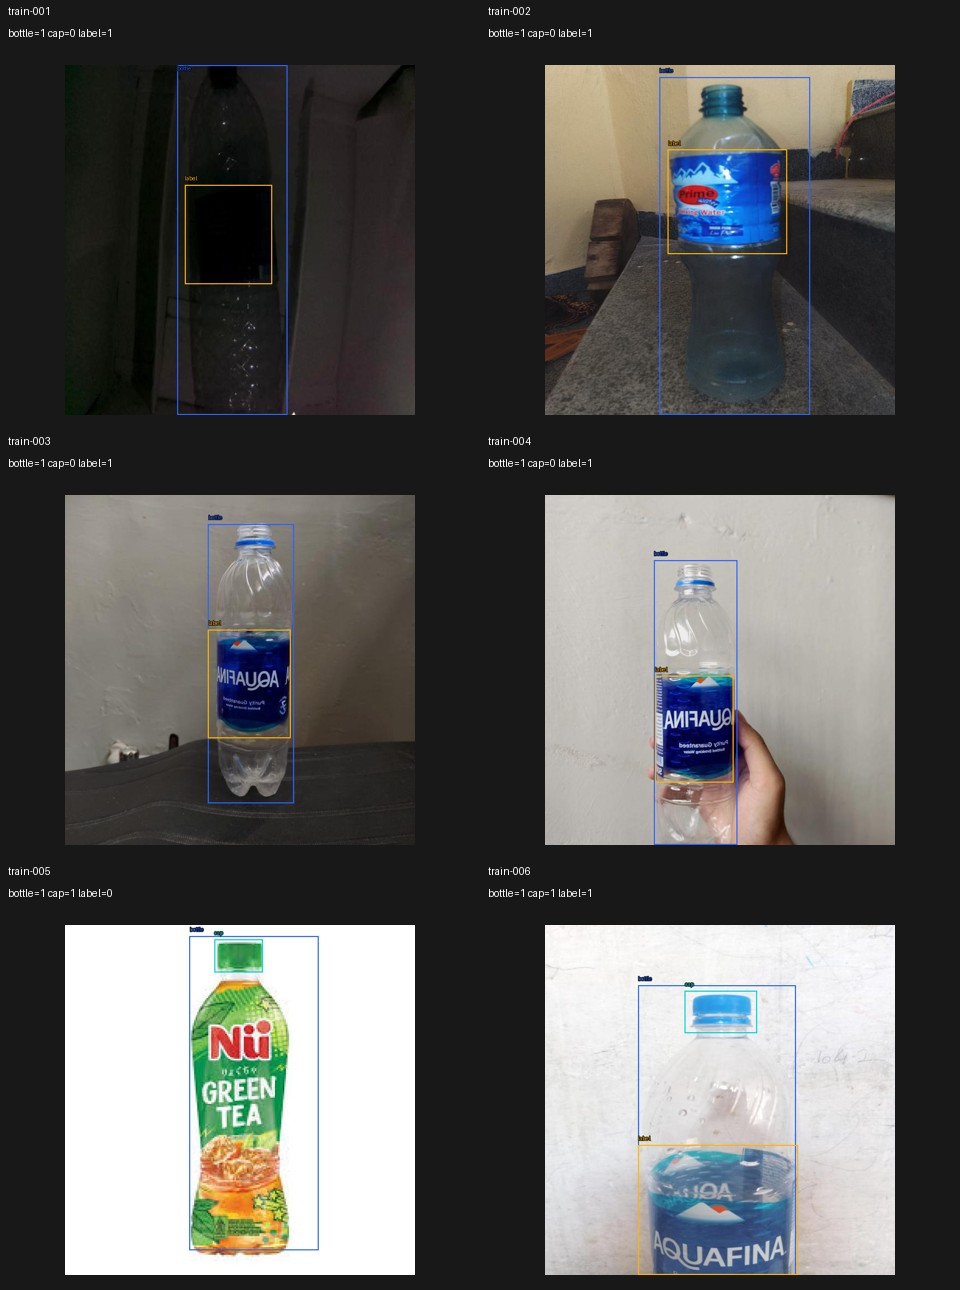

LABEL_AUDIT_SHEET: audit-sheet-02.jpg


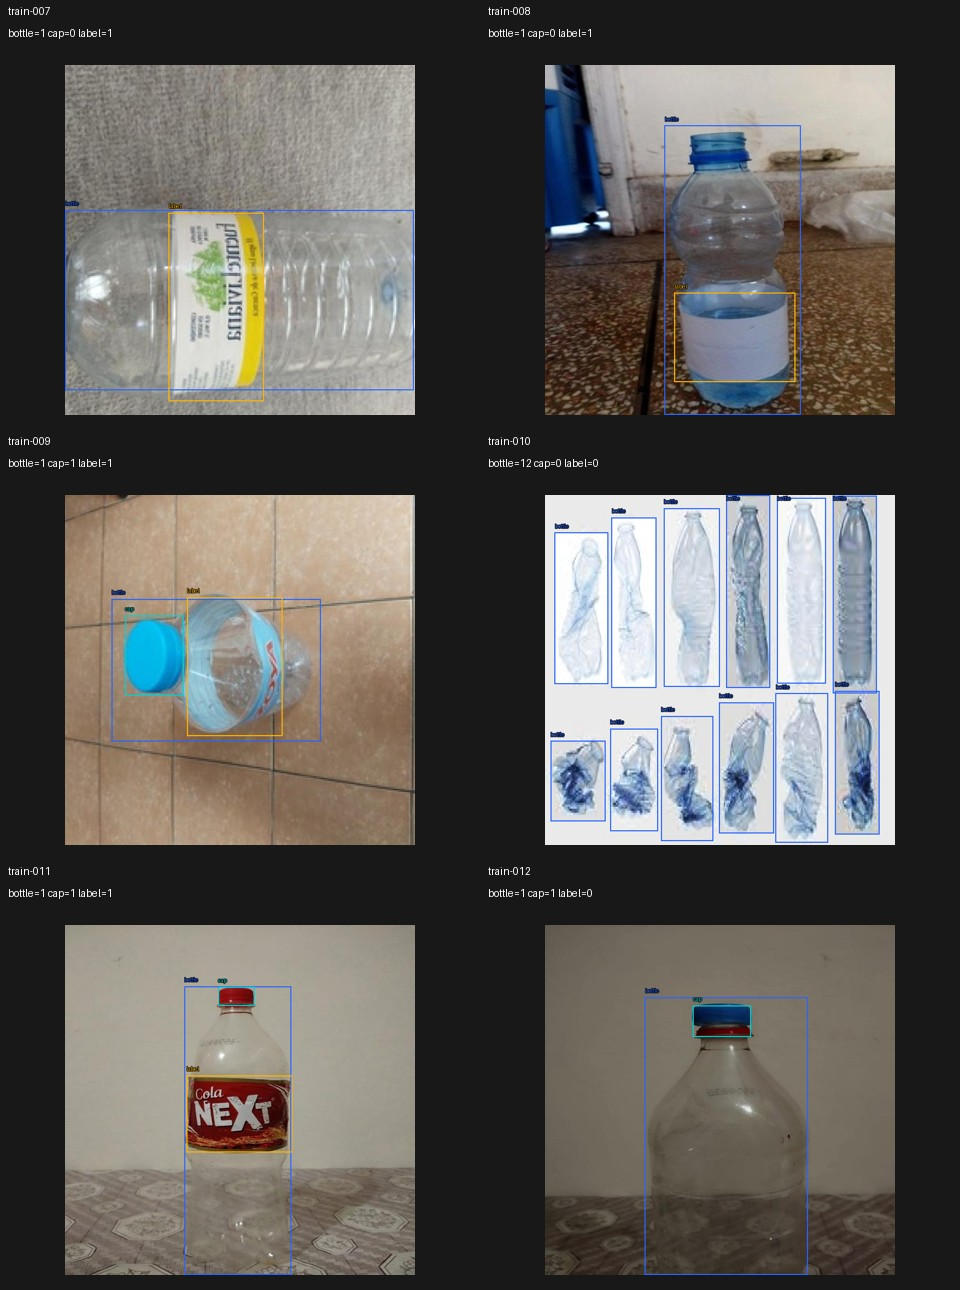

LABEL_AUDIT_SHEET: audit-sheet-03.jpg


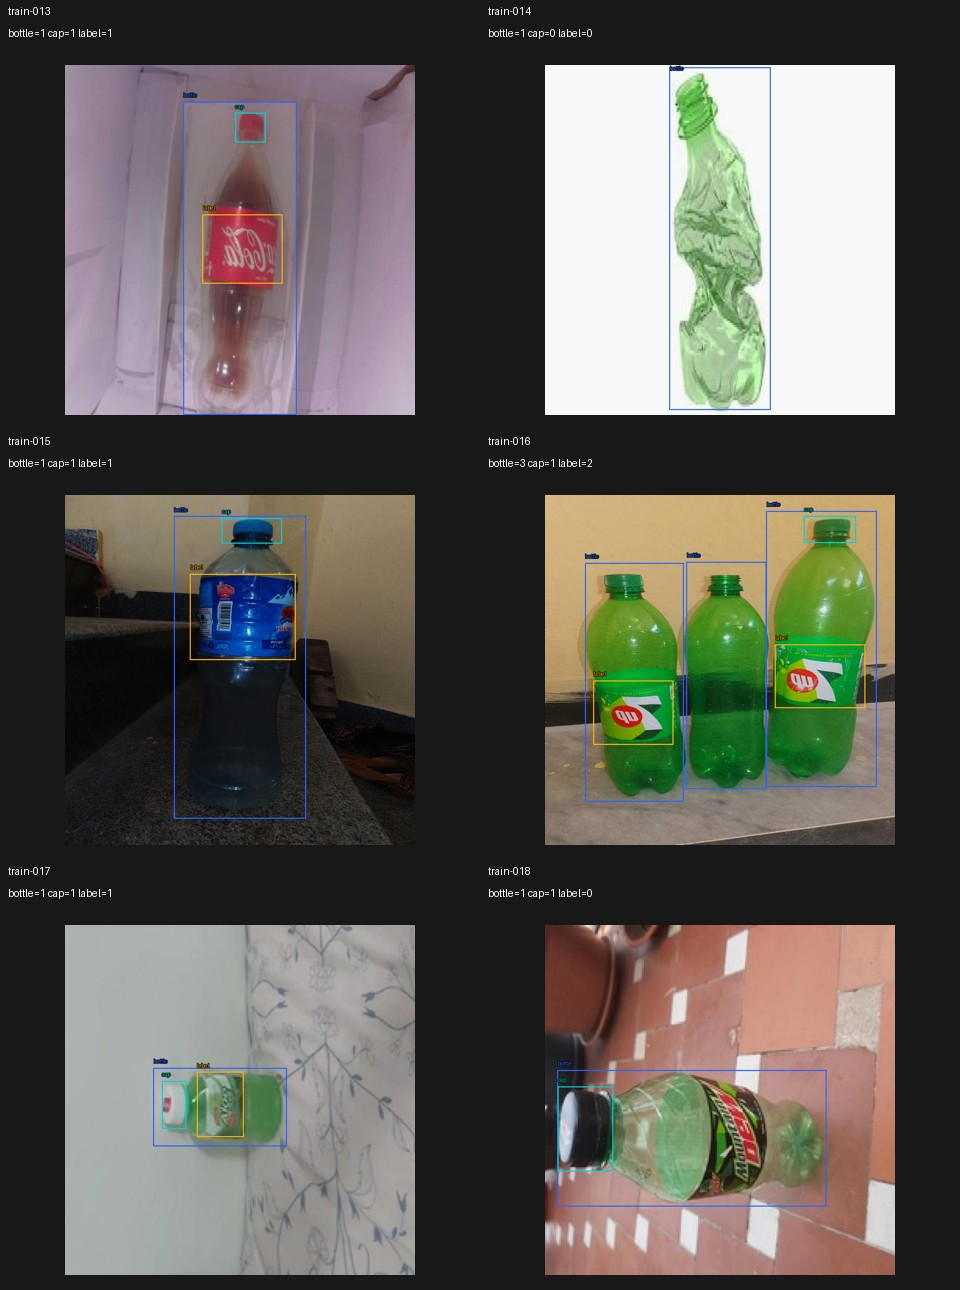

LABEL_AUDIT_SHEET: audit-sheet-04.jpg


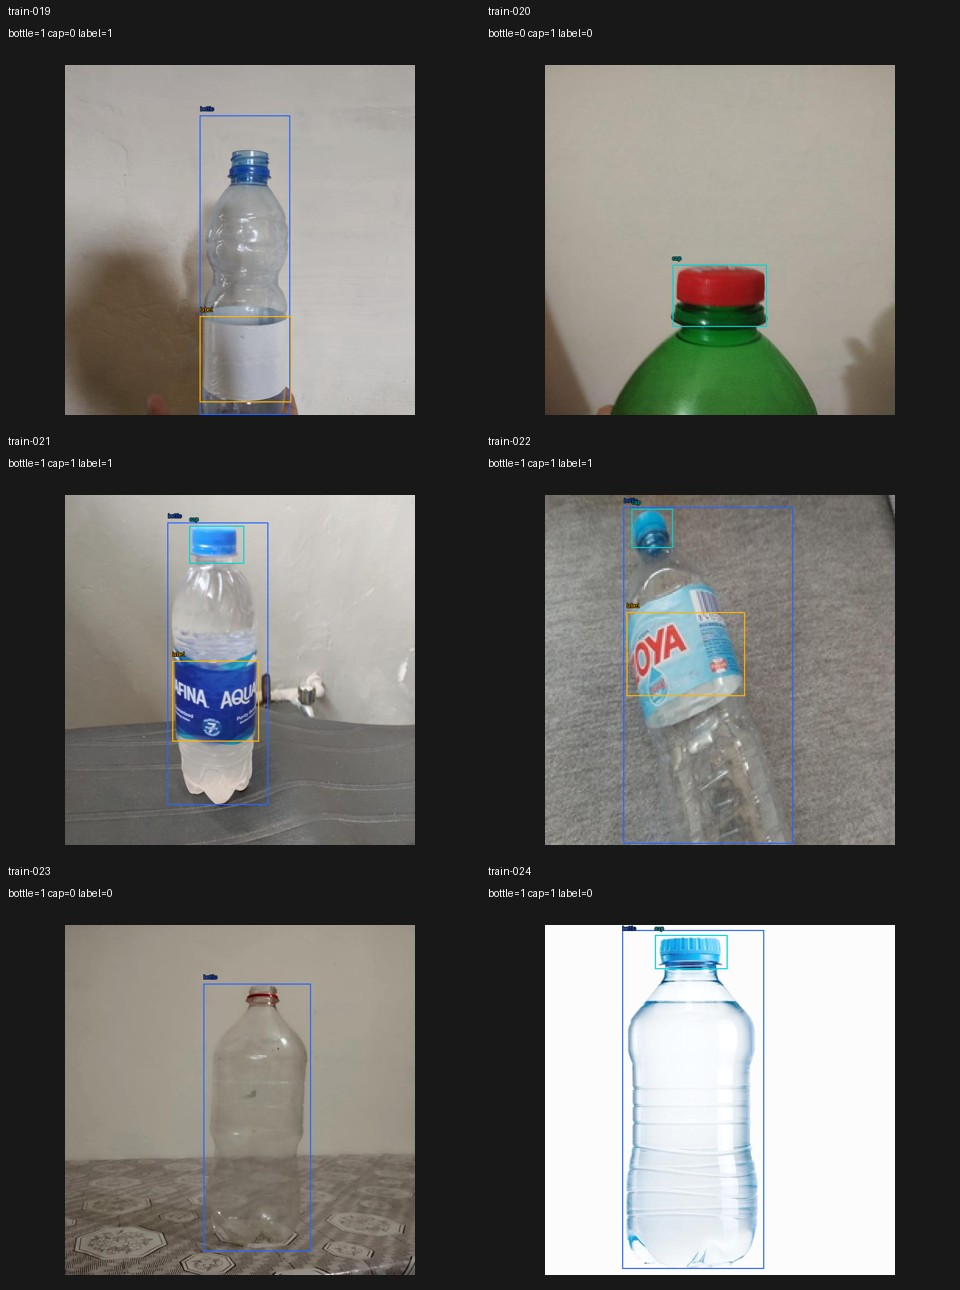

LABEL_AUDIT_SHEET: audit-sheet-05.jpg


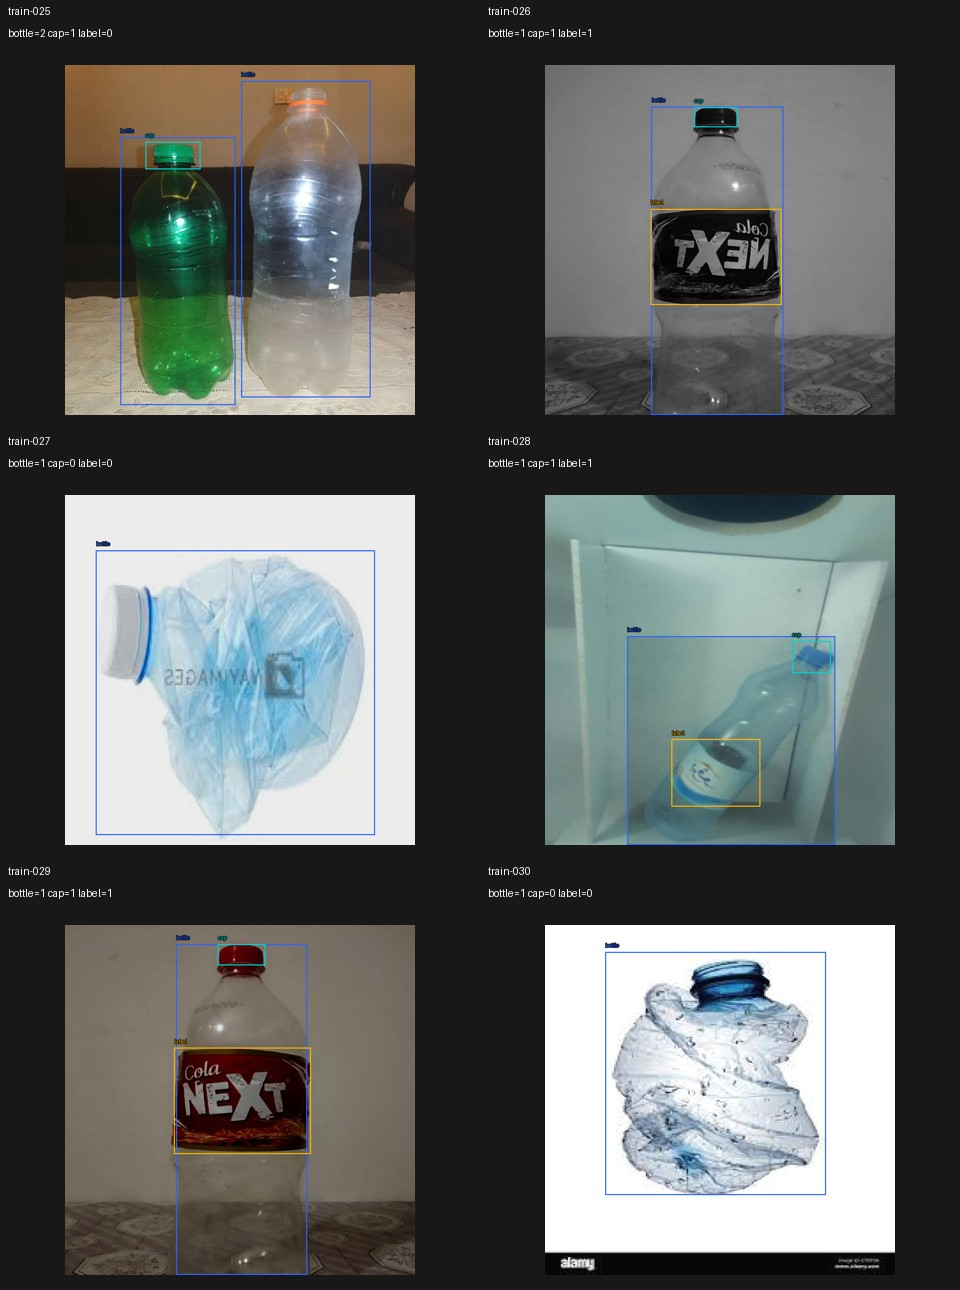

LABEL_AUDIT_SHEET: audit-sheet-06.jpg


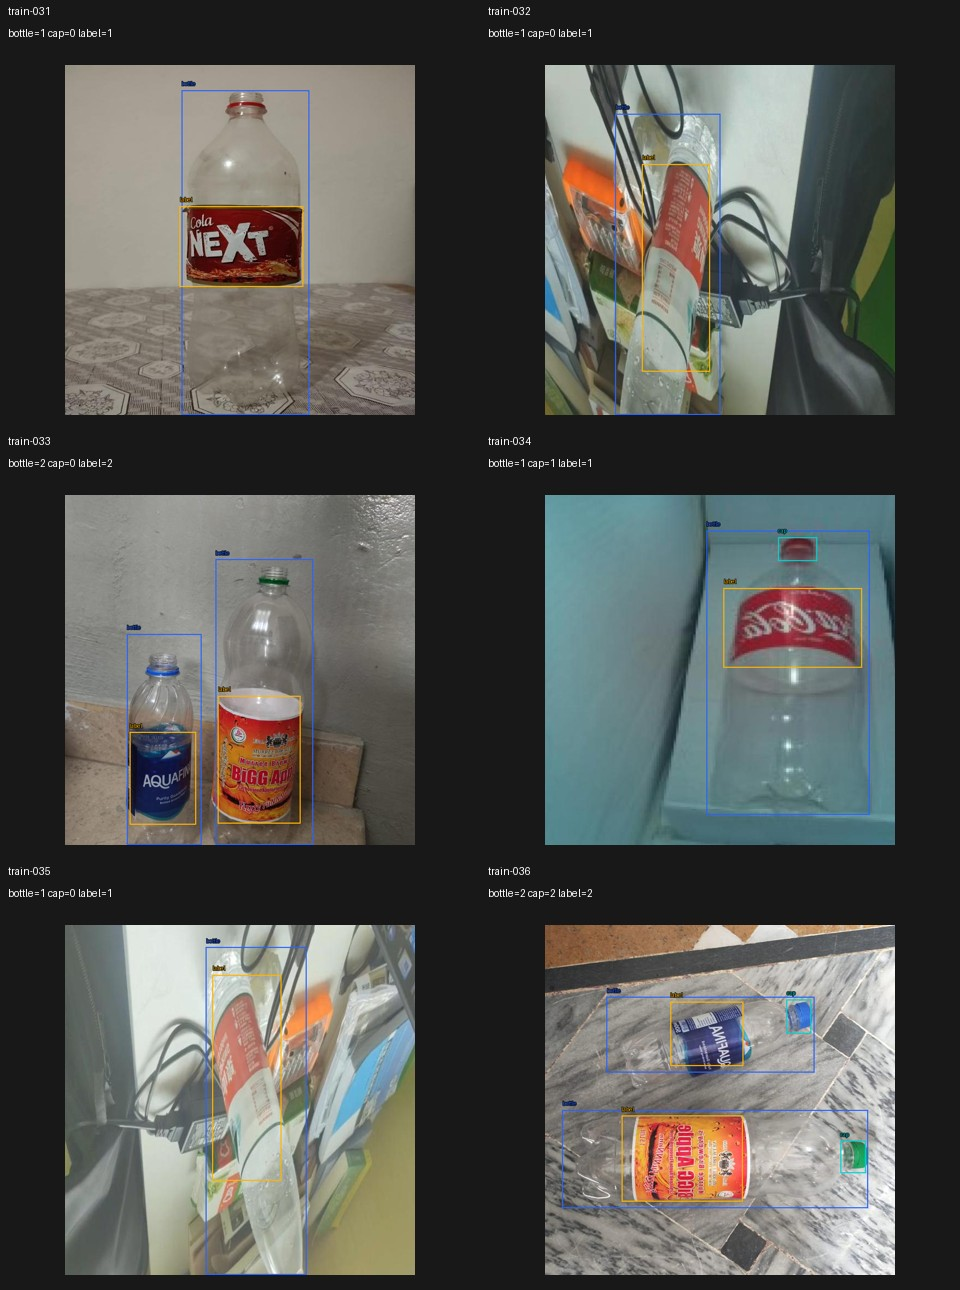

LABEL_AUDIT_SHEET: audit-sheet-07.jpg


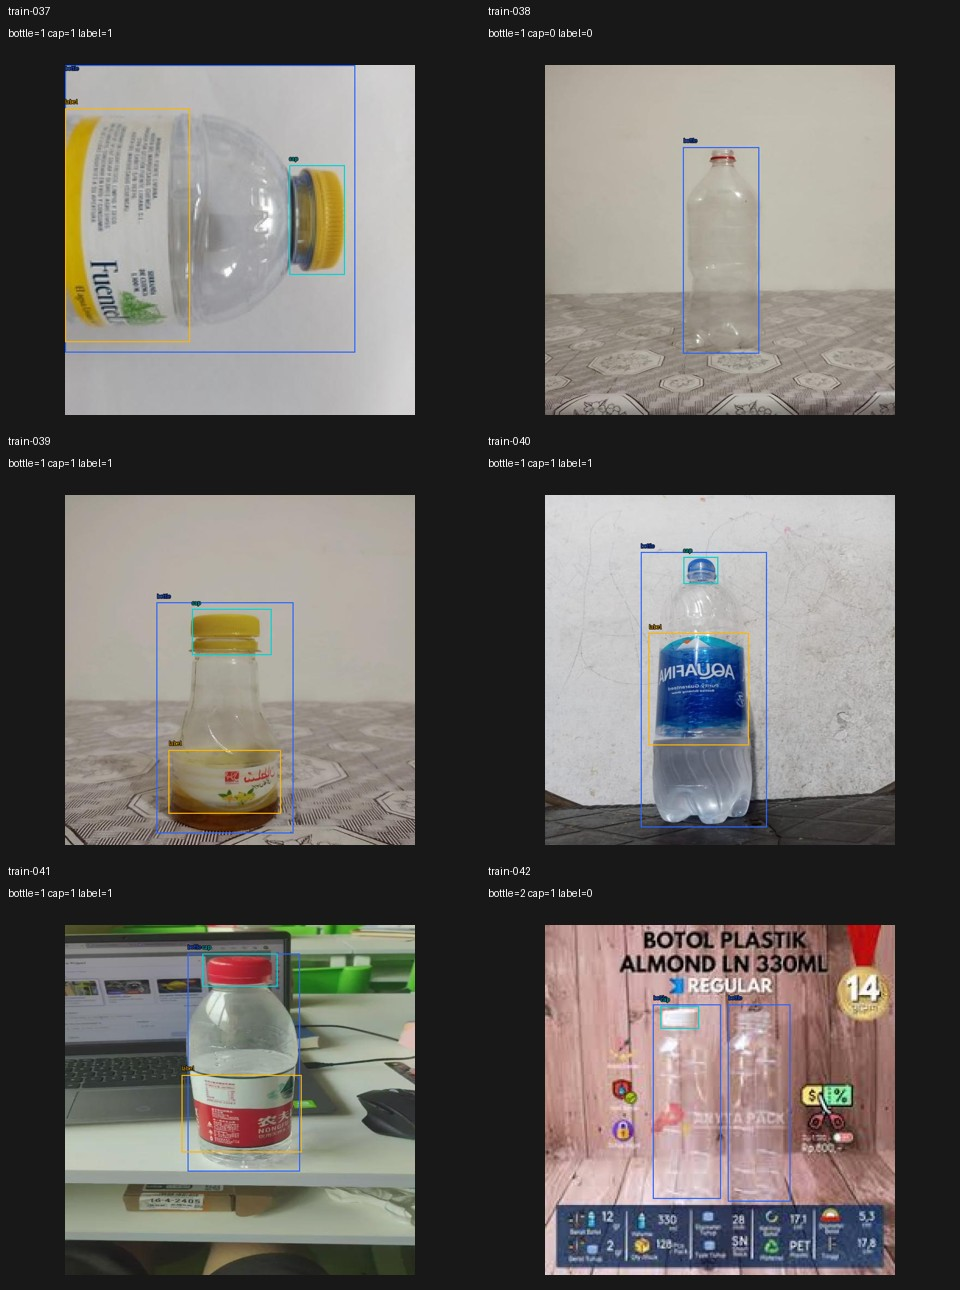

LABEL_AUDIT_SHEET: audit-sheet-08.jpg


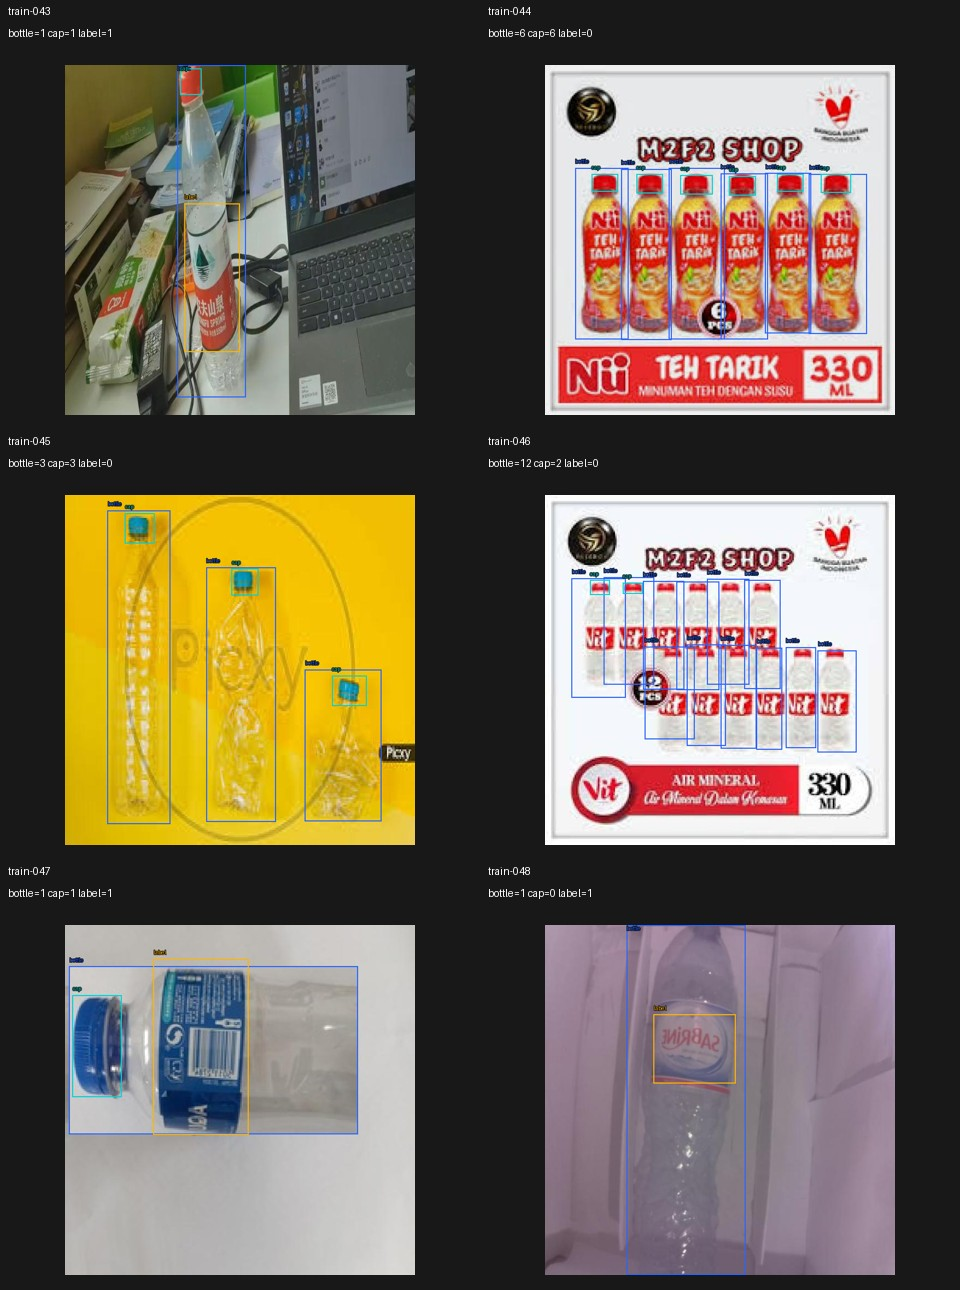

LABEL_AUDIT_SHEET: audit-sheet-09.jpg


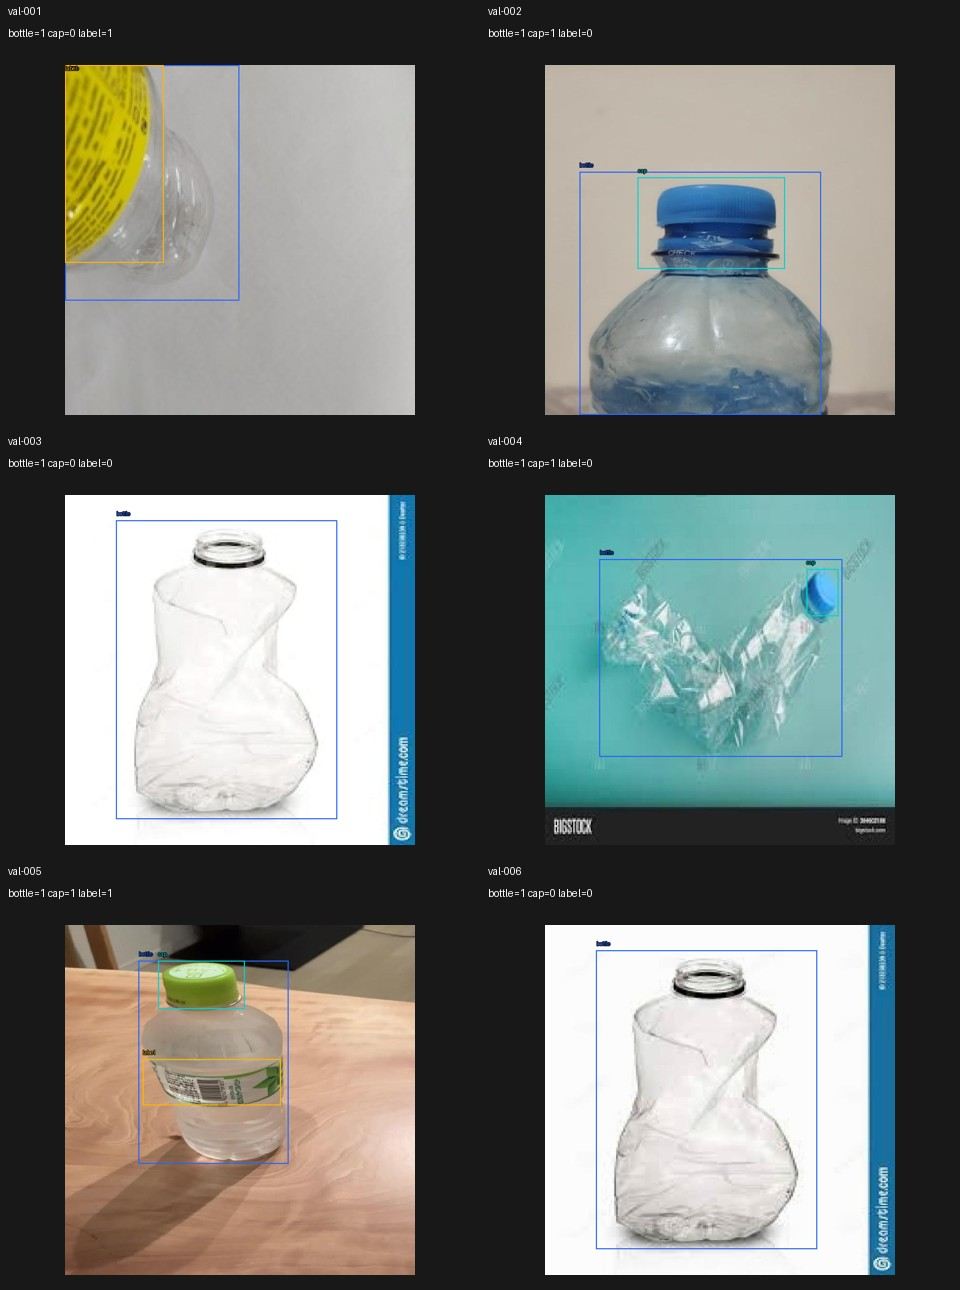

LABEL_AUDIT_SHEET: audit-sheet-10.jpg


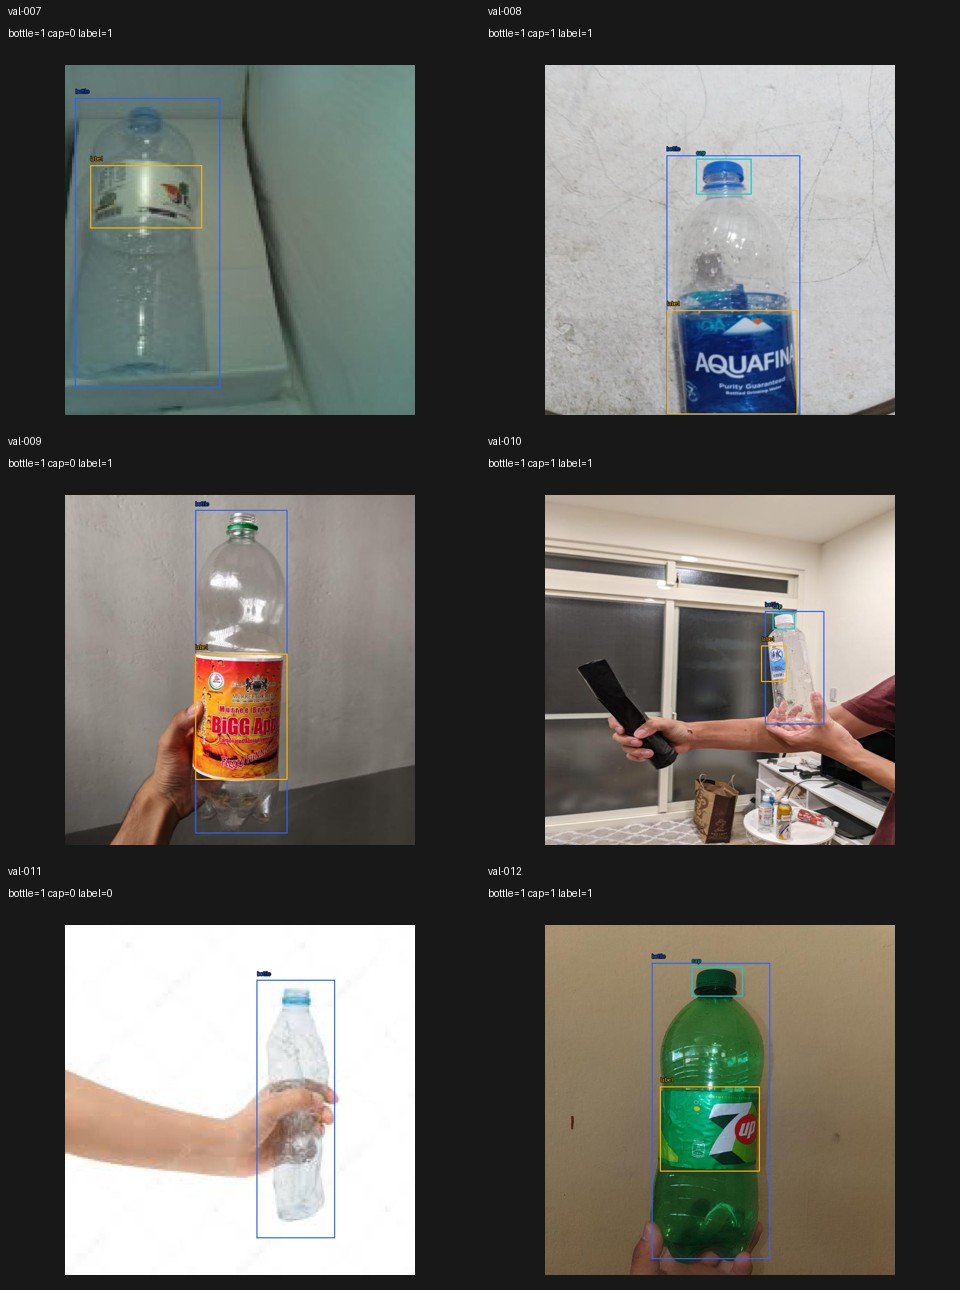

LABEL_AUDIT_SHEET: audit-sheet-11.jpg


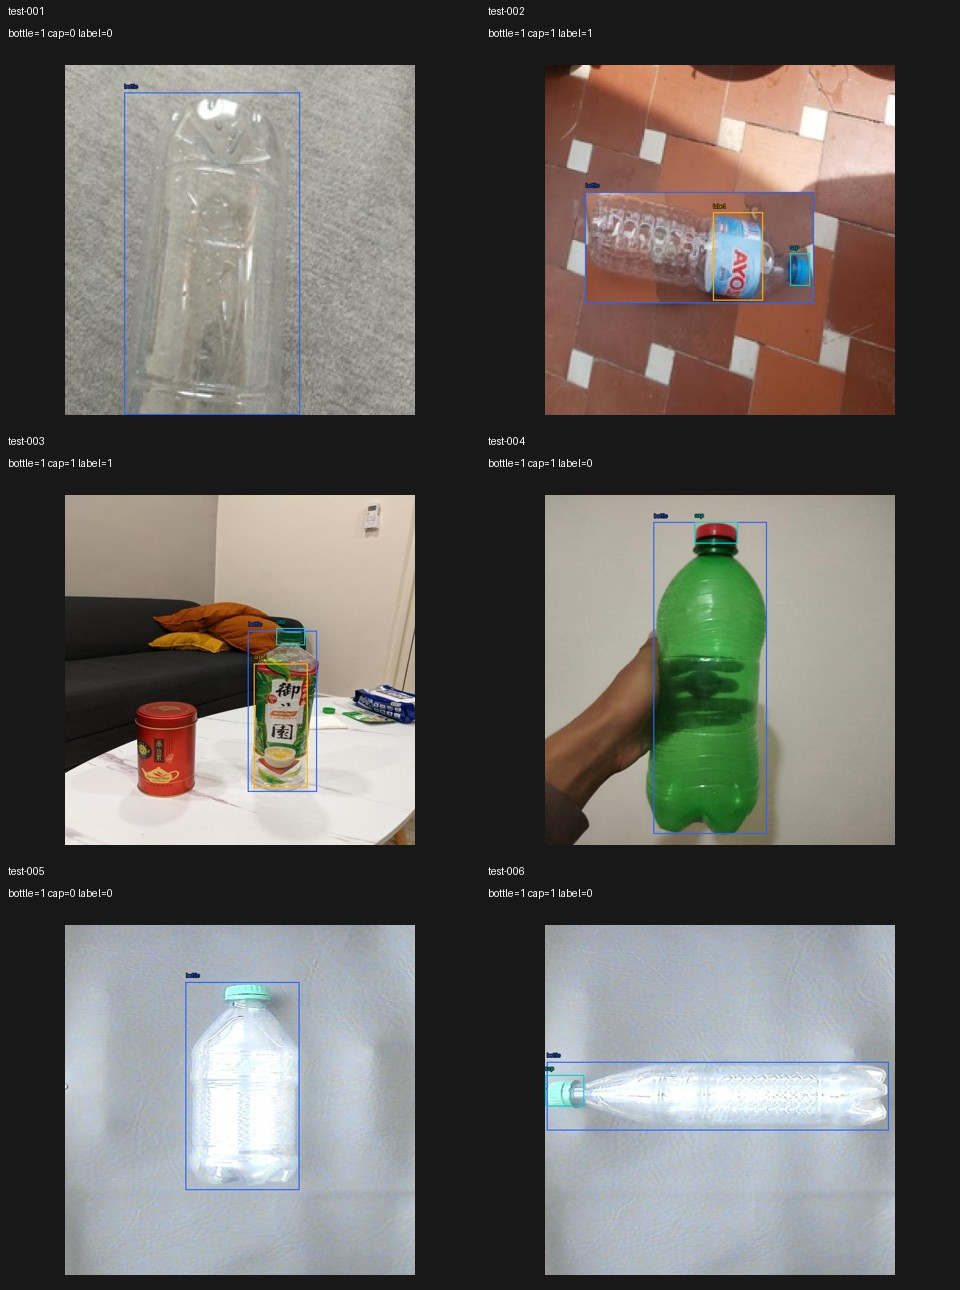

LABEL_AUDIT_SHEET: audit-sheet-12.jpg


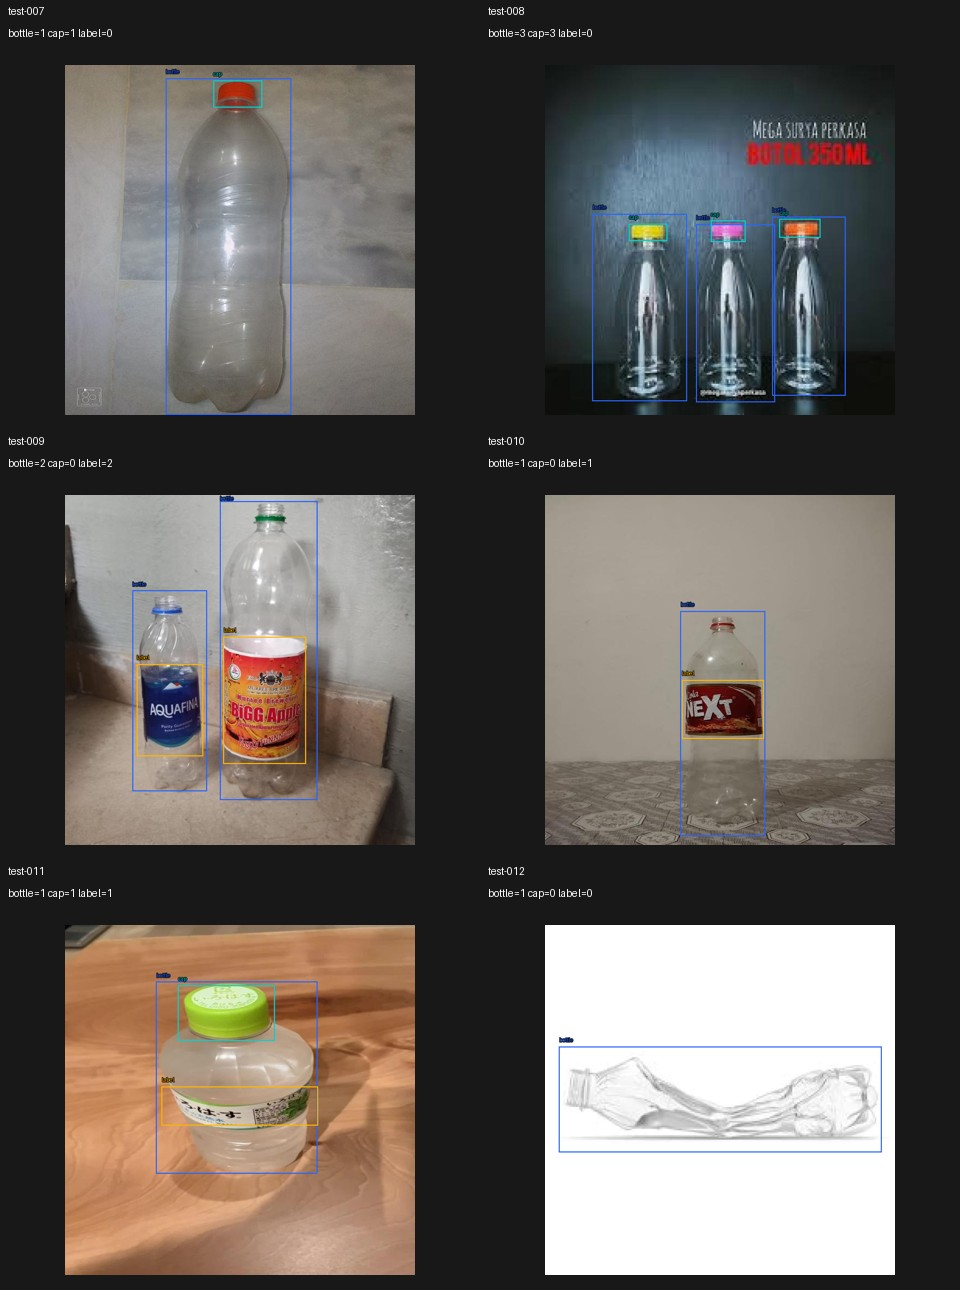

LABEL_AUDIT_PREVIEW_READY: lưu notebook bằng Ctrl+S để đọc lại các bảng ảnh.


In [3]:
# Cell 7 độc lập: xem ảnh và nhãn của candidate đã train, chỉ dùng CPU, không train.
import sys, json, hashlib, shutil, uuid, zipfile, math
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone

AUDIT_SAMPLE_COUNTS = {"train": 48, "val": 12, "test": 12}
AUDIT_EXPECTED_COUNTS = {"train": 3849, "val": 307, "test": 201}
AUDIT_EXPECTED_SHA = "28ee24280bce8184acd1cdf9a97e850788e908109bfa662efecb07a8a7b179eb"


def label_audit_sha(path):
    import hashlib
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def build_label_audit(archive, output, expected_sha, expected_counts, sample_counts):
    """Scan label records and render a reproducible sample; manual review stays pending."""
    import hashlib, io, json, math, zipfile
    from pathlib import Path, PurePosixPath
    from PIL import Image, ImageDraw, ImageFont, ImageOps

    archive, output = Path(archive), Path(output)
    if label_audit_sha(archive) != expected_sha:
        raise RuntimeError("ZIP không khớp dataset đã train.")
    if set(sample_counts) != set(expected_counts) or any(
        type(v) is not int or v < 1 for v in sample_counts.values()
    ):
        raise ValueError("Số mẫu từng split phải là số nguyên dương.")
    classes = {0: "bottle", 1: "cap", 2: "label"}
    colors = {0: (40, 100, 255), 1: (0, 210, 210), 2: (255, 180, 0)}
    counts = dict.fromkeys(expected_counts, 0)
    instances = {s: dict.fromkeys(classes.values(), 0) for s in expected_counts}
    empty_labels = dict.fromkeys(expected_counts, 0)
    label_issues, rows, samples, pages = [], {}, [], []
    with zipfile.ZipFile(archive) as z:
        names = [i.filename for i in z.infolist() if not i.is_dir()]
        files = set(names)
        if len(names) != len(files):
            raise RuntimeError("ZIP có tên file trùng nhau.")
        records = json.loads(z.read("retained-checksums.json"))
        seen = set()
        for record in records:
            split = record["split"]
            if split not in counts or record["image"] in seen:
                raise RuntimeError("Split hoặc image record không hợp lệ/trùng.")
            seen.add(record["image"])
            for key, prefix in (("image", "images"), ("label", "labels")):
                name = record[key]
                path = PurePosixPath(name)
                if (path.is_absolute() or ".." in path.parts or chr(92) in name or ":" in name
                        or path.parts[:2] != (prefix, split) or name not in files):
                    raise RuntimeError("Đường dẫn record không hợp lệ: " + name)
            raw = z.read(record["label"])
            if hashlib.sha256(raw).hexdigest() != record["label_sha256"]:
                raise RuntimeError("Nhãn không khớp checksum: " + record["label"])
            boxes, issues = [], []
            text = raw.decode("utf-8-sig")
            for line_number, line in enumerate(text.splitlines(), 1):
                if not line.strip():
                    continue
                try:
                    parts = line.split()
                    if len(parts) != 5:
                        raise ValueError("Cần 5 giá trị YOLO detection.")
                    cls = int(parts[0])
                    cx, cy, w, h = map(float, parts[1:])
                    if (cls not in classes or not all(math.isfinite(v) for v in (cx, cy, w, h))
                            or w <= 0 or h <= 0 or min(cx - w / 2, cy - h / 2) < -1e-6
                            or max(cx + w / 2, cy + h / 2) > 1 + 1e-6):
                        raise ValueError("Class hoặc box không hợp lệ.")
                    boxes.append((cls, cx, cy, w, h))
                    instances[split][classes[cls]] += 1
                except ValueError as exc:
                    issues.append(dict(line=line_number, reason=str(exc)))
            if issues:
                label_issues.append(dict(image=record["image"], label=record["label"], issues=issues))
            if not text.strip():
                empty_labels[split] += 1
            rows[record["image"]] = (boxes, issues)
            counts[split] += 1
        if counts != expected_counts:
            raise RuntimeError("Sai số ảnh của candidate: " + str(counts))
        listed = {r[k] for r in records for k in ("image", "label")}
        if listed != {n for n in names if n.startswith(("images/", "labels/"))}:
            raise RuntimeError("File ảnh/nhãn không khớp danh sách candidate.")
        output.mkdir(parents=True, exist_ok=False)
        try:
            font = ImageFont.truetype("DejaVuSans.ttf", 16)
        except OSError:
            font = ImageFont.load_default()
        tiles = []
        for split in expected_counts:
            candidates = [r for r in records if r["split"] == split]
            candidates.sort(key=lambda r: hashlib.sha256(("label-audit-v1:" + r["image"]).encode()).hexdigest())
            for number, record in enumerate(candidates[:sample_counts[split]], 1):
                review_id = "%s-%03d" % (split, number)
                raw = z.read(record["image"])
                if hashlib.sha256(raw).hexdigest() != record["image_sha256"]:
                    raise RuntimeError("Ảnh mẫu không khớp checksum: " + record["image"])
                with Image.open(io.BytesIO(raw)) as decoded:
                    original = decoded.convert("RGB")
                image = original.copy()
                image.thumbnail((800, 800))
                width, height = image.size
                draw = ImageDraw.Draw(image)
                boxes, issues = rows[record["image"]]
                for cls, cx, cy, w, h in boxes:
                    x1, y1 = min(width - 1, max(0, (cx - w / 2) * width)), min(height - 1, max(0, (cy - h / 2) * height))
                    x2, y2 = min(width - 1, max(0, (cx + w / 2) * width)), min(height - 1, max(0, (cy + h / 2) * height))
                    draw.rectangle((x1, y1, x2, y2), outline=colors[cls], width=2)
                    draw.text((x1, max(0, y1 - 18)), classes[cls], font=font, fill=colors[cls], stroke_width=1, stroke_fill="black")
                filename = review_id + ".jpg"
                image.save(output / filename, quality=90)
                tile = Image.new("RGB", (480, 430), "#181818")
                thumb = ImageOps.contain(image, (472, 350))
                tile.paste(thumb, ((480 - thumb.width) // 2, 65 + (350 - thumb.height) // 2))
                td = ImageDraw.Draw(tile)
                td.text((8, 5), review_id + (" INVALID LABEL" if issues else ""), font=font, fill="red" if issues else "white")
                summary = " ".join("%s=%d" % (classes[k], sum(b[0] == k for b in boxes)) for k in classes)
                td.text((8, 27), summary, font=font, fill="white")
                if not boxes:
                    td.text((8, 47), "NO VALID BOX - REVIEW REQUIRED", font=font, fill="orange")
                tiles.append(tile)
                samples.append(dict(id=review_id, split=split, image=record["image"], label=record["label"],
                                    image_sha256=record["image_sha256"], label_sha256=record["label_sha256"],
                                    overlay=filename, review_status="pending", label_issues=issues,
                                    box_counts={classes[k]: sum(b[0] == k for b in boxes) for k in classes}))
        for first in range(0, len(tiles), 6):
            sheet = Image.new("RGB", (960, 1290), "#181818")
            for j, tile in enumerate(tiles[first:first + 6]):
                sheet.paste(tile, ((j % 2) * 480, (j // 2) * 430))
            name = "audit-sheet-%02d.jpg" % (len(pages) + 1)
            sheet.save(output / name, quality=90)
            pages.append(name)
    report = dict(dataset_sha256=expected_sha, counts=counts, classes=classes,
                  label_instances=instances, empty_label_files=empty_labels, label_issues=label_issues,
                  image_checksum_scope="Selected preview images only; archive hash and all label hashes checked",
                  requested_sample_counts=sample_counts, sampled_images=len(samples), sheets=pages, samples=samples,
                  review_status="pending", accuracy=None,
                  scope="Manual review sample, not a full annotation audit or model evaluation")
    (output / "label-audit.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
    return report


def run_label_audit():
    if sys.platform != "linux" or not Path("/content").is_dir():
        raise RuntimeError("Chọn Colab remote kernel; không tải dataset về Windows.")
    from google.colab import drive
    from IPython.display import Image as DisplayImage, display
    audit_drive = Path("/content/drive/MyDrive")
    if not audit_drive.is_dir():
        drive.mount("/content/drive")
    run = audit_drive / "BottleQC/training-runs/bottleqc-yolo11n-640-v1"
    complete = json.loads((run / "TRAIN_COMPLETE.json").read_text())
    if complete["binding"].get("dataset_sha256") != AUDIT_EXPECTED_SHA:
        raise RuntimeError("Dataset không khớp model đã train.")
    candidate = audit_drive / "BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5"
    source = candidate / "prepared-candidate.zip"
    work = Path("/content/bottleqc-label-audit")
    work.mkdir(exist_ok=True)
    print("LABEL_AUDIT_ENV: Colab; chỉ xử lý CPU, không gọi model/train/CUDA.", flush=True)
    print("LABEL_AUDIT_SOURCE:", source, "bytes=", source.stat().st_size, flush=True)
    local_zip = work / (AUDIT_EXPECTED_SHA[:16] + ".zip")
    if not local_zip.is_file() or label_audit_sha(local_zip) != AUDIT_EXPECTED_SHA:
        part = local_zip.with_suffix(".zip.part")
        try:
            shutil.copyfile(source, part)
            if label_audit_sha(part) != AUDIT_EXPECTED_SHA:
                raise RuntimeError("ZIP copy từ Drive không khớp SHA.")
            part.replace(local_zip)
        finally:
            part.unlink(missing_ok=True)
    review_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
    local = work / review_id
    report = build_label_audit(local_zip, local, AUDIT_EXPECTED_SHA, AUDIT_EXPECTED_COUNTS, AUDIT_SAMPLE_COUNTS)
    durable = run / "dataset-audits" / review_id
    durable.mkdir(parents=True, exist_ok=False)
    for item in sorted(local.iterdir()):
        destination = durable / item.name
        shutil.copyfile(item, destination)
        if label_audit_sha(item) != label_audit_sha(destination):
            raise RuntimeError("Copy artifact sai SHA: " + str(destination))
    print("LABEL_AUDIT_SAVED:", durable)
    print("LABEL_AUDIT_COUNTS:", report["counts"], "samples=", report["sampled_images"])
    print("LABEL_ISSUES:", len(report["label_issues"]), "images; manual_review=pending")
    print("BOX_COLORS: bottle=blue, cap=cyan, label=orange")
    for page in report["sheets"]:
        print("LABEL_AUDIT_SHEET:", page)
        display(DisplayImage(filename=str(local / page)))
    print("LABEL_AUDIT_PREVIEW_READY: lưu notebook bằng Ctrl+S để đọc lại các bảng ảnh.")


run_label_audit()


## 8 — Ảnh gốc và hồ sơ sửa nhãn v2 (CPU, không train)

**Chỉ chạy cell 8** trên CPU Colab; cell độc lập, không cần chạy lại 1–7.
Đây là bước bắt đầu chuẩn bị dữ liệu v2: lấy đúng ảnh gốc của các ID đã phát hiện vấn đề ở cell 7.
Cell kiểm tra SHA dataset, binding của model, checksum 12 bảng ảnh đã review và ánh xạ ID → file gốc.

Xuất từng ảnh gốc, box hiện tại, kích thước ảnh và nội dung YOLO để kiểm tra/vẽ lại chính xác.
**Các box là nhãn có sẵn của dataset, không phải dự đoán model. SHA khớp chỉ xác nhận đúng file, không xác nhận nhãn đúng.**
Giữ nguyên nguồn, chưa điền nhãn từ model hoặc preview nhỏ. Chưa xác nhận trường hợp nào thì decision=pending.
Các ID này là danh sách đã phát hiện, không phải hạn mức số ảnh cần sửa/loại hay kiểm tra đầy đủ dataset.

Kết quả ở run/dataset-v2-preparation/<id>/. V2_REPAIR_SAVED chỉ xác nhận xuất hồ sơ review;
**training_ready=False**, chưa có candidate v2 hoặc model mới.
Đợi **V2_REPAIR_PREVIEW_READY**, Ctrl+S rồi đọc output ảnh gốc để tiếp tục sửa nhãn.


Mounted at /content/drive
V2_REPAIR_ENV: Colab CPU tasks, no model/train/CUDA
V2_REPAIR_SOURCE: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5/prepared-candidate.zip bytes= 151268228
V2_REPAIR_SAVED: /content/drive/MyDrive/BottleQC/training-runs/bottleqc-yolo11n-640-v1/dataset-v2-preparation/20261104T173852Z-f54a30
V2_REPAIR_STATUS: REVIEW_PACK_ONLY; training_ready=False; no annotations changed
V2_REPAIR_ENTRY: {"id": "train-005", "split": "train", "image": "images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.fdf9b69e6b450b33e2a8d5c8146e8d40.jpg", "label": "labels/train/images-2024-04-11T000613-929_jpeg_jpg.rf.fdf9b69e6b450b33e2a8d5c8146e8d40.txt", "image_sha256": "4138d13c41550cbf6789cc8e1e72006d77bb8ef8f2ca724834111810f43cf306", "label_sha256": "edbbc4e99199a8e4d3d19bd2266fe2f84b37acbfc56442dff57fca945bd76ca0", "width": 640, "height": 640, "original_yolo": "0 0.53984375 0.4796875 0.36875 0.896875

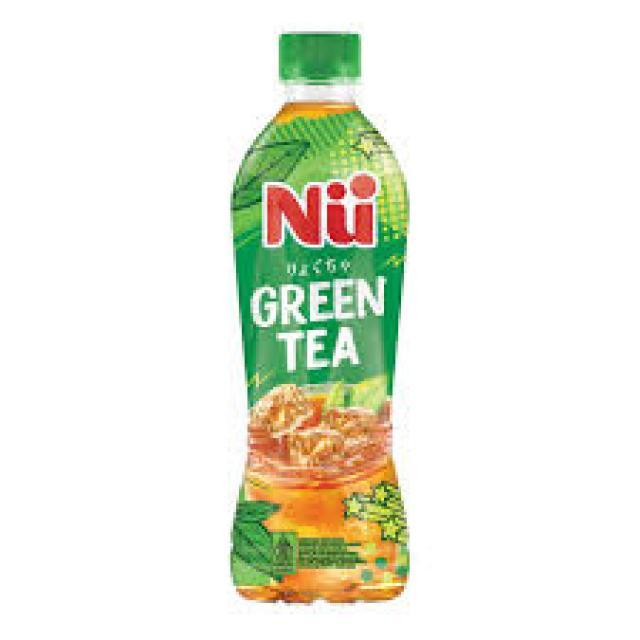

CURRENT_LABELS: train-005


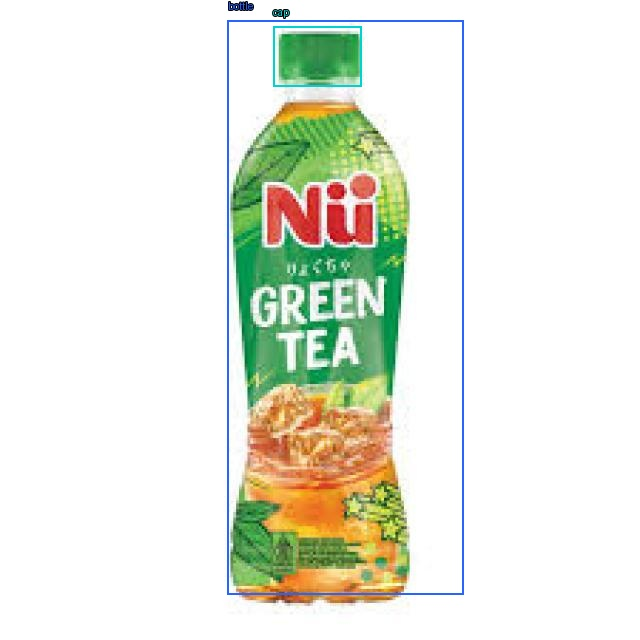

V2_REPAIR_ENTRY: {"id": "train-016", "split": "train", "image": "images/train/WhatsApp-Image-2024-06-22-at-5-48-34-PM_jpeg.rf.faee8614c45c528b2c272b7370f2cd60.jpg", "label": "labels/train/WhatsApp-Image-2024-06-22-at-5-48-34-PM_jpeg.rf.faee8614c45c528b2c272b7370f2cd60.txt", "image_sha256": "b11719d35960818d2aede89c375dee6a2f22988e84b5d99c13f48921315c8d50", "label_sha256": "bcac55d93776c68b0db8f53f37a81a4d470752ad588a0df3cbe85cbaa0f114c0", "width": 640, "height": 640, "original_yolo": "0 0.78984375 0.4390625 0.315625 0.7875\n0 0.51796875 0.515625 0.22734375 0.64921875\n0 0.2546875 0.53515625 0.28125 0.68203125\n2 0.7859375 0.51796875 0.2578125 0.18125\n2 0.25234375 0.621875 0.22734375 0.18359375\n1 0.8140625 0.0984375 0.1484375 0.07734375\n", "source_file": "train-016-source.jpg", "current_overlay": "train-016-current-labels.jpg", "original_label_file": "train-016-original.txt", "finding": "Three bottles, one cap annotation; left cap appears present; middle mouth unresolved", "decision"

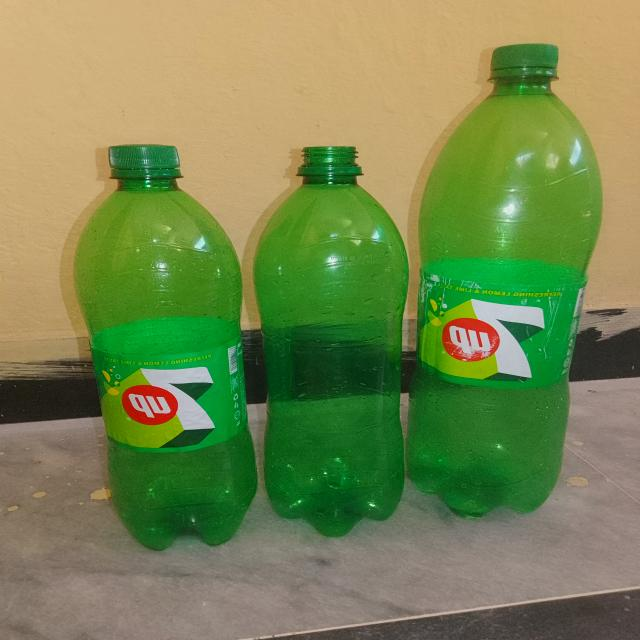

CURRENT_LABELS: train-016


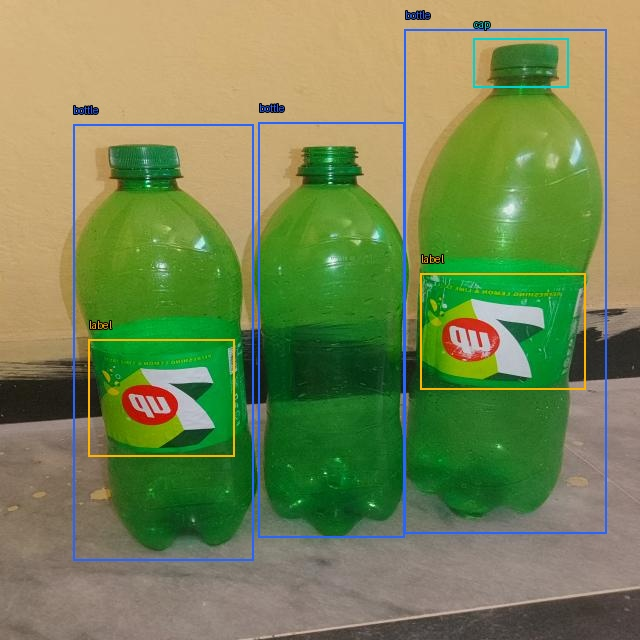

V2_REPAIR_ENTRY: {"id": "train-018", "split": "train", "image": "images/train/Plastico_35_jpg.rf.d97bbb96fd11c6f334b4195cbd5f5ca1.jpg", "label": "labels/train/Plastico_35_jpg.rf.d97bbb96fd11c6f334b4195cbd5f5ca1.txt", "image_sha256": "6e18a14ef66a64c6c415cceb8dcecf607769e88415a9d045365fc3c5b18e1794", "label_sha256": "1ca5dbd302f1c6e02277362c931ccb97c624d0c568f09e95f649a1b629593b35", "width": 640, "height": 640, "original_yolo": "0 0.41953125 0.60859375 0.76875 0.3890625\n1 0.115625 0.58203125 0.15859375 0.2421875\n", "source_file": "train-018-source.jpg", "current_overlay": "train-018-current-labels.jpg", "original_label_file": "train-018-original.txt", "finding": "label=0 despite visible Mountain Dew label", "decision": "pending", "replacement_yolo": null}
SOURCE: train-018


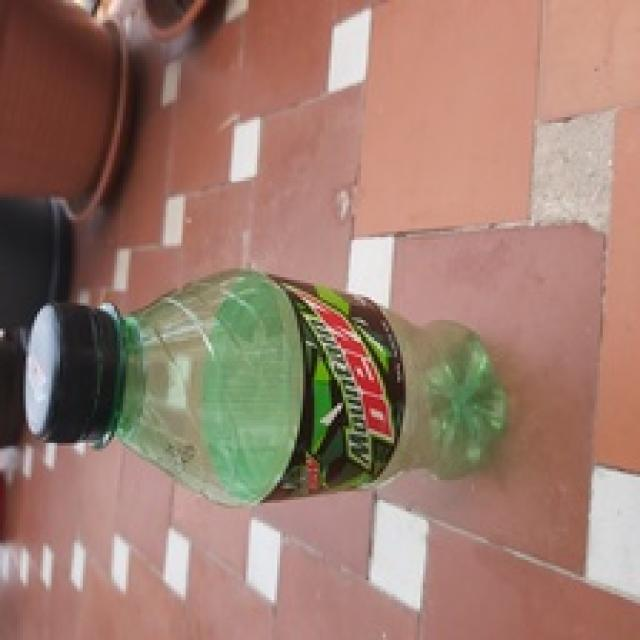

CURRENT_LABELS: train-018


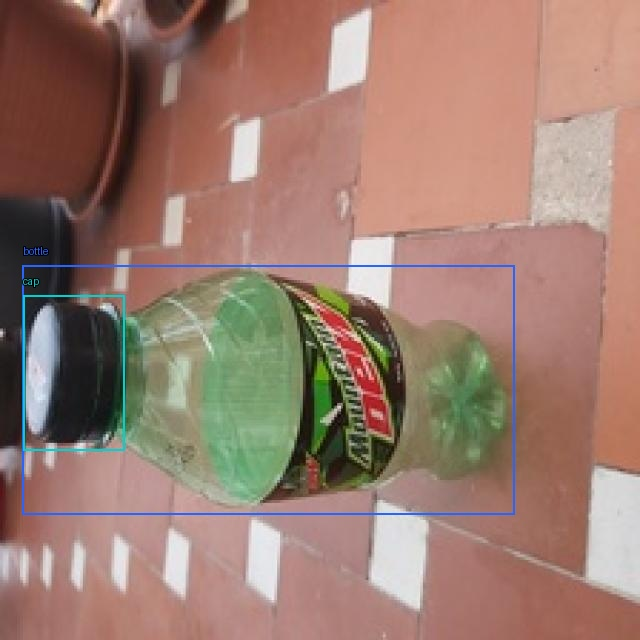

V2_REPAIR_ENTRY: {"id": "train-020", "split": "train", "image": "images/train/IMG-20240622-WA0103_jpg.rf.bb850979267866d536c364a3189a9b2b.jpg", "label": "labels/train/IMG-20240622-WA0103_jpg.rf.bb850979267866d536c364a3189a9b2b.txt", "image_sha256": "8eb9b68d90e4207d533d08744242a97f93d77a8c9acc579fd34cfa9994954b34", "label_sha256": "d4e52e0665aa8c8bd9fbdaaac47c2fd34fa7aff445816439608aad33f429168a", "width": 640, "height": 640, "original_yolo": "1 0.49921875 0.659375 0.26953125 0.17734375\n", "source_file": "train-020-source.jpg", "current_overlay": "train-020-current-labels.jpg", "original_label_file": "train-020-original.txt", "finding": "Close-up cap and partial bottle, bottle=0; clarify truncated-bottle annotation policy", "decision": "pending", "replacement_yolo": null}
SOURCE: train-020


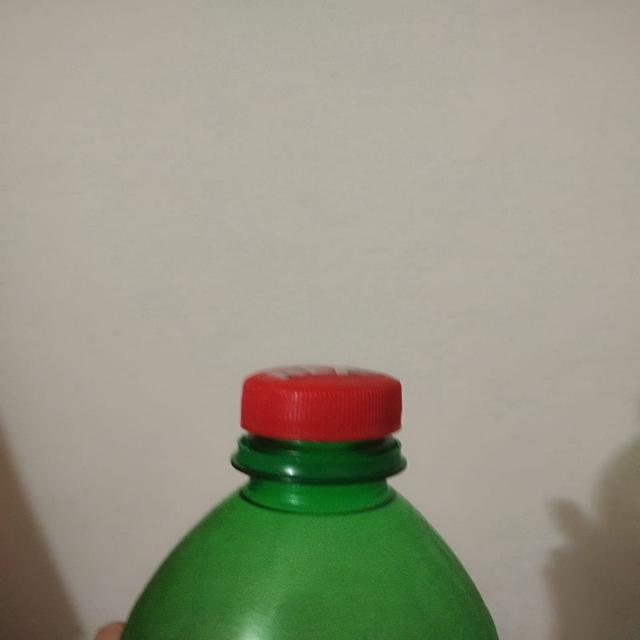

CURRENT_LABELS: train-020


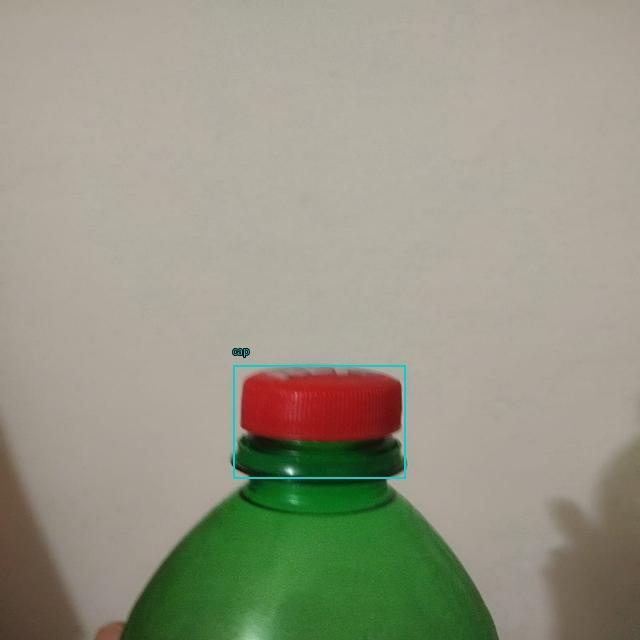

V2_REPAIR_ENTRY: {"id": "train-027", "split": "train", "image": "images/train/crushed_plastic_bottle76_jpg.rf.f7c98d72a8c4b6b2e1053773c3aa7f20.jpg", "label": "labels/train/crushed_plastic_bottle76_jpg.rf.f7c98d72a8c4b6b2e1053773c3aa7f20.txt", "image_sha256": "d76a798983f079974925386b5743f958d13fd760d9b3b4affb9fd0747df13ded", "label_sha256": "387cd9ffd0abe4083c35ea979f83bd39917fbcd02b614687c4f3041334739fd0", "width": 640, "height": 640, "original_yolo": "0 0.48671875 0.5640625 0.7953125 0.8125\n", "source_file": "train-027-source.jpg", "current_overlay": "train-027-current-labels.jpg", "original_label_file": "train-027-original.txt", "finding": "cap=0 despite apparently visible white cap on crushed bottle", "decision": "pending", "replacement_yolo": null}
SOURCE: train-027


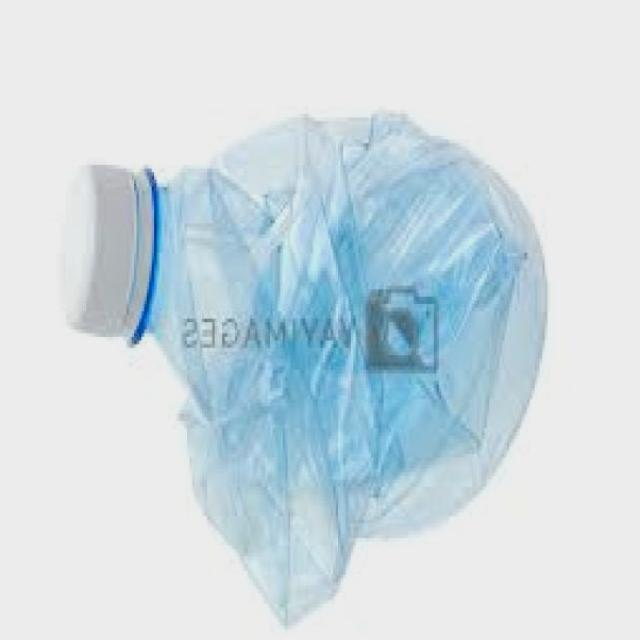

CURRENT_LABELS: train-027


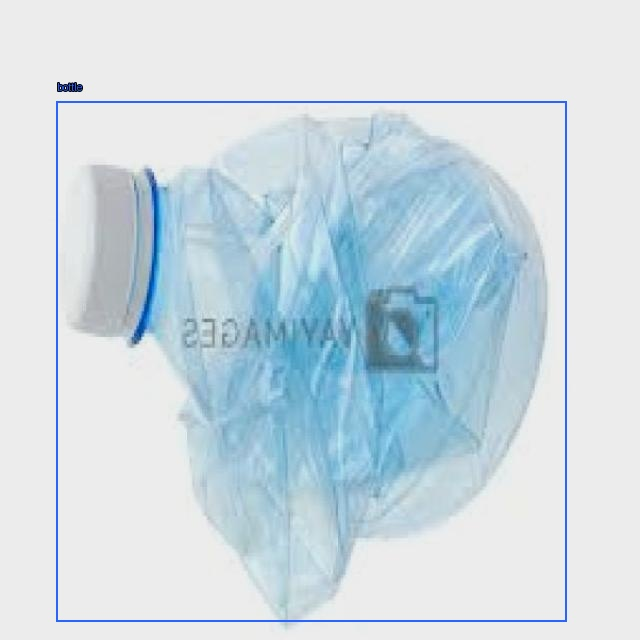

V2_REPAIR_ENTRY: {"id": "train-044", "split": "train", "image": "images/train/images-82-_jpeg_jpg.rf.2507b61e1295a17872b07b45ad24b28b.jpg", "label": "labels/train/images-82-_jpeg_jpg.rf.2507b61e1295a17872b07b45ad24b28b.txt", "image_sha256": "756e98817b51d27c90191c61d0a632cb4df0f7bda794ca319823d93769708883", "label_sha256": "e822d13781e25a6f424e88ba47071d09ecda50faf06509fa276b8d11ee6a10a2", "width": 640, "height": 640, "original_yolo": "0 0.1625 0.5390625 0.15234375 0.4890625\n0 0.28984375 0.540625 0.14453125 0.4875\n0 0.43359375 0.5390625 0.15859375 0.4890625\n0 0.56953125 0.546875 0.13515625 0.4734375\n0 0.69453125 0.5375 0.13046875 0.45625\n0 0.83671875 0.5390625 0.16484375 0.45625\n1 0.17109375 0.33671875 0.07578125 0.05\n1 0.29921875 0.3390625 0.07578125 0.0546875\n1 0.4328125 0.3421875 0.09140625 0.0546875\n1 0.5640625 0.34453125 0.07578125 0.0546875\n1 0.70078125 0.33671875 0.07578125 0.05\n1 0.83125 0.33828125 0.08671875 0.05234375\n", "source_file": "train-044-source.jpg", "cur

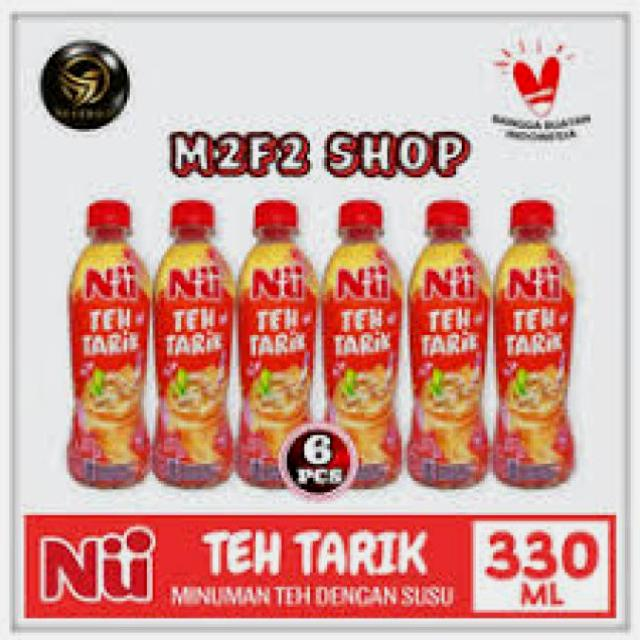

CURRENT_LABELS: train-044


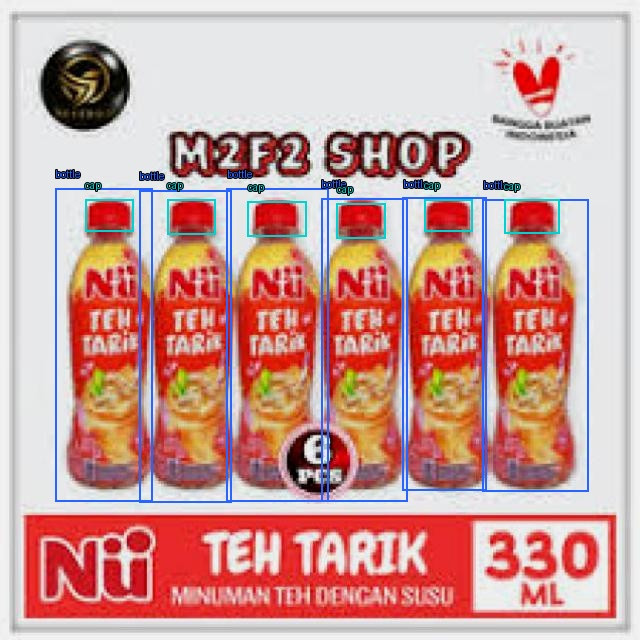

V2_REPAIR_ENTRY: {"id": "train-046", "split": "train", "image": "images/train/images-53-_jpeg_jpg.rf.7033868f7db98f546c138edc1ab07510.jpg", "label": "labels/train/images-53-_jpeg_jpg.rf.7033868f7db98f546c138edc1ab07510.txt", "image_sha256": "7dcd11550fffbe669c2a67f6cad9f25a4fbd86d618d3bed7f94ca11cb86f5fcf", "label_sha256": "09486e23ee2c496d1c5231cd76cc50c15f57fc5584ae6cca2460b414efa820b6", "width": 640, "height": 640, "original_yolo": "0 0.153125 0.4078125 0.1546875 0.340625\n0 0.2390625 0.38828125 0.14375 0.30625\n0 0.33828125 0.4 0.1171875 0.309375\n0 0.43671875 0.40234375 0.1203125 0.309375\n0 0.52265625 0.390625 0.1203125 0.3015625\n0 0.62109375 0.3984375 0.103125 0.3109375\n0 0.35546875 0.565625 0.1421875 0.2640625\n0 0.46015625 0.57109375 0.1109375 0.2890625\n0 0.553125 0.5765625 0.103125 0.2953125\n0 0.640625 0.58203125 0.0734375 0.290625\n0 0.73046875 0.578125 0.0859375 0.2875\n0 0.834375 0.58984375 0.1109375 0.290625\n1 0.15625 0.2640625 0.05625 0.040625\n1 0.25 0.265625 0.056

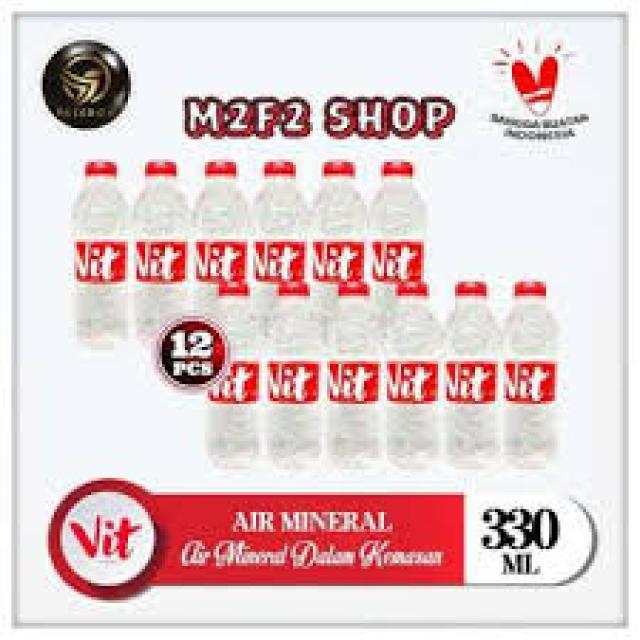

CURRENT_LABELS: train-046


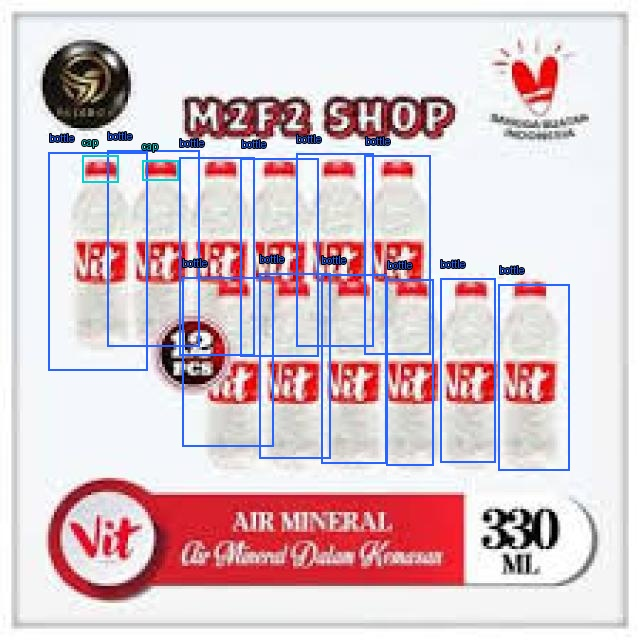

V2_REPAIR_PREVIEW_READY: Ctrl+S để đọc ảnh gốc và sửa nhãn ở bước tiếp theo.


In [2]:
# Cell 8: chuẩn bị ảnh gốc và hồ sơ sửa nhãn v2; CPU Colab, không train.
import sys, json, hashlib, shutil, uuid
from pathlib import Path
from datetime import datetime, timezone

V2_DATASET_SHA = "28ee24280bce8184acd1cdf9a97e850788e908109bfa662efecb07a8a7b179eb"
V2_AUDIT_ID = "20261104T041045Z-62cc8e"
V2_REVIEW_PACK = json.loads('{"revision": "label-audit-2026-11-04-v1", "dataset_sha256": "28ee24280bce8184acd1cdf9a97e850788e908109bfa662efecb07a8a7b179eb", "audit_id": "20261104T041045Z-62cc8e", "scope": "Screening all 72 saved labelled previews; not original-resolution verification or a full candidate audit", "reviewed_ids": ["train-001", "train-002", "train-003", "train-004", "train-005", "train-006", "train-007", "train-008", "train-009", "train-010", "train-011", "train-012", "train-013", "train-014", "train-015", "train-016", "train-017", "train-018", "train-019", "train-020", "train-021", "train-022", "train-023", "train-024", "train-025", "train-026", "train-027", "train-028", "train-029", "train-030", "train-031", "train-032", "train-033", "train-034", "train-035", "train-036", "train-037", "train-038", "train-039", "train-040", "train-041", "train-042", "train-043", "train-044", "train-045", "train-046", "train-047", "train-048", "val-001", "val-002", "val-003", "val-004", "val-005", "val-006", "val-007", "val-008", "val-009", "val-010", "val-011", "val-012", "test-001", "test-002", "test-003", "test-004", "test-005", "test-006", "test-007", "test-008", "test-009", "test-010", "test-011", "test-012"], "conveyor_scenes_observed_in_sample": 0, "sheet_sha256": {"audit-sheet-01.jpg": "884beef3f3b6f277a7c989b1a2cc1f1b8048f9ae1da6ab895731a17950e96980", "audit-sheet-02.jpg": "63d033adab5c1377ef838c382bb49d30e81c8898cf29b6b524e991a16028a487", "audit-sheet-03.jpg": "544cd93fecfedd9f9088ea7e6cc66aab1f6632d67ff9c3607cb12520a5551f57", "audit-sheet-04.jpg": "eab17f8fce5e2f306508bfe6dad9e83162791202d629a8364ebe20ed4cc02ca6", "audit-sheet-05.jpg": "d22ffc712a10eec1805c98bd24da257cdba3dac526c0dcd03d5cc779a05fcbd2", "audit-sheet-06.jpg": "11fc3f5cafd70075be024dca3438658bce955d8aa2be0002356daf2d0160f299", "audit-sheet-07.jpg": "9bc915003c1a8ca7c047f51bd49c683186d402a29e4daa745a2795eecbc16e20", "audit-sheet-08.jpg": "432f6d5b5a56c2ab339b7dc0e35be37ac4cad6e11fc0f7243b98aad052e1d3ea", "audit-sheet-09.jpg": "3402436aac44794aa083576d2018d9f166880fb98624068a3ee037e2c9355748", "audit-sheet-10.jpg": "452e815230b86fc1b3ccc4e276d7547a4e47cadf7476adc714fa74676ae2d29a", "audit-sheet-11.jpg": "24c2080f4125188bd2a3122f5e7746eaf39aacb0f80ec28ba570c8a2fb5ed5f8", "audit-sheet-12.jpg": "954077310b53e3cf937be0f15b4e0393c52acc0bb5532256c3ddc25760d2830a"}, "findings": [{"id": "train-005", "status": "needs_annotation_review", "reason": "label=0 despite clearly visible Nu Green Tea product sleeve/printing; clarify label policy"}, {"id": "train-016", "status": "needs_original_review", "reason": "Three bottles, one cap annotation; left cap appears present; middle mouth unresolved"}, {"id": "train-018", "status": "needs_annotation_review", "reason": "label=0 despite visible Mountain Dew label"}, {"id": "train-020", "status": "needs_policy_review", "reason": "Close-up cap and partial bottle, bottle=0; clarify truncated-bottle annotation policy"}, {"id": "train-027", "status": "needs_original_review", "reason": "cap=0 despite apparently visible white cap on crushed bottle"}, {"id": "train-044", "status": "needs_annotation_and_relevance_review", "reason": "Six labelled/printed product bottles in advertisement, label=0"}, {"id": "train-046", "status": "incomplete_annotations_observed", "reason": "12 bottles, many visible red caps and product labels, only two cap boxes and no label boxes"}], "unlisted_samples": "Preview screened; not certified annotation-clean", "source_edits": false, "drive_review_updated": false, "retraining_started": false, "report": "docs/reports/2026-11-05-original-label-review.md"}')


def v2_sha(path):
    import hashlib
    from pathlib import Path
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def export_v2_repair_sources(archive, audit, review_pack, output, expected_sha):
    """Bind manual preview findings to original images without changing annotations."""
    import hashlib, io, json, math, re, zipfile
    from pathlib import Path, PurePosixPath
    from PIL import Image, ImageDraw, ImageFont

    archive, output = Path(archive), Path(output)
    if v2_sha(archive) != expected_sha or audit.get("dataset_sha256") != expected_sha:
        raise RuntimeError("ZIP/audit không khớp dataset đã train.")
    if review_pack.get("dataset_sha256") != expected_sha:
        raise RuntimeError("Review khác dataset.")
    findings = review_pack["findings"]
    ids = [item["id"] for item in findings]
    if len(ids) != len(set(ids)) or not ids or any(not re.fullmatch(r"(train|val|test)-[0-9]{3}", i) for i in ids):
        raise ValueError("ID review không hợp lệ/trùng.")
    samples = {item["id"]: item for item in audit["samples"]}
    if len(samples) != len(audit["samples"]):
        raise RuntimeError("Audit có ID trùng.")
    colors = {0: (40, 100, 255), 1: (0, 210, 210), 2: (255, 180, 0)}
    classes = {0: "bottle", 1: "cap", 2: "label"}
    entries = []
    with zipfile.ZipFile(archive) as z:
        names = [n for n in z.namelist() if not n.endswith("/")]
        if len(names) != len(set(names)):
            raise RuntimeError("ZIP có tên file trùng.")
        records = json.loads(z.read("retained-checksums.json"))
        records_by_image = {r["image"]: r for r in records}
        if len(records_by_image) != len(records):
            raise RuntimeError("Candidate có image record trùng.")
        expected_ids = {}
        for split in ("train", "val", "test"):
            ordered = sorted((r for r in records if r["split"] == split),
                             key=lambda r: hashlib.sha256(("label-audit-v1:" + r["image"]).encode()).hexdigest())
            for i, record in enumerate(ordered, 1):
                expected_ids["%s-%03d" % (split, i)] = record
        payloads = []
        for finding in findings:
            ident = finding["id"]
            sample, record = samples[ident], expected_ids[ident]
            if any(sample[k] != record[k] for k in ("image", "label", "image_sha256", "label_sha256")):
                raise RuntimeError("ID không còn ánh xạ đúng ảnh review: " + ident)
            for key, prefix in (("image", "images"), ("label", "labels")):
                name = record[key]
                path = PurePosixPath(name)
                if (path.is_absolute() or ".." in path.parts or chr(92) in name or ":" in name
                        or path.parts[:2] != (prefix, record["split"])):
                    raise RuntimeError("Đường dẫn nguồn không hợp lệ.")
            image_bytes, label_bytes = z.read(record["image"]), z.read(record["label"])
            if (hashlib.sha256(image_bytes).hexdigest() != record["image_sha256"]
                    or hashlib.sha256(label_bytes).hexdigest() != record["label_sha256"]):
                raise RuntimeError("Ảnh/nhãn gốc sai SHA: " + ident)
            with Image.open(io.BytesIO(image_bytes)) as decoded:
                image = decoded.convert("RGB")
            width, height = image.size
            boxes = []
            text = label_bytes.decode("utf-8-sig")
            for line in text.splitlines():
                if not line.strip():
                    continue
                values = line.split()
                if len(values) != 5:
                    raise RuntimeError("Nhãn nguồn không phải YOLO detection.")
                cls = int(values[0])
                cx, cy, w, h = map(float, values[1:])
                if (cls not in classes or not all(math.isfinite(v) for v in (cx, cy, w, h))
                        or min(w, h) <= 0 or min(cx - w / 2, cy - h / 2) < -1e-6
                        or max(cx + w / 2, cy + h / 2) > 1 + 1e-6):
                    raise RuntimeError("Box nguồn không hợp lệ.")
                boxes.append((cls, cx, cy, w, h))
            payloads.append((finding, record, image_bytes, label_bytes, image, boxes))
        output.mkdir(parents=True, exist_ok=False)
        try:
            font = ImageFont.truetype("DejaVuSans.ttf", 18)
        except OSError:
            font = ImageFont.load_default()
        for finding, record, image_bytes, label_bytes, image, boxes in payloads:
            ident = finding["id"]
            # Bản gốc giữ nguyên byte, không ghi annotation mới từ dự đoán hoặc preview.
            source_name = ident + "-source" + PurePosixPath(record["image"]).suffix.lower()
            label_name, overlay_name = ident + "-original.txt", ident + "-current-labels.jpg"
            (output / source_name).write_bytes(image_bytes)
            (output / label_name).write_bytes(label_bytes)
            width, height = image.size
            overlay = image.copy()
            overlay.thumbnail((1600, 1600))
            dw, dh = overlay.size
            draw = ImageDraw.Draw(overlay)
            for cls, cx, cy, w, h in boxes:
                x1, y1 = min(dw - 1, max(0, (cx - w / 2) * dw)), min(dh - 1, max(0, (cy - h / 2) * dh))
                x2, y2 = min(dw - 1, max(0, (cx + w / 2) * dw)), min(dh - 1, max(0, (cy + h / 2) * dh))
                draw.rectangle((x1, y1, x2, y2), outline=colors[cls], width=2)
                draw.text((x1, max(0, y1 - 20)), classes[cls], font=font,
                          fill=colors[cls], stroke_width=1, stroke_fill="black")
            overlay.save(output / overlay_name, quality=95)
            entries.append(dict(id=ident, split=record["split"], image=record["image"], label=record["label"],
                                image_sha256=record["image_sha256"], label_sha256=record["label_sha256"],
                                width=width, height=height, original_yolo=label_bytes.decode("utf-8-sig"),
                                source_file=source_name, current_overlay=overlay_name,
                                original_label_file=label_name, finding=finding["reason"],
                                decision="pending", replacement_yolo=None))
    plan = dict(dataset_sha256=expected_sha, audit_id=review_pack["audit_id"], classes=classes,
                status="REVIEW_PACK_ONLY", training_ready=False,
                source_modified=False, candidate_v2_created=False, entries=entries,
                remaining_work=["Review original images and decide edits/exclusions; keep ambiguous cases unresolved",
                                "Review other affected images; these IDs are not an exclusion quota",
                                "Add representative conveyor data and independent capture-session splits",
                                "Build and verify a separate candidate before starting a new GPU run"])
    (output / "v2-repair-review.json").write_text(json.dumps(plan, ensure_ascii=False, indent=2), encoding="utf-8")
    return plan


def run_v2_repair_export():
    if sys.platform != "linux" or not Path("/content").is_dir():
        raise RuntimeError("Chọn Colab remote kernel; không tải dataset về Windows.")
    from google.colab import drive
    from IPython.display import Image as DisplayImage, display
    root = Path("/content/drive/MyDrive")
    if not root.is_dir():
        drive.mount("/content/drive")
    run = root / "BottleQC/training-runs/bottleqc-yolo11n-640-v1"
    complete = json.loads((run / "TRAIN_COMPLETE.json").read_text())
    if complete["binding"].get("dataset_sha256") != V2_DATASET_SHA:
        raise RuntimeError("Dataset không khớp run đã train.")
    audit_dir = run / "dataset-audits" / V2_AUDIT_ID
    audit = json.loads((audit_dir / "label-audit.json").read_text(encoding="utf-8"))
    for name, digest in V2_REVIEW_PACK["sheet_sha256"].items():
        if v2_sha(audit_dir / name) != digest:
            raise RuntimeError("Bảng ảnh khác lần đã review: " + name)
    candidate = root / "BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5/prepared-candidate.zip"
    work = Path("/content/bottleqc-label-audit")
    work.mkdir(exist_ok=True)
    local_zip = work / (V2_DATASET_SHA[:16] + ".zip")
    print("V2_REPAIR_ENV: Colab CPU tasks, no model/train/CUDA", flush=True)
    print("V2_REPAIR_SOURCE:", candidate, "bytes=", candidate.stat().st_size, flush=True)
    if not local_zip.is_file() or v2_sha(local_zip) != V2_DATASET_SHA:
        part = local_zip.with_suffix(".zip.part")
        try:
            shutil.copyfile(candidate, part)
            if v2_sha(part) != V2_DATASET_SHA:
                raise RuntimeError("ZIP copy sai SHA.")
            part.replace(local_zip)
        finally:
            part.unlink(missing_ok=True)
    ident = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
    local = work / ("v2-repair-" + ident)
    plan = export_v2_repair_sources(local_zip, audit, V2_REVIEW_PACK, local, V2_DATASET_SHA)
    durable = run / "dataset-v2-preparation" / ident
    durable.mkdir(parents=True, exist_ok=False)
    files = {}
    for source in sorted(local.iterdir()):
        destination = durable / source.name
        shutil.copyfile(source, destination)
        if v2_sha(source) != v2_sha(destination):
            raise RuntimeError("Artifact copy sai SHA.")
        files[source.name] = v2_sha(destination)
    (durable / "COMPLETE.json").write_text(json.dumps(dict(status="REVIEW_PACK_ONLY", training_ready=False,
                                                           dataset_sha256=V2_DATASET_SHA, files=files), indent=2), encoding="utf-8")
    print("V2_REPAIR_SAVED:", durable)
    print("V2_REPAIR_STATUS: REVIEW_PACK_ONLY; training_ready=False; no annotations changed")
    print("V2_REPAIR_VIEW: ảnh và nhãn nguồn của dataset, không phải dự đoán model; checksum đúng không chứng minh nhãn đúng.")
    for entry in plan["entries"]:
        print("V2_REPAIR_ENTRY:", json.dumps(entry, ensure_ascii=False))
        print("SOURCE:", entry["id"])
        display(DisplayImage(filename=str(local / entry["source_file"])))
        print("CURRENT_LABELS:", entry["id"], "(nhãn dataset chưa sửa, không phải dự đoán)")
        display(DisplayImage(filename=str(local / entry["current_overlay"])))
    print("V2_REPAIR_PREVIEW_READY: Ctrl+S để đọc ảnh gốc và sửa nhãn ở bước tiếp theo.")


run_v2_repair_export()


## 9 — Đo độ trễ prediction trên GPU Colab (không train)

Dùng khi cần kiểm tra tốc độ: kết nối **GPU Colab** rồi chỉ chạy cell 9. Không chạy cell 1–5 hoặc train lại.
Cell tự kiểm tra GPU, model SHA, video SHA, cài đúng Ultralytics nếu thiếu. Không fallback CPU/local.

Đo batch=1 trên 60 frame thật của clip MV Center, sau 5 lần warmup; đồng bộ CUDA trước/sau mỗi phép đo.
Báo mean/p50/p95 mili-giây và throughput prediction; nguồn 60 fps tương ứng khoảng 16,67 ms/frame nếu xử lý đủ frame.
Đây là đo preprocessing + prediction + postprocessing, **không** gồm camera/decode, tracking, logic QC, vẽ/lưu video hoặc Drive.
GPU Colab không đại diện máy desktop triển khai. Báo cáo không tự kết luận realtime hoặc độ chính xác đã đạt.

Cell 6 hiện dùng stride=4 nên chủ động nhận diện 1/4 frame; file video được đọc tuần tự, không bỏ thêm vì CPU chậm.
Dây chuyền thật cần đủ throughput và deadline theo tốc độ chai, vùng quan sát/camera; nhòe chuyển động cần xử lý ở ảnh/dữ liệu/chụp,
không phải phát chậm video để coi model đã cải thiện. SPEED_BENCH_SAVED lưu JSON và CSV trên Drive; Ctrl+S để đọc output.


In [ ]:
# Cell 9 độc lập: đo prediction batch=1 trên GPU Colab, không train.
import sys, json, hashlib, shutil, uuid, csv, subprocess, importlib.metadata
from pathlib import Path
from datetime import datetime, timezone

SPEED_DEVICE = 0
SPEED_SAMPLES = 60
SPEED_WARMUP = 5
SPEED_WEIGHTS_SHA = "4839c128b8b13b5785b55db2d0a15d061e424b3abfbca3653f48a1b9a5533030"
SPEED_VIDEO_SHA = "017fa285bc3325fbd82a7b2d30a335e731154af0601fb2a0175857192321d172"


def speed_sha(path):
    import hashlib
    from pathlib import Path
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def require_speed_gpu():
    import sys
    from pathlib import Path
    if sys.platform != "linux" or not Path("/content").is_dir():
        raise RuntimeError("Chọn Colab GPU; không benchmark trên workstation.")
    import google.colab
    import torch
    if SPEED_DEVICE != 0 or type(SPEED_DEVICE) is not int or not torch.cuda.is_available():
        raise RuntimeError("Cell 9 cần GPU Colab và SPEED_DEVICE=0; không tự chuyển sang CPU.")
    return torch


def benchmark_prediction_video(model, video, device, synchronize, *, samples=60, warmup=5):
    """Measure synchronized batch-1 prediction; decoding, plotting, IO and model load excluded."""
    import cv2, math, statistics, time
    if type(samples) is not int or samples < 2 or type(warmup) is not int or warmup < 1:
        raise ValueError("Cần ít nhất 2 mẫu và 1 warmup.")
    cap = cv2.VideoCapture(str(video))
    inputs = []
    try:
        if not cap.isOpened():
            raise RuntimeError("Không mở được video benchmark.")
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not math.isfinite(fps) or fps <= 0 or count <= 0:
            raise RuntimeError("Thông số video không hợp lệ.")
        # Chỉ các cảnh quay trực tiếp chai đã xem; bỏ HMI, lia máy và outro.
        eligible = [i for i in range(count) if 11 <= i / fps < 22 or 28 <= i / fps < 31.5]
        if len(eligible) < samples:
            raise RuntimeError("Không đủ frame trong các đoạn benchmark đã chọn.")
        chosen = {eligible[i * (len(eligible) - 1) // (samples - 1)] for i in range(samples)}
        index = 0
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            if index in chosen:
                inputs.append((index, frame))
            index += 1
        if index != count or len(inputs) != samples:
            raise RuntimeError("Đọc thiếu video/frame benchmark.")
    finally:
        cap.release()
    for i in range(warmup):
        model.predict(inputs[i % samples][1], device=device, imgsz=640, conf=0.25, verbose=False)
    synchronize()
    rows = []
    for index, frame in inputs:
        synchronize()
        begin = time.perf_counter()
        model.predict(frame, device=device, imgsz=640, conf=0.25, verbose=False)
        synchronize()
        elapsed_ms = (time.perf_counter() - begin) * 1000
        if not math.isfinite(elapsed_ms) or elapsed_ms <= 0:
            raise RuntimeError("Đồng hồ không tạo được latency hợp lệ.")
        rows.append(dict(frame=index, source_seconds=index / fps, predict_ms=elapsed_ms))
    values = sorted(row["predict_ms"] for row in rows)
    rank = (len(values) - 1) * 0.95
    low, high = math.floor(rank), math.ceil(rank)
    p95 = values[low] + (values[high] - values[low]) * (rank - low)
    report = dict(samples=samples, warmup=warmup, source_fps=fps,
                  source_frame_budget_ms=1000 / fps, batch=1, imgsz=640, conf=0.25,
                  predict_mean_ms=statistics.mean(values), predict_p50_ms=statistics.median(values), predict_p95_ms=p95,
                  predict_only_throughput_fps=1000 * samples / sum(values),
                  source_intervals_seconds=[[11, 22], [28, 31.5]],
                  includes=["preprocessing", "model prediction", "postprocessing", "CUDA synchronization"],
                  excludes=["model load", "warmup", "frame capture/decode", "tracking", "QC decisions", "render", "encode", "Drive IO"],
                  production_realtime_proven=False, accuracy_measured=False,
                  scope="Prediction-only timing on Colab GPU; not camera/line latency or workstation performance")
    return report, rows


def run_prediction_speed_benchmark():
    torch = require_speed_gpu()
    print("SPEED_ENV:", torch.cuda.get_device_name(0), "torch=", torch.__version__, flush=True)
    from google.colab import drive
    root = Path("/content/drive/MyDrive")
    if not root.is_dir():
        drive.mount("/content/drive")
    run = root / "BottleQC/training-runs/bottleqc-yolo11n-640-v1"
    complete = json.loads((run / "TRAIN_COMPLETE.json").read_text())
    best = run / "weights/best.pt"
    video = run / "video-tests/factory-line-20261104T034556Z-b5c9c1/factory-input.mp4"
    if (complete.get("best_sha256") != SPEED_WEIGHTS_SHA or speed_sha(best) != SPEED_WEIGHTS_SHA
            or speed_sha(video) != SPEED_VIDEO_SHA):
        raise RuntimeError("Model/video khác bản đã chọn.")
    try:
        version = importlib.metadata.version("ultralytics")
    except importlib.metadata.PackageNotFoundError:
        version = None
    if version != "8.4.193":
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "ultralytics==8.4.193"], check=True)
    import ultralytics
    from ultralytics import YOLO
    if ultralytics.__version__ != "8.4.193":
        raise RuntimeError("Restart kernel rồi chạy riêng cell 9 để import đúng dependency.")
    work = Path("/content/bottleqc-speed-benchmark")
    work.mkdir(exist_ok=True)
    for source, name, digest in ((best, "best.pt", SPEED_WEIGHTS_SHA), (video, "input.mp4", SPEED_VIDEO_SHA)):
        destination = work / name
        if not destination.is_file() or speed_sha(destination) != digest:
            part = destination.with_suffix(destination.suffix + ".part")
            try:
                shutil.copyfile(source, part)
                if speed_sha(part) != digest:
                    raise RuntimeError("Bản copy local sai checksum.")
                part.replace(destination)
            finally:
                part.unlink(missing_ok=True)
    model = YOLO(str(work / "best.pt"), task="detect")
    if model.task != "detect" or model.names != {0: "bottle", 1: "cap", 2: "label"}:
        raise RuntimeError("Sai task/class mapping.")
    print("SPEED_BENCH_RUNNING:", SPEED_SAMPLES, "frames; warmup=", SPEED_WARMUP, flush=True)
    report, rows = benchmark_prediction_video(model, work / "input.mp4", SPEED_DEVICE,
                                              lambda: torch.cuda.synchronize(0),
                                              samples=SPEED_SAMPLES, warmup=SPEED_WARMUP)
    report.update(weights_sha256=SPEED_WEIGHTS_SHA, source_sha256=SPEED_VIDEO_SHA,
                  gpu=torch.cuda.get_device_name(0), torch=torch.__version__, ultralytics=ultralytics.__version__,
                  precision="PyTorch default FP32; no half=True")
    ident = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
    local = work / ident
    local.mkdir()
    with (local / "prediction-latencies.csv").open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["frame", "source_seconds", "predict_ms"])
        writer.writeheader()
        writer.writerows(rows)
    (local / "prediction-speed.json").write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    durable = run / "speed-benchmarks" / ident
    durable.mkdir(parents=True, exist_ok=False)
    files = {}
    for source in local.iterdir():
        destination = durable / source.name
        shutil.copyfile(source, destination)
        if speed_sha(source) != speed_sha(destination):
            raise RuntimeError("Copy báo cáo speed sai checksum.")
        files[source.name] = speed_sha(destination)
    (durable / "COMPLETE.json").write_text(json.dumps(dict(files=files), indent=2), encoding="utf-8")
    print("SPEED_BENCH_SAVED:", durable)
    print(json.dumps(report, ensure_ascii=False, indent=2))
    print("SPEED_SCOPE: chỉ prediction trên GPU Colab; chưa chứng minh chạy realtime cả dây chuyền.")


run_prediction_speed_benchmark()


## Cell 10–19 — Luồng Colab v2 chưa chạy

Tất cả code cell mới đều chưa thực thi và không có output mới. Cell index 16, id 35b0f7bc, hiển thị Cell 8, chỉ xuất annotation hiện có và vẽ box; không chạy detection. Cell index 18, id 1049d3dd, hiển thị Cell 9, là đề xuất timing cũ chưa chạy.

Thứ tự: 10 parser/helper; 11 audit toàn candidate; 12 semantic review theo batch; 13 intake nguồn có quyền; 14 receipt review sửa; 15 tạo grouped candidate v2; 16 train/resume YOLO11n mới; 17 đánh giá paired trên validation/holdout; 18 timing component batch=1; 19 regression NOT_RUN.

Trước mỗi lần chạy: kiểm SHA đầu vào, đúng tài khoản Drive, Colab runtime, GPU/CUDA, dung lượng đĩa và quyền ghi/readback tương ứng. Chuyển lên Drive chỉ manifest phiên quay, quyền sử dụng, receipt review, model best.pt được chọn và artifact nhỏ cần thiết. Dataset, video/frame và checkpoint lớn ở Colab/Drive.

Số 3849/307/201, ZIP SHA 28ee24280bce8184acd1cdf9a97e850788e908109bfa662efecb07a8a7b179eb, v1 best.pt SHA 4839c128b8b13b5785b55db2d0a15d061e424b3abfbca3653f48a1b9a5533030, 92 epoch và best epoch 72 chỉ là saved output cũ, chưa phải lần đọc Drive độc lập.

Mỗi stage ghi artifact vào đường dẫn version riêng, kiểm hash/readback và ghi COMPLETE cuối. Cùng input hoàn chỉnh thì dùng lại artifact đã xác minh; thư mục dang dở hoặc hash khác phải dừng để kiểm tra. Không ghi đè source, candidate v1, v1 weights hoặc run đã complete.

Recovery: giữ thư mục dang dở, file .part, pointer và marker cũ. Kiểm hash/binding trước khi tiếp tục; nếu không khớp, cách ly lần chạy và dùng version mới. Không xóa hoặc thay nguồn/v1.

## 10 — Hợp đồng parser và phép vẽ YOLO

Chạy helper trước các stage còn lại. Lớp cố định: 0=bottle, 1=cap, 2=label. Parser xác minh class, số hữu hạn, kích thước và box trong ảnh; trả xyxy nửa mở, kẹp theo pixel nhìn thấy. Không biến cap/neck thành bottle khi pixel chưa chứng minh identity.

Kiểm tra tính tay: 0 0.5 0.5 0.4 0.6 trên ảnh 100×80 thành [30,16,70,64]; pixel vẽ gồm (30,40) và (69,63), tâm (50,40) không bị tô. Đây là hợp đồng/helper, không phải kết quả inference hay kiểm thử đã chạy. Cell chỉ định nghĩa helper; không tạo artifact bền vững. Nếu runtime mất, nạp lại notebook và chạy các stage theo thứ tự.

In [1]:
import hashlib
import io
import json
import math
import shutil
import stat
import zipfile
from pathlib import Path, PurePosixPath

V2_CLASSES = {0: "bottle", 1: "cap", 2: "label"}
V2_POLICY_REVISION = "BottleQC-visible-object-and-physical-label-v2"

def v2_sha256(value):
    digest=hashlib.sha256()
    with Path(value).open("rb") as stream:
        for block in iter(lambda:stream.read(1024*1024),b""):
            digest.update(block)
    return digest.hexdigest()

def v2_bytes_sha256(value):
    return hashlib.sha256(value).hexdigest()

def v2_safe_member(name):
    if not isinstance(name,str) or not name or chr(92) in name or ":" in name:
        raise ValueError("Unsafe POSIX relative path.")
    path=PurePosixPath(name)
    if path.is_absolute() or any(part in ("",".","..") for part in path.parts):
        raise ValueError("ZIP path escapes its root.")
    return path

def v2_resolve_below(root,relative):
    root=Path(root).resolve()
    target=(root/Path(*v2_safe_member(relative).parts)).resolve()
    if target==root or not target.is_relative_to(root):
        raise ValueError("Path escapes approved root.")
    return target

def v2_parse_yolo(text,width,height,classes=None):
    """Convert normalized YOLO xywh to clipped half-open pixel xyxy."""
    classes=V2_CLASSES if classes is None else classes
    if type(width) is not int or type(height) is not int or min(width,height)<=0:
        raise ValueError("Image dimensions must be positive integers.")
    rows=[]
    for number,line in enumerate(text.splitlines(),1):
        if not line.strip(): continue
        fields=line.split()
        if len(fields)!=5: raise ValueError("line %d: expected five YOLO fields"%number)
        try:
            class_number=float(fields[0]); cx,cy,bw,bh=map(float,fields[1:])
        except ValueError as exc: raise ValueError("line %d: nonnumeric field"%number) from exc
        if not math.isfinite(class_number) or not class_number.is_integer():
            raise ValueError("line %d: class must be integer"%number)
        class_id=int(class_number)
        if class_id not in classes: raise ValueError("line %d: unknown class"%number)
        if not all(math.isfinite(v) for v in (cx,cy,bw,bh)) or min(bw,bh)<=0:
            raise ValueError("line %d: invalid box"%number)
        left,top,right,bottom=cx-bw/2,cy-bh/2,cx+bw/2,cy+bh/2
        if min(left,top)<-1e-9 or max(right,bottom)>1+1e-9:
            raise ValueError("line %d: box outside image"%number)
        x1=max(0.0,left*width); y1=max(0.0,top*height)
        x2=min(float(width),right*width); y2=min(float(height),bottom*height)
        if x2<=x1 or y2<=y1: raise ValueError("line %d: no visible area"%number)
        rows.append({"class_id":class_id,"class_name":classes[class_id],
                     "xyxy":[x1,y1,x2,y2],"line":number})
    return rows

def v2_draw_yolo(image,text,classes=None):
    from PIL import ImageDraw,ImageFont
    classes=V2_CLASSES if classes is None else classes
    image=image.convert("RGB").copy()
    boxes=v2_parse_yolo(text,image.width,image.height,classes)
    draw=ImageDraw.Draw(image); font=ImageFont.load_default()
    colors={0:(35,105,255),1:(0,210,205),2:(255,170,0)}
    for box in boxes:
        x1,y1,x2,y2=box["xyxy"]
        left=max(0,min(image.width-1,math.floor(x1)))
        top=max(0,min(image.height-1,math.floor(y1)))
        right=max(left,min(image.width-1,math.ceil(x2)-1))
        bottom=max(top,min(image.height-1,math.ceil(y2)-1))
        color=colors[box["class_id"]]
        draw.rectangle((left,top,right,bottom),outline=color,width=2)
        draw.text((left,max(0,top-12)),box["class_name"],fill=color,font=font)
    return image,boxes

def v2_image_metadata(image_bytes):
    from PIL import Image
    with Image.open(io.BytesIO(image_bytes)) as image: image.verify()
    with Image.open(io.BytesIO(image_bytes)) as image:
        return {"width":int(image.width),"height":int(image.height),"mode":image.mode,
                "exif_orientation":image.getexif().get(274)}

def v2_phash(image_bytes):
    import numpy as np
    from PIL import Image
    with Image.open(io.BytesIO(image_bytes)) as image:
        pixels=np.asarray(image.convert("L").resize((32,32)),dtype=np.float64)
    n=32; x=np.arange(n)
    basis=np.cos(np.pi*(2*x+1)*np.arange(n)[:,None]/(2*n))
    basis[0]*=1/math.sqrt(2); basis*=math.sqrt(2/n)
    low=(basis@pixels@basis.T)[:8,:8]; median=float(np.median(low.reshape(-1)[1:]))
    result=0
    for bit in (low>median).reshape(-1): result=(result<<1)|int(bit)
    return "%016x"%result

def v2_duplicate_components(rows,max_hamming=5):
    if type(max_hamming) is not int or not 0<=max_hamming<=64:
        raise ValueError("max_hamming outside [0,64].")
    parent=list(range(len(rows)))
    def find(i):
        while parent[i]!=i:
            parent[i]=parent[parent[i]]; i=parent[i]
        return i
    def union(a,b):
        a,b=find(a),find(b)
        if a!=b: parent[b]=a
    hashes=[]
    for row in rows:
        value=row.get("phash")
        if not isinstance(value,str) or len(value)!=16: raise ValueError("Invalid pHash.")
        hashes.append(int(value,16))
    for a in range(len(rows)):
        for b in range(a+1,len(rows)):
            if rows[a].get("image_sha256")==rows[b].get("image_sha256") or (hashes[a]^hashes[b]).bit_count()<=max_hamming:
                union(a,b)
    groups={}
    for i in range(len(rows)): groups.setdefault(find(i),[]).append(i)
    result={}; serial=0
    for members in groups.values():
        if len(members)<2: continue
        serial+=1; name="dup-%06d"%serial
        for i in members: result[i]=name
    return result

def v2_review_coverage(all_ids,decisions):
    statuses={}
    for row in decisions:
        ident,status=row.get("id"),row.get("status")
        if ident not in all_ids or ident in statuses or status not in {"reviewed","unresolved"}:
            raise ValueError("Invalid or duplicate semantic decision.")
        statuses[ident]=status
    reviewed=sorted(i for i,s in statuses.items() if s=="reviewed")
    unresolved=sorted(i for i,s in statuses.items() if s=="unresolved")
    unreviewed=sorted(set(all_ids)-set(statuses))
    return {"reviewed_ids":reviewed,"unresolved_ids":unresolved,"unreviewed_ids":unreviewed,
            "reviewed_count":len(reviewed),"unresolved_count":len(unresolved),
            "unreviewed_count":len(unreviewed),"semantic_clean_claim":False}

def v2_atomic_json(path,value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+".part")
    if tmp.exists(): raise FileExistsError("Stale part file requires inspection.")
    tmp.write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
    tmp.replace(path)

def v2_copy_verified(source,destination,expected_sha=None):
    source,destination=Path(source),Path(destination)
    if not source.is_file(): raise FileNotFoundError(str(source))
    digest=v2_sha256(source)
    if expected_sha is not None and digest!=expected_sha: raise RuntimeError("Input hash mismatch.")
    if destination.exists():
        if destination.is_file() and v2_sha256(destination)==digest: return digest
        raise FileExistsError("Refusing to overwrite different artifact.")
    destination.parent.mkdir(parents=True,exist_ok=True)
    tmp=destination.with_name(destination.name+".part")
    if tmp.exists(): raise FileExistsError("Stale part file requires inspection.")
    shutil.copyfile(source,tmp)
    if v2_sha256(tmp)!=digest: tmp.unlink(); raise RuntimeError("Copy hash mismatch.")
    tmp.replace(destination)
    if v2_sha256(destination)!=digest: raise RuntimeError("Readback hash mismatch.")
    return digest

def v2_verify_file_manifest(root,files):
    root=Path(root).resolve()
    for relative,digest in files.items():
        path=v2_resolve_below(root,relative)
        if not path.is_file() or v2_sha256(path)!=digest: raise RuntimeError("Artifact hash mismatch.")
    return True


## 11 — Audit candidate lọc: đã hoàn tất

Stage 11 đã chạy với ZIP mới và SHA `03198fb7279e89fee87c5d91df9b5d0d908fa943766a6981e6f8688871b35e3e`. Drive có audit `audit-v2-03198fb7279e89fe`, 4.278 cặp, 0 lỗi cấu trúc, review pack 72 ảnh. Đây chưa phải xác nhận nhãn đúng.

Kết quả thấy 741 nhóm pHash gần nhau; 66 nhóm chéo split là ứng viên để đối chiếu hình, chưa khẳng định duplicate. Tiếp tục **cell Stage 12** để tạo review batch trên đúng SHA này. Output Stage 12 cũ là từ ZIP trước lọc, bỏ qua. Chưa train.


In [2]:
import hashlib
import io
import json
import stat
import zipfile
from pathlib import Path
from PIL import Image

V2_BASE_ZIP = "BottleQC/datasets/blur-filtered/blur-filtered-b17e060caa43d8c3/prepared-candidate.zip"
V2_BASE_ZIP_SHA256 = "03198fb7279e89fee87c5d91df9b5d0d908fa943766a6981e6f8688871b35e3e"
V2_EXPECTED_BASE_COUNTS = {"train":3778,"val":299,"test":201}
V2_REVIEW_PACK_LIMIT = 72

def v2_audit_archive(archive_path,output_dir,expected_sha,expected_counts,review_limit=72):
    archive_path,output_dir=Path(archive_path),Path(output_dir)
    if v2_sha256(archive_path)!=expected_sha: raise RuntimeError("Candidate ZIP SHA precondition failed.")
    if type(review_limit) is not int or not 1<=review_limit<=200: raise ValueError("Review pack bound must be 1..200.")
    target=output_dir/("audit-v2-"+expected_sha[:16])
    if target.exists():
        marker=target/"COMPLETE.json"
        if not marker.is_file(): raise FileExistsError("Incomplete audit directory; inspect before recovery.")
        complete=json.loads(marker.read_text(encoding="utf-8"))
        if complete.get("source_zip_sha256")!=expected_sha or complete.get("review_limit")!=review_limit:
            raise FileExistsError("Audit path is bound to different source/config.")
        v2_verify_file_manifest(target,complete.get("files",{}))
        return target,json.loads((target/"audit-summary.json").read_text(encoding="utf-8"))
    rows=[]; classes={name:0 for name in V2_CLASSES.values()}
    split_counts=dict.fromkeys(expected_counts,0)
    area_bins={"<0.1%":0,"0.1%-1%":0,"1%-25%":0,">=25%":0}
    size_bins={"<=320px":0,"321-640px":0,">640px":0}
    empty=structural_issues=0
    with zipfile.ZipFile(archive_path,"r") as z:
        infos=[item for item in z.infolist() if not item.is_dir()]
        names=[item.filename for item in infos]
        if len(names)!=len(set(names)): raise RuntimeError("ZIP contains duplicate member names.")
        members={}
        for item in infos:
            v2_safe_member(item.filename)
            if stat.S_ISLNK(item.external_attr>>16): raise RuntimeError("ZIP symlink refused.")
            members[item.filename]=item
        records=json.loads(z.read("retained-checksums.json"))
        if not isinstance(records,list): raise RuntimeError("Pair manifest must be a list.")
        seen_i=set(); seen_l=set(); listed={name for name in names if name.startswith(("images/","labels/"))}
        for r in records:
            split,image,label=r.get("split"),r.get("image"),r.get("label")
            if split not in split_counts or image in seen_i or label in seen_l: raise RuntimeError("Invalid or repeated pair.")
            ip,lp=v2_safe_member(image),v2_safe_member(label)
            if ip.parts[:2]!=("images",split) or lp.parts[:2]!=("labels",split): raise RuntimeError("Pair path/split mismatch.")
            if image not in members or label not in members: raise RuntimeError("Unpaired image/label.")
            if members[image].file_size>100*1024*1024 or members[label].file_size>1024*1024:
                raise RuntimeError("ZIP member exceeds audit size bound.")
            ib,lb=z.read(image),z.read(label)
            ih,lh=v2_bytes_sha256(ib),v2_bytes_sha256(lb)
            if ih!=r.get("image_sha256") or lh!=r.get("label_sha256"): raise RuntimeError("Per-file SHA mismatch.")
            meta=v2_image_metadata(ib); text=lb.decode("utf-8-sig"); issues=[]
            try: boxes=v2_parse_yolo(text,meta["width"],meta["height"])
            except (ValueError,UnicodeDecodeError) as exc: boxes=[];issues.append("invalid_yolo:"+str(exc))
            if meta["exif_orientation"] not in (None,1): issues.append("non_upright_exif_orientation")
            if not text.strip(): empty+=1;issues.append("empty_label_semantics_unverified")
            per_class=dict.fromkeys(V2_CLASSES.values(),0); local_area=dict.fromkeys(area_bins,0)
            for box in boxes:
                per_class[box["class_name"]]+=1;classes[box["class_name"]]+=1
                x1,y1,x2,y2=box["xyxy"];area=(x2-x1)*(y2-y1)/(meta["width"]*meta["height"])
                bucket="<0.1%" if area<.001 else "0.1%-1%" if area<.01 else "1%-25%" if area<.25 else ">=25%"
                area_bins[bucket]+=1;local_area[bucket]+=1
            max_dim=max(meta["width"],meta["height"])
            size_key="<=320px" if max_dim<=320 else "321-640px" if max_dim<=640 else ">640px"
            size_bins[size_key]+=1
            suspect=list(issues)
            if per_class["bottle"] and not per_class["cap"]: suspect.append("bottle_without_cap_annotation_review")
            if per_class["bottle"] and not per_class["label"]: suspect.append("bottle_without_label_annotation_review")
            if not boxes: suspect.append("no_boxes_semantic_review_required")
            if min(meta["width"],meta["height"])<160: suspect.append("small_image")
            row={"id":"%s-%06d"%(split,split_counts[split]+1),"split":split,"image":image,"label":label,
                 "image_sha256":ih,"label_sha256":lh,"width":meta["width"],"height":meta["height"],
                 "exif_orientation":meta["exif_orientation"],"image_mode":meta["mode"],"label_bytes":len(lb),
                 "box_count":len(boxes),"class_counts":per_class,"box_area_bins":local_area,
                 "structurally_valid":not issues,"structural_issues":issues,
                 "suspicious_semantic_groups":sorted(set(suspect)),"source_group_id":r.get("source_group_id"),
                 "capture_group_status":"unknown" if not r.get("source_group_id") else "manifest_required","phash":v2_phash(ib)}
            rows.append(row);seen_i.add(image);seen_l.add(label);split_counts[split]+=1;structural_issues+=len(issues)
        pairs={r[key] for r in records for key in ("image","label")}
        if listed!=pairs: raise RuntimeError("Unpaired or unlisted image/label member.")
    if split_counts!=expected_counts: raise RuntimeError("Split count differs from pinned precondition.")
    components=v2_duplicate_components(rows,5); duplicate_groups={}
    for index,name in components.items():
        rows[index]["duplicate_component"]=name;duplicate_groups.setdefault(name,[]).append(rows[index]["id"])
    for row in rows: row.setdefault("duplicate_component",None)
    priorities=[]
    for row in rows:
        if row["suspicious_semantic_groups"] or row["duplicate_component"]:
            key=hashlib.sha256((row["id"]+row["image_sha256"]).encode()).hexdigest()
            priorities.append((0 if row["structural_issues"] else 1,key,row))
    chosen=[x[2] for x in sorted(priorities)[:review_limit]]
    if len(chosen)<review_limit:
        used={r["id"] for r in chosen}
        rest=sorted((r for r in rows if r["id"] not in used),
                    key=lambda r:hashlib.sha256((r["id"]+r["image_sha256"]).encode()).hexdigest())
        chosen.extend(rest[:review_limit-len(chosen)])
    target.mkdir(parents=True,exist_ok=False);pack=target/"review-pack";pack.mkdir()
    with zipfile.ZipFile(archive_path,"r") as z:
        for row in chosen:
            ib=z.read(row["image"]);label_text=z.read(row["label"]).decode("utf-8-sig")
            with Image.open(io.BytesIO(ib)) as im:
                try:
                    overlay,_=v2_draw_yolo(im,label_text)
                except (ValueError,UnicodeDecodeError):
                    overlay=im.convert("RGB").copy()
                overlay.save(pack/(row["id"]+"-current.jpg"),quality=94)
            (pack/(row["id"]+"-source"+Path(row["image"]).suffix.lower())).write_bytes(ib)
            (pack/(row["id"]+"-original.txt")).write_bytes(z.read(row["label"]))
    coverage=v2_review_coverage({r["id"] for r in rows},[])
    (target/"inventory.json").write_text(json.dumps(rows,ensure_ascii=False,indent=2),encoding="utf-8")
    (target/"semantic-coverage.json").write_text(json.dumps(coverage,ensure_ascii=False,indent=2),encoding="utf-8")
    index={"source_zip_sha256":expected_sha,"bounded_limit":review_limit,
           "entries":[{"id":r["id"],"image":r["image"],"label":r["label"],"image_sha256":r["image_sha256"],
            "label_sha256":r["label_sha256"],"review_reasons":r["suspicious_semantic_groups"],
            "source_file":r["id"]+"-source"+Path(r["image"]).suffix.lower(),"current_overlay":r["id"]+"-current.jpg",
            "original_label_file":r["id"]+"-original.txt","decision_status":"unreviewed"} for r in chosen],
           "coverage":{"reviewed":0,"unreviewed":len(rows),"unresolved":0},"semantic_clean_claim":False}
    (target/"review-pack.json").write_text(json.dumps(index,ensure_ascii=False,indent=2),encoding="utf-8")
    suspicious={}
    for row in rows:
        for reason in row["suspicious_semantic_groups"]: suspicious.setdefault(reason,[]).append(row["id"])
    summary={"source_zip_sha256":expected_sha,"pair_count":len(rows),"split_counts":split_counts,
             "class_box_counts":classes,"box_area_distribution":area_bins,"image_max_dimension_distribution":size_bins,
             "empty_label_count":empty,"structural_issue_count":structural_issues,
             "duplicate_component_count":len(duplicate_groups),"duplicate_components":duplicate_groups,
             "suspicious_groups":suspicious,"review_pack_count":len(chosen),"semantic_coverage":coverage,
             "semantic_clean_claim":False,"policy_revision":V2_POLICY_REVISION}
    (target/"audit-summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
    files={}
    for item in sorted(target.rglob("*")):
        if item.is_file(): files[str(item.relative_to(target)).replace(chr(92),"/")]=v2_sha256(item)
    v2_atomic_json(target/"COMPLETE.json",{"status":"AUDIT_COMPLETE_SEMANTIC_REVIEW_PENDING",
        "source_zip_sha256":expected_sha,"review_limit":review_limit,"pair_count":len(rows),
        "review_pack_count":len(chosen),"files":files})
    v2_verify_file_manifest(target,files)
    return target,summary

def run_v2_full_audit():
    import sys
    if sys.platform!="linux" or not Path("/content").is_dir():
        raise RuntimeError("Run on Colab CPU; do not mirror dataset to Windows.")
    from google.colab import drive
    root=Path("/content/drive/MyDrive")
    if not root.is_dir(): drive.mount("/content/drive")
    source=root/V2_BASE_ZIP
    if not source.is_file(): raise RuntimeError("Pinned candidate ZIP unavailable on mounted Drive.")
    folder,summary=v2_audit_archive(source,root/"BottleQC/datasets/candidate-v2-audits",
        V2_BASE_ZIP_SHA256,V2_EXPECTED_BASE_COUNTS,V2_REVIEW_PACK_LIMIT)
    print("V2_AUDIT_SOURCE_SHA256:",V2_BASE_ZIP_SHA256)
    print("V2_AUDIT_PAIR_COUNTS:",summary["split_counts"])
    print("V2_AUDIT_STRUCTURAL_ISSUES:",summary["structural_issue_count"])
    print("V2_AUDIT_DUPLICATE_COMPONENTS:",summary["duplicate_component_count"])
    print("V2_AUDIT_SEMANTIC_CLEAN: NOT_CLAIMED")
    print("V2_AUDIT_COMPLETE:",folder/"COMPLETE.json")

run_v2_full_audit()


V2_AUDIT_SOURCE_SHA256: 03198fb7279e89fee87c5d91df9b5d0d908fa943766a6981e6f8688871b35e3e
V2_AUDIT_PAIR_COUNTS: {'train': 3778, 'val': 299, 'test': 201}
V2_AUDIT_STRUCTURAL_ISSUES: 0
V2_AUDIT_DUPLICATE_COMPONENTS: 741
V2_AUDIT_SEMANTIC_CLEAN: NOT_CLAIMED
V2_AUDIT_COMPLETE: /content/drive/MyDrive/BottleQC/datasets/candidate-v2-audits/audit-v2-03198fb7279e89fe/COMPLETE.json


**Các output cũ của stage 12 ràng buộc ZIP trước khi lọc; không dùng lại. Sau khi stage 11 chạy xong trên candidate lọc mới, tiếp tục review pack mới từ artifact đó.**

## 12 — Semantic review theo batch giới hạn

Điều kiện: Stage 11 có COMPLETE và source ZIP SHA khớp. Mỗi batch tối đa 72 ảnh, gồm source pixel, YOLO text gốc và overlay. Sửa semantic-decisions-reviewed.json trong audit folder; giữ template/batch hash. Mỗi quyết định reviewed ghi reviewer/time, policy revision, target presence, final YOLO đầy đủ, tất cả visible instance và hash ảnh/nhãn. Trường hợp chưa chắc giữ unresolved.

Policy: bottle bị cắt hoặc partial vẫn là class 0 khi pixel nhìn thấy đủ xác định bottle; box chỉ lấy pixel trong khung, không phỏng đoán phần ngoài ảnh. Cap/neck-only giữ unresolved nếu identity của bottle chưa rõ. Class 2 chỉ là nhãn vật lý hoặc sleeve tách biệt; loại chữ in trực tiếp lên vật liệu bottle. Sleeve-versus-direct-print chưa rõ thì để unresolved. Ghi class 1 cho cap nhìn thấy. Label rỗng chỉ được phép với hard negative đã review xác nhận không có target.

Đầu ra: semantic receipt theo source hash, phiên bản dưới semantic-review/receipts/, và batch source/overlay/original label kế tiếp. Reviewed, unreviewed, unresolved là ba coverage riêng; không tuyên bố semantic-clean.

Recovery: input y hệt dùng lại receipt/batch; decision đổi tạo receipt version mới. Giữ pack dang dở và hash conflict để kiểm tra, không ghi đè.

In [3]:
import json
import io
import zipfile
from pathlib import Path
from PIL import Image

def v2_semantic_batch(audit_dir,source_zip,decisions_path,batch_size=72):
    audit_dir,source_zip=Path(audit_dir),Path(source_zip)
    if type(batch_size) is not int or not 1<=batch_size<=72: raise ValueError("Batch bound must be 1..72.")
    complete=json.loads((audit_dir/"COMPLETE.json").read_text(encoding="utf-8"))
    if v2_sha256(source_zip)!=complete["source_zip_sha256"]: raise RuntimeError("Source ZIP differs from audit.")
    inventory=json.loads((audit_dir/"inventory.json").read_text(encoding="utf-8"))
    decision_path=Path(decisions_path)
    decisions=json.loads(decision_path.read_text(encoding="utf-8")) if decision_path.is_file() else []
    if not isinstance(decisions,list): raise ValueError("Decision artifact must be a list.")
    by_id={row["id"]:row for row in inventory}
    for decision in decisions:
        row=by_id.get(decision.get("id"))
        if not row or decision.get("image_sha256")!=row["image_sha256"] or decision.get("label_sha256")!=row["label_sha256"]:
            raise RuntimeError("Decision does not bind to audited source bytes.")
        if decision.get("status") not in {"reviewed","unresolved"} or decision.get("policy_revision")!=V2_POLICY_REVISION:
            raise ValueError("Decision requires status and confirmed policy revision.")
        if not decision.get("reviewer_id") or not decision.get("reviewed_at_utc"):
            raise ValueError("Reviewer ID and review time are required.")
        if decision["status"]=="reviewed":
            if decision.get("visible_instances_complete") is not True or type(decision.get("target_present")) is not bool:
                raise RuntimeError("Reviewed rows require complete visible instances and a resolved target decision.")
            final_yolo=decision.get("final_yolo")
            if not isinstance(final_yolo,str): raise ValueError("Reviewed rows need the complete final YOLO text.")
            boxes=v2_parse_yolo(final_yolo,row["width"],row["height"])
            if decision["target_present"] and (decision.get("hard_negative") is True or decision.get("no_target_confirmed") is True):
                raise RuntimeError("Target-present review cannot be marked as a hard negative.")
            if decision["target_present"] and not boxes:
                raise RuntimeError("Target-bearing image cannot have an empty label.")
            if not decision["target_present"] and (boxes or decision.get("hard_negative") is not True
                    or decision.get("no_target_confirmed") is not True):
                raise RuntimeError("Empty labels require a reviewed target-free hard negative.")
        elif not decision.get("reason"):
            raise ValueError("Unresolved decision requires a reason.")
    coverage=v2_review_coverage(set(by_id),decisions)
    todo=coverage["unreviewed_ids"][:batch_size]
    binding={"source_zip_sha256":complete["source_zip_sha256"],"batch_size":batch_size,
             "selected_ids":todo,"inventory_sha256":v2_sha256(audit_dir/"inventory.json")}
    batch_key=v2_bytes_sha256(json.dumps(binding,sort_keys=True,separators=(",",":")).encode())[:16]
    out=audit_dir/"semantic-review"/("batch-"+batch_key) if todo else None
    if todo:
        if out.exists():
            marker_path=out/"COMPLETE.json"
            if not marker_path.is_file(): raise FileExistsError("Incomplete review batch preserved; inspect before recovery.")
            marker=json.loads(marker_path.read_text(encoding="utf-8"))
            if marker.get("binding")!=binding: raise FileExistsError("Review batch binding conflict.")
            v2_verify_file_manifest(out,marker["files"])
        else:
            out.mkdir(parents=True)
            entries=[]
            with zipfile.ZipFile(source_zip,"r") as source:
                for ident in todo:
                    row=by_id[ident];ib=source.read(row["image"]);lb=source.read(row["label"])
                    if v2_bytes_sha256(ib)!=row["image_sha256"] or v2_bytes_sha256(lb)!=row["label_sha256"]:
                        raise RuntimeError("Review source hash mismatch.")
                    try:
                        with Image.open(io.BytesIO(ib)) as image:
                            overlay,_=v2_draw_yolo(image,lb.decode("utf-8-sig"))
                            overlay.save(out/(ident+"-current.jpg"),quality=94)
                    except (ValueError,UnicodeDecodeError):
                        with Image.open(io.BytesIO(ib)) as image:
                            image.convert("RGB").save(out/(ident+"-current.jpg"),quality=94)
                    (out/(ident+"-source"+Path(row["image"]).suffix.lower())).write_bytes(ib)
                    (out/(ident+"-original.txt")).write_bytes(lb)
                    entries.append({"id":ident,"image_sha256":row["image_sha256"],"label_sha256":row["label_sha256"],
                        "status":"unreviewed","policy_revision":None,"reviewer_id":None,"reviewed_at_utc":None,
                        "target_present":None,"hard_negative":False,"no_target_confirmed":False,
                        "visible_instances_complete":False,"final_yolo":"","reason":None})
            (out/"review-decisions-template.json").write_text(json.dumps(entries,ensure_ascii=False,indent=2),encoding="utf-8")
            files={str(p.relative_to(out)).replace(chr(92),"/"):v2_sha256(p) for p in out.rglob("*") if p.is_file()}
            v2_atomic_json(out/"COMPLETE.json",{"binding":binding,"files":files})
    decision_sha=v2_sha256(decision_path) if decision_path.is_file() else v2_bytes_sha256(b"[]")
    receipt={"audit_source_zip_sha256":complete["source_zip_sha256"],"policy_revision":V2_POLICY_REVISION,
             "decisions_sha256":decision_sha,"coverage":coverage,"semantic_clean_claim":False}
    receipt_dir=audit_dir/"semantic-review"/"receipts";receipt_dir.mkdir(parents=True,exist_ok=True)
    receipt_path=receipt_dir/("semantic-review-receipt-"+decision_sha[:16]+".json")
    if receipt_path.exists():
        if json.loads(receipt_path.read_text(encoding="utf-8"))!=receipt:
            raise FileExistsError("Versioned semantic receipt conflicts with its input hash.")
    else: v2_atomic_json(receipt_path,receipt)
    return out,receipt,receipt_path

def run_v2_semantic_review():
    import sys
    if sys.platform!="linux" or not Path("/content").is_dir(): raise RuntimeError("Run on Colab CPU.")
    from google.colab import drive
    root=Path("/content/drive/MyDrive")
    if not root.is_dir(): drive.mount("/content/drive")
    audit=root/"BottleQC/datasets/candidate-v2-audits"/("audit-v2-"+V2_BASE_ZIP_SHA256[:16])
    out,receipt,receipt_path=v2_semantic_batch(audit,root/V2_BASE_ZIP,
        audit/"semantic-decisions-reviewed.json")
    print("V2_SEMANTIC_COVERAGE:",json.dumps(receipt["coverage"],ensure_ascii=False))
    print("V2_SEMANTIC_RECEIPT:",receipt_path)
    print("V2_SEMANTIC_NEXT_BATCH:",out)
    print("V2_SEMANTIC_CLEAN: NOT_CLAIMED")

run_v2_semantic_review()

V2_SEMANTIC_COVERAGE: {"reviewed_ids": [], "unresolved_ids": [], "unreviewed_ids": ["test-000001", "test-000002", "test-000003", "test-000004", "test-000005", "test-000006", "test-000007", "test-000008", "test-000009", "test-000010", "test-000011", "test-000012", "test-000013", "test-000014", "test-000015", "test-000016", "test-000017", "test-000018", "test-000019", "test-000020", "test-000021", "test-000022", "test-000023", "test-000024", "test-000025", "test-000026", "test-000027", "test-000028", "test-000029", "test-000030", "test-000031", "test-000032", "test-000033", "test-000034", "test-000035", "test-000036", "test-000037", "test-000038", "test-000039", "test-000040", "test-000041", "test-000042", "test-000043", "test-000044", "test-000045", "test-000046", "test-000047", "test-000048", "test-000049", "test-000050", "test-000051", "test-000052", "test-000053", "test-000054", "test-000055", "test-000056", "test-000057", "test-000058", "test-000059", "test-000060", "test-000061", "

## 13 — Intake nguồn được cấp quyền và nhóm capture thật

Chỉ dùng media người dùng đã đưa vào Drive inbox; không tải URL. Trước khi mở bytes ảnh/video, manifest phải xác nhận license/rights, authorization reference, training use, người xác nhận và thời gian. Hash tất cả pair và video. Mỗi record có capture-group evidence, group phiên quay/session thật, frame/time, review đầy đủ visible instance, reviewer/time, policy revision và risk tags dây chuyền.

Từ chối quyền chưa rõ, demo media, path lỗi, hash lệch, EXIF không upright, annotation chưa complete và ảnh có target nhưng label rỗng. Label rỗng chỉ dùng cho hard negative đã review xác nhận không có target. Group capture chưa xác minh được giữ trong quarantine riêng, không vào candidate.

Bao phủ machine background, motion blur, occlusion, reflection, small cap, physical sleeve, partial bottle và hard negative. Thiếu tag rủi ro thì candidate chưa sẵn sàng. Đầu ra: intake/<source-set-id>/ với ingestion.json, accepted records, quarantine/ và COMPLETE.json hash-bind; video nguồn giữ trên Drive. Recovery: cùng manifest và source hash dùng lại artifact COMPLETE đã xác minh; manifest conflict hoặc output dang dở phải dừng, giữ nguyên để kiểm tra.

In [ ]:
import json
import math
import re
from pathlib import Path, PurePosixPath

V2_REQUIRED_RISK_TAGS={"machine_background","motion_blur","occlusion","reflection","small_cap","physical_sleeve","partial_bottle","hard_negative"}

def v2_validate_authorized_source_manifest(manifest,inbox_root):
    """Check set and capture-group rights before opening image or video bytes."""
    inbox_root=Path(inbox_root).resolve()
    rights=manifest.get("rights",{})
    if (rights.get("rights_confirmed") is not True or not rights.get("license")
        or not rights.get("authorization_ref") or not rights.get("rights_confirmed_at_utc")):
        raise PermissionError("Rights are unknown or incomplete; media is not ingested.")
    if rights.get("training_use") is not True or not rights.get("confirmed_by"):
        raise PermissionError("Training authorization and confirmer are required.")
    records=manifest.get("records")
    if not isinstance(records,list) or not records: raise ValueError("Manifest records are required.")

    group_docs={};video_metadata={};video_hashes={}
    for row in records:
        group=row.get("capture_group_id")
        capture_type=row.get("capture_type")
        if not group or capture_type not in {"camera_session","video"}:
            continue
        relative=row.get("capture_group_manifest_relative")
        expected=row.get("capture_group_manifest_sha256")
        if not relative or not isinstance(expected,str) or len(expected)!=64:
            continue
        group_path=v2_resolve_below(inbox_root,relative)
        if group_path.is_symlink() or not group_path.is_file():
            raise RuntimeError("Capture-group manifest is missing or symlinked.")
        if v2_sha256(group_path)!=expected:
            raise RuntimeError("Capture-group manifest SHA mismatch.")
        document=json.loads(group_path.read_text(encoding="utf-8"))
        if document.get("rights_confirmed") is not True or document.get("training_use") is not True:
            raise PermissionError("Capture-group source rights are unknown.")
        if not document.get("license") or not document.get("authorization_ref"):
            raise PermissionError("Capture-group license provenance is incomplete.")
        prior=group_docs.get(group)
        if prior and prior[:2]!=(relative,expected): raise RuntimeError("Capture group has conflicting manifests.")
        group_docs[group]=(relative,expected,document)
        if capture_type=="video":
            video_rel=row.get("source_video_relative");video_sha=row.get("source_video_sha256")
            if not video_rel or not isinstance(video_sha,str) or len(video_sha)!=64:
                raise ValueError("Video-backed group requires a video path and SHA.")
            if video_rel not in video_hashes:
                video_path=v2_resolve_below(inbox_root,video_rel)
                if video_path.is_symlink() or not video_path.is_file():
                    raise RuntimeError("Authorized source video is missing.")
                actual=v2_sha256(video_path)
                if actual!=video_sha: raise RuntimeError("Source video SHA differs from rights manifest.")
                import cv2
                cap=cv2.VideoCapture(str(video_path))
                try:
                    if not cap.isOpened(): raise RuntimeError("Cannot inspect authorized source video.")
                    fps=float(cap.get(cv2.CAP_PROP_FPS));count=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
                    if not math.isfinite(fps) or fps<=0 or count<=0:
                        raise RuntimeError("Invalid authorized source video metadata.")
                    video_metadata[video_rel]=(fps,count)
                finally: cap.release()
                video_hashes[video_rel]=actual
            elif video_hashes[video_rel]!=video_sha:
                raise RuntimeError("Video group references conflicting source hashes.")

    prepared=[];seen=set()
    for row in records:
        review=row.get("annotation_review",{})
        image_rel,label_rel=row.get("image"),row.get("label")
        if not image_rel or not label_rel: raise ValueError("Each source needs an image-label pair.")
        group=row.get("capture_group_id");capture_type=row.get("capture_type")
        group_review=row.get("capture_group_review",{});group_item=group_docs.get(group)
        group_document=group_item[2] if group_item else {}
        known=bool(group and row.get("capture_group_verified") is True
            and capture_type in {"camera_session","video"}
            and group_document.get("group_id")==group
            and group_document.get("capture_type")==capture_type
            and group_document.get("verified") is True
            and group_document.get("reviewer_id") and group_document.get("reviewed_at_utc")
            and group_review.get("complete") is True and group_review.get("reviewer_id")
            and group_review.get("reviewed_at_utc") and group_review.get("evidence_ref"))
        source_video_rel=None;source_video_drive_relative=None
        if known and capture_type=="video":
            source_video_rel=row["source_video_relative"]
            frame=row.get("source_frame_index");seconds=row.get("source_time_seconds")
            fps,count=video_metadata[source_video_rel]
            if (type(frame) is not int or frame<0 or frame>=count
                or not isinstance(seconds,(int,float)) or not math.isfinite(float(seconds)) or seconds<0
                or abs(float(seconds)-frame/fps)>max(.002,1/fps)):
                raise ValueError("Video source frame/time does not match decoded source metadata.")
            source_video_drive_relative="BottleQC/source-intake/inbox/"+str(PurePosixPath(source_video_rel))
        image_path=v2_resolve_below(inbox_root,image_rel);label_path=v2_resolve_below(inbox_root,label_rel)
        if image_path.is_symlink() or label_path.is_symlink() or not image_path.is_file() or not label_path.is_file():
            raise RuntimeError("Missing or symlinked source pair.")
        image_bytes,label_bytes=image_path.read_bytes(),label_path.read_bytes()
        if v2_bytes_sha256(image_bytes)!=row.get("image_sha256") or v2_bytes_sha256(label_bytes)!=row.get("label_sha256"):
            raise RuntimeError("Source pair hash mismatch.")
        metadata=v2_image_metadata(image_bytes)
        if metadata["exif_orientation"] not in (None,1):
            raise RuntimeError("Non-upright EXIF source must be separately normalized and reviewed.")
        boxes=v2_parse_yolo(label_bytes.decode("utf-8-sig"),metadata["width"],metadata["height"])
        if type(row.get("target_present")) is not bool:
            raise ValueError("Every record needs an explicit target_present decision.")
        if row["target_present"] and (row.get("hard_negative") is True or review.get("no_target_confirmed") is True):
            raise RuntimeError("Target-present source cannot be marked as a hard negative.")
        if row["target_present"] and not boxes:
            raise RuntimeError("Target-bearing image has an empty label.")
        if not row["target_present"]:
            if boxes or row.get("hard_negative") is not True or review.get("no_target_confirmed") is not True:
                raise RuntimeError("Empty labels require reviewed target-free hard-negative evidence.")
        if review.get("complete") is not True or review.get("visible_instances_complete") is not True:
            raise RuntimeError("Full visible-instance annotation review is required.")
        if not review.get("reviewer_id") or not review.get("reviewed_at_utc"):
            raise RuntimeError("Annotation review provenance is incomplete.")
        if review.get("visible_instance_count")!=len(boxes):
            raise RuntimeError("Review instance count differs from YOLO rows.")
        if row.get("annotation_policy_revision")!=V2_POLICY_REVISION:
            raise RuntimeError("Annotation policy revision is missing or mismatched.")
        if known and capture_type=="camera_session" and not row.get("capture_session_manifest_sha256"):
            raise ValueError("Camera-session group needs its session-manifest SHA.")
        pair=(image_rel,label_rel)
        if pair in seen: raise ValueError("Duplicate source pair.")
        seen.add(pair)
        tags=set(row.get("risk_tags",[]))
        if tags-V2_REQUIRED_RISK_TAGS: raise ValueError("Unknown risk tag.")
        if "hard_negative" in tags and row["target_present"] is not False:
            raise RuntimeError("hard_negative risk tag requires a reviewed target-free image.")
        if row.get("hard_negative"): tags.add("hard_negative")
        prepared.append({"record":row,"image_bytes":image_bytes,"label_bytes":label_bytes,
            "boxes":boxes,"metadata":metadata,"group_known":known,"risk_tags":sorted(tags),
            "source_video_drive_relative":source_video_drive_relative,
            "capture_group_manifest":group_item})
    covered={tag for item in prepared if item["group_known"] for tag in item["risk_tags"]}
    return {"status":"QUARANTINE_PRESENT" if any(not item["group_known"] for item in prepared) else "AUTHORIZED",
        "rights":rights,"records":prepared,"required_risk_tags":sorted(V2_REQUIRED_RISK_TAGS),
        "missing_risk_tags":sorted(V2_REQUIRED_RISK_TAGS-covered)}
def v2_ingest_authorized_sources(manifest_path,inbox_root,output_root):
    manifest_path,inbox_root,output_root=Path(manifest_path),Path(inbox_root),Path(output_root)
    if manifest_path.is_symlink() or not manifest_path.resolve().is_relative_to(inbox_root.resolve()):
        raise ValueError("Authorized source manifest must stay inside the inbox.")
    manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
    checked=v2_validate_authorized_source_manifest(manifest,inbox_root)
    source_id=manifest.get("source_set_id")
    if not isinstance(source_id,str) or not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]{0,63}",source_id):
        raise ValueError("source_set_id must be a safe version token.")
    manifest_sha=v2_sha256(manifest_path);target=output_root/("source-intake-"+source_id)
    if target.exists():
        marker=target/"COMPLETE.json"
        if not marker.is_file(): raise FileExistsError("Partial intake preserved; inspect before recovery.")
        data=json.loads(marker.read_text(encoding="utf-8"))
        if data.get("source_manifest_sha256")!=manifest_sha: raise FileExistsError("Source intake ID conflict.")
        v2_verify_file_manifest(target,data["files"]);return target,data
    target.mkdir(parents=True);accepted=[];quarantine=[]
    for item in checked["records"]:
        row=item["record"];status="accepted" if item["group_known"] else "quarantine"
        token=row["image_sha256"][:12]
        image_out=target/status/(token+"-"+Path(row["image"]).name)
        label_out=target/status/(token+"-"+Path(row["label"]).name)
        image_out.parent.mkdir(parents=True,exist_ok=True)
        if image_out.exists() or label_out.exists(): raise FileExistsError("Source basename/hash collision.")
        image_out.write_bytes(item["image_bytes"]);label_out.write_bytes(item["label_bytes"])
        record={"id":row.get("id"),"status":status,
            "image":str(image_out.relative_to(target)).replace(chr(92),"/"),
            "label":str(label_out.relative_to(target)).replace(chr(92),"/"),
            "image_sha256":row["image_sha256"],"label_sha256":row["label_sha256"],
            "source_group_id":row.get("capture_group_id"),"capture_type":row.get("capture_type"),
            "risk_tags":item["risk_tags"],"target_present":row["target_present"],
            "hard_negative":row.get("hard_negative") is True,
            "no_target_confirmed":row.get("annotation_review",{}).get("no_target_confirmed") is True,
            "annotation_policy_revision":row["annotation_policy_revision"],
            "annotation_review":row["annotation_review"],
            "capture_group_verified":row.get("capture_group_verified") is True,
            "capture_group_review":row.get("capture_group_review",{}),
            "capture_group_manifest_relative":row.get("capture_group_manifest_relative"),
            "capture_group_manifest_sha256":row.get("capture_group_manifest_sha256"),
            "capture_session_manifest_sha256":row.get("capture_session_manifest_sha256"),
            "source_video_drive_relative":item["source_video_drive_relative"],
            "source_video_relative":row.get("source_video_relative"),
            "source_video_sha256":row.get("source_video_sha256"),
            "source_frame_index":row.get("source_frame_index"),
            "source_time_seconds":row.get("source_time_seconds"),"case_tags":row.get("case_tags",[]) }
        (accepted if status=="accepted" else quarantine).append(record)
    payload={"source_set_id":source_id,"source_manifest_sha256":manifest_sha,"rights":checked["rights"],
        "accepted":accepted,"quarantine":quarantine,"required_risk_tags":checked["required_risk_tags"],
        "missing_risk_tags":checked["missing_risk_tags"],"candidate_ready":False}
    (target/"ingestion.json").write_text(json.dumps(payload,ensure_ascii=False,indent=2),encoding="utf-8")
    files={str(p.relative_to(target)).replace(chr(92),"/"):v2_sha256(p) for p in target.rglob("*") if p.is_file()}
    marker={"status":checked["status"],"source_manifest_sha256":manifest_sha,"files":files}
    v2_atomic_json(target/"COMPLETE.json",marker);v2_verify_file_manifest(target,files)
    return target,marker

def run_v2_authorized_ingestion():
    import sys
    if sys.platform!="linux" or not Path("/content").is_dir(): raise RuntimeError("Run on Colab CPU.")
    from google.colab import drive
    root=Path("/content/drive/MyDrive")
    if not root.is_dir(): drive.mount("/content/drive")
    inbox=root/"BottleQC/source-intake/inbox"
    manifest=inbox/"authorized-source-manifest.json"
    if not manifest.is_file(): raise RuntimeError("Upload rights-confirmed session manifest and authorized files.")
    folder,marker=v2_ingest_authorized_sources(manifest,inbox,root/"BottleQC/datasets/authorized-source-intake-v2")
    print("V2_SOURCE_INTAKE_STATUS:",marker["status"])
    print("V2_SOURCE_INTAKE_COMPLETE:",folder/"COMPLETE.json")

run_v2_authorized_ingestion()

## 14 — Receipt cho quyết định sửa đã rejudge

Artifact candidate-v2-reviewed-decisions-2026-11-05-v1.json ghi pixel evidence và nguyên văn label gốc. Đây là quyết định riêng, không tự động áp dụng đề xuất lịch sử và chưa cấp quyền build. Chuyển artifact lên Drive; reviewer độc lập và Human xác nhận SHA artifact, policy revision, identity/time, từng action và hash ảnh/label.

Cell tạo receipt chỉ cho bảy mẫu đã xem. Receipt này không thay full-candidate semantic coverage, rights/session assignment hoặc holdout freeze. Không sửa source và không tạo candidate ở stage này.

Recovery: artifact/receipt được hash-bind vào version riêng. Hash/action mismatch phải dừng; giữ artifact để đối chiếu, không ghi đè.

In [ ]:
import json
from pathlib import Path

def v2_validate_repair_attestation(decision_path,attestation_path):
    decision_path,attestation_path=Path(decision_path),Path(attestation_path)
    artifact=json.loads(decision_path.read_text(encoding="utf-8"))
    receipt=json.loads(attestation_path.read_text(encoding="utf-8"))
    digest=v2_sha256(decision_path)
    if artifact.get("review_status")!="PIXEL_REJUDGED_BOUNDED_SAMPLE" or artifact.get("candidate_authorized") is not False:
        raise RuntimeError("Expected a bounded non-authorizing pixel-review artifact.")
    if receipt.get("reviewed_artifact_sha256")!=digest or receipt.get("policy_revision")!=V2_POLICY_REVISION:
        raise RuntimeError("Attestation does not bind artifact and policy.")
    if receipt.get("independent_static_review_complete") is not True or receipt.get("human_approval") is not True:
        raise PermissionError("Independent review and Human approval are required.")
    if not receipt.get("reviewer_id") or not receipt.get("reviewed_at_utc"):
        raise ValueError("Reviewer ID and review time are required.")
    expected={row["id"]:(row["image_sha256"],row["original_label_sha256"],row["decision"])
              for row in artifact["decisions"]}
    actual=receipt.get("decisions",{})
    if set(actual)!=set(expected): raise RuntimeError("Receipt must attest every action.")
    for ident,(image_sha,label_sha,action) in expected.items():
        row=actual[ident]
        if (row.get("image_sha256"),row.get("original_label_sha256"),row.get("decision"))!=(image_sha,label_sha,action):
            raise RuntimeError("Attestation action/hash mismatch: "+ident)
    return {"status":"REVIEW_ATTESTED_BOUNDED_SAMPLE","reviewed_artifact_sha256":digest,
        "policy_revision":V2_POLICY_REVISION,"reviewer_id":receipt["reviewer_id"],
        "reviewed_at_utc":receipt["reviewed_at_utc"],"decisions":actual,
        "candidate_authorized":True,"full_candidate_review_complete":False}

def run_v2_repair_attestation():
    import sys
    if sys.platform!="linux" or not Path("/content").is_dir(): raise RuntimeError("Run on Colab CPU.")
    from google.colab import drive
    root=Path("/content/drive/MyDrive")
    if not root.is_dir(): drive.mount("/content/drive")
    folder=root/"BottleQC/review-receipts/candidate-v2"
    decisions=folder/"candidate-v2-reviewed-decisions-2026-11-05-v1.json"
    approval=folder/"human-static-review-attestation.json"
    if not decisions.is_file() or not approval.is_file():
        raise RuntimeError("Transfer the decision artifact and obtain reviewer/Human attestation.")
    receipt=v2_validate_repair_attestation(decisions,approval)
    output=folder/("repair-attestation-"+receipt["reviewed_artifact_sha256"][:16])
    if output.exists():
        marker=json.loads((output/"COMPLETE.json").read_text(encoding="utf-8"))
        if marker.get("reviewed_artifact_sha256")!=receipt["reviewed_artifact_sha256"]:
            raise FileExistsError("Repair attestation path conflict.")
        v2_verify_file_manifest(output,marker["files"])
    else:
        output.mkdir(parents=True)
        (output/"reviewed-repair-receipt.json").write_text(json.dumps(receipt,ensure_ascii=False,indent=2),encoding="utf-8")
        files={"reviewed-repair-receipt.json":v2_sha256(output/"reviewed-repair-receipt.json")}
        v2_atomic_json(output/"COMPLETE.json",{"reviewed_artifact_sha256":receipt["reviewed_artifact_sha256"],"files":files})
    print("V2_REPAIR_RECEIPT:",output/"COMPLETE.json")
    print("V2_REPAIR_SCOPE: bounded sample only; full candidate not ready.")

run_v2_repair_attestation()


## 15 — Tạo grouped candidate v2: review, lineage và leakage gate

Không chạy trước Stage 11 audit, Stage 12 semantic coverage đầy đủ, intake có quyền/session, annotation hoàn tất, duplicate group được review, policy/static-review receipt được ký và holdout độc lập được freeze trước tuning.

Upload candidate-build-manifest.json với candidate-v2 ID mới, intake path tương đối, mapping ảnh legacy sang session thật, mapping group sang split, và path tương đối cùng SHA-256 của policy, static-review, holdout-freeze, bounded-repair, rights nguồn cha, semantic decisions và semantic receipt. Mỗi review phải bind pair hashes, reviewer/time, policy revision, final YOLO text, visible-instance completion, target-present hoặc hard-negative và đúng danh sách test groups đã freeze.

Builder xác minh ZIP cha, audit, intake/rights, tất cả receipt/path/hash, review đầy đủ, quyết định sửa theo pixel, pairing, class/range/finite, label target không rỗng, duplicate/session leakage, bảo toàn nguồn và risk coverage. Group lạ/unverified vào quarantine. Ghi before/after, add/replace/exclude/unresolved, lineage, per-pair provenance, candidate SHA/readback, training-ready receipt và COMPLETE cuối.

Đầu ra: folder/ZIP candidate-v2 riêng, manifest/lineage, receipts và COMPLETE.json hash-bind. Recovery: cùng input hoàn chỉnh dùng lại output đã xác minh; input khác gây conflict. Output dang dở giữ để kiểm tra thủ công. Không ghi đè source, label gốc hoặc v1.

In [ ]:
import hashlib
import json
import math
import re
import zipfile
from pathlib import Path

def v2_build_grouped_candidate(drive_root,source_zip,expected_sha,audit_dir,intake_dir,build_manifest,output_root):
    drive_root,source_zip,audit_dir,intake_dir,output_root=map(Path,
        (drive_root,source_zip,audit_dir,intake_dir,output_root))
    if source_zip.is_symlink() or v2_sha256(source_zip)!=expected_sha:
        raise RuntimeError("Parent candidate SHA precondition failed.")
    if Path(intake_dir).resolve()!=v2_resolve_below(drive_root,build_manifest["source_intake_relative"]):
        raise RuntimeError("Intake path is not bound to the reviewed build manifest.")
    manifest_sha=v2_bytes_sha256(json.dumps(build_manifest,sort_keys=True,separators=(",",":")).encode())
    candidate_id=build_manifest.get("candidate_id")
    if not isinstance(candidate_id,str) or not re.fullmatch(r"candidate-v2-[A-Za-z0-9][A-Za-z0-9_.-]{0,79}",candidate_id):
        raise ValueError("Use a fresh candidate-v2-... ID.")
    if "v1" in candidate_id.lower(): raise ValueError("Candidate ID must not target v1.")

    def load_bound(prefix):
        relative=build_manifest.get(prefix+"_relative")
        expected=build_manifest.get(prefix+"_sha256")
        if not relative or not isinstance(expected,str): raise ValueError("Missing bound receipt: "+prefix)
        path=v2_resolve_below(drive_root,relative)
        if not path.is_file() or v2_sha256(path)!=expected: raise RuntimeError("Receipt SHA mismatch: "+prefix)
        return json.loads(path.read_text(encoding="utf-8")),path

    rights_receipt,rights_path=load_bound("rights_receipt")
    policy,policy_path=load_bound("policy_receipt")
    static,static_path=load_bound("static_review_receipt")
    holdout,holdout_path=load_bound("holdout_freeze_receipt")
    attestation,attestation_path=load_bound("repair_attestation")
    reviewed,reviewed_path=load_bound("reviewed_decisions")
    semantic_receipt,semantic_receipt_path=load_bound("semantic_review_receipt")
    semantic,semantic_path=load_bound("semantic_decisions")
    for receipt in (policy,static,holdout,attestation):
        if not receipt.get("reviewer_id") or not receipt.get("reviewed_at_utc"):
            raise PermissionError("Reviewer identity and timestamp are required for every readiness receipt.")
    if (rights_receipt.get("source_zip_sha256")!=expected_sha or rights_receipt.get("rights_confirmed") is not True
        or rights_receipt.get("training_use") is not True or not rights_receipt.get("license")
        or not rights_receipt.get("confirmed_by") or not rights_receipt.get("rights_confirmed_at_utc")):
        raise PermissionError("Parent source rights are not confirmed for training.")
    if policy.get("policy_revision")!=V2_POLICY_REVISION or policy.get("approved") is not True:
        raise PermissionError("Confirmed annotation policy receipt is not approved.")
    if static.get("static_review_complete") is not True or static.get("execution_claimed") is not False:
        raise PermissionError("Static inspection receipt is required and must not claim execution.")
    if (holdout.get("frozen_before_tuning") is not True or holdout.get("tuning_started") is not False
        or holdout.get("independent") is not True):
        raise PermissionError("Freeze the independent holdout before tuning.")
    if semantic_receipt.get("audit_source_zip_sha256")!=expected_sha or semantic_receipt.get("policy_revision")!=V2_POLICY_REVISION:
        raise RuntimeError("Semantic review receipt is not bound to this source/policy.")
    if semantic_receipt.get("decisions_sha256")!=v2_sha256(semantic_path):
        raise RuntimeError("Semantic decision file differs from its receipt.")
    inventory=json.loads((audit_dir/"inventory.json").read_text(encoding="utf-8"))
    semantic_rows={row["id"]:row for row in semantic}
    coverage=semantic_receipt.get("coverage",{})
    if (coverage.get("unreviewed_count")!=0 or coverage.get("unresolved_count")!=0
        or coverage.get("reviewed_count")!=len(inventory) or set(semantic_rows)!={row["id"] for row in inventory}):
        raise RuntimeError("Full-candidate semantic review is incomplete.")
    audit_complete=json.loads((audit_dir/"COMPLETE.json").read_text(encoding="utf-8"))
    if audit_complete.get("source_zip_sha256")!=expected_sha:
        raise RuntimeError("Full audit source hash mismatch.")
    v2_verify_file_manifest(audit_dir,audit_complete.get("files",{}))

    if (reviewed.get("review_status")!="PIXEL_REJUDGED_BOUNDED_SAMPLE"
        or reviewed.get("candidate_authorized") is not False
        or attestation.get("policy_revision")!=V2_POLICY_REVISION
        or attestation.get("reviewed_artifact_sha256")!=v2_sha256(reviewed_path)
        or attestation.get("candidate_authorized") is not True
        or attestation.get("full_candidate_review_complete") is not False):
        raise RuntimeError("Bounded repair attestation/artifact mismatch.")
    actions={row["image"]:row for row in reviewed.get("decisions",[])}
    action_receipts=attestation.get("decisions",{})
    if set(action_receipts)!={row["id"] for row in reviewed.get("decisions",[])}:
        raise RuntimeError("Repair receipt must attest every bounded action.")
    for row in reviewed["decisions"]:
        approved=action_receipts[row["id"]]
        if (approved.get("decision"),approved.get("image_sha256"),approved.get("original_label_sha256"))!=(
            row["decision"],row["image_sha256"],row["original_label_sha256"]):
            raise RuntimeError("Repair action or source hash differs from attestation.")

    ingest=json.loads((intake_dir/"ingestion.json").read_text(encoding="utf-8"))
    intake_marker=json.loads((intake_dir/"COMPLETE.json").read_text(encoding="utf-8"))
    v2_verify_file_manifest(intake_dir,intake_marker.get("files",{}))
    rights=ingest.get("rights",{})
    if (rights.get("rights_confirmed") is not True or rights.get("training_use") is not True
        or not rights.get("license") or not rights.get("authorization_ref") or not rights.get("confirmed_by")):
        raise PermissionError("Training rights are not fully confirmed.")
    if ingest.get("candidate_ready") is not False or ingest.get("missing_risk_tags"):
        raise RuntimeError("Authorized-source risk coverage is incomplete.")
    group_splits=build_manifest.get("group_splits",{})
    if not isinstance(group_splits,dict) or not group_splits or set(group_splits.values())-{"train","val","test"}:
        raise ValueError("Frozen capture-group-to-split mapping is required.")
    frozen=set(holdout.get("holdout_group_ids",[]))
    if not frozen or frozen!={group for group,split in group_splits.items() if split=="test"}:
        raise RuntimeError("Frozen holdout groups must exactly equal the test groups.")

    target=Path(output_root)/candidate_id
    if target.exists():
        marker_path=target/"COMPLETE.json"
        if not marker_path.is_file(): raise FileExistsError("Partial candidate preserved; inspect before recovery.")
        marker=json.loads(marker_path.read_text(encoding="utf-8"))
        if marker.get("build_manifest_sha256")!=manifest_sha or marker.get("parent_zip_sha256")!=expected_sha:
            raise FileExistsError("Candidate path conflicts with another build/source.")
        v2_verify_file_manifest(target,marker.get("files",{}))
        return target,marker

    source_records={};quarantine=[];added=[];replaced=[];excluded=[];legacy_group_cache={}
    with zipfile.ZipFile(source_zip,"r") as base:
        base_records=json.loads(base.read("retained-checksums.json"))
        audit_by_path={row["image"]:row for row in inventory}
        action_by_path={row["image"]:row for row in reviewed.get("decisions",[])}
        for record in base_records:
            image,label=record["image"],record["label"]
            evidence=audit_by_path.get(image)
            if not evidence or evidence["label"]!=label:
                raise RuntimeError("Audited pair does not match parent ZIP.")
            if (evidence["image_sha256"]!=record["image_sha256"]
                or evidence["label_sha256"]!=record["label_sha256"]):
                raise RuntimeError("Parent pair hash differs from full audit.")
            review=semantic_rows.get(evidence["id"])
            if (not review or review.get("status")!="reviewed"
                or review.get("visible_instances_complete") is not True
                or review.get("policy_revision")!=V2_POLICY_REVISION
                or review.get("image_sha256")!=record["image_sha256"]
                or review.get("label_sha256")!=record["label_sha256"]):
                raise RuntimeError("Full annotation review missing for "+image)
            action=action_by_path.get(image)
            if action and (action["image_sha256"]!=record["image_sha256"]
                or action["original_label_sha256"]!=record["label_sha256"]):
                raise RuntimeError("Rejudged repair source hashes differ.")
            if action and action["decision"]=="exclude":
                excluded.append(image);continue
            group=build_manifest.get("legacy_groups",{}).get(image,{})
            group_id=group.get("group_id");capture_type=group.get("capture_type")
            split=group_splits.get(group_id);group_evidence=None
            if group_id and group.get("verified") is True and capture_type in {"camera_session","video"}:
                evidence_rel=group.get("group_manifest_relative")
                evidence_sha=group.get("group_manifest_sha256")
                if evidence_rel and evidence_sha:
                    cached=legacy_group_cache.get(evidence_rel)
                    if cached is None:
                        evidence_path=v2_resolve_below(drive_root,evidence_rel)
                        if not evidence_path.is_file() or v2_sha256(evidence_path)!=evidence_sha:
                            raise RuntimeError("Legacy capture-group manifest SHA mismatch.")
                        cached=json.loads(evidence_path.read_text(encoding="utf-8"))
                        legacy_group_cache[evidence_rel]=cached
                    group_evidence=cached
            group_ok=bool(group_evidence and group_evidence.get("group_id")==group_id
                and group_evidence.get("capture_type")==capture_type
                and group_evidence.get("verified") is True
                and group_evidence.get("rights_confirmed") is True
                and group_evidence.get("training_use") is True
                and group_evidence.get("license") and group_evidence.get("authorization_ref")
                and group_evidence.get("reviewer_id") and group_evidence.get("reviewed_at_utc"))
            if not group_ok or split is None:
                quarantine.append({"image":image,"label":label,"reason":"unknown, unverified, or unauthorized legacy capture group",
                    "image_sha256":record["image_sha256"],"label_sha256":record["label_sha256"]})
                continue
            group={**group,**group_evidence}
            if capture_type=="video":
                video_rel=group.get("source_video_drive_relative")
                video_sha=group.get("source_video_sha256")
                frame=group.get("source_frame_index");seconds=group.get("source_time_seconds")
                if (not video_rel or not isinstance(video_sha,str) or len(video_sha)!=64
                    or type(frame) is not int or frame<0 or not isinstance(seconds,(int,float))
                    or not math.isfinite(float(seconds)) or seconds<0):
                    raise RuntimeError("Legacy video group needs source hash/frame/time.")
                video_path=v2_resolve_below(drive_root,video_rel)
                if not video_path.is_file() or v2_sha256(video_path)!=video_sha:
                    raise RuntimeError("Legacy source video SHA mismatch.")
                import cv2
                cap=cv2.VideoCapture(str(video_path))
                try:
                    if not cap.isOpened(): raise RuntimeError("Cannot inspect legacy source video.")
                    fps=float(cap.get(cv2.CAP_PROP_FPS));frame_count=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
                    if (not math.isfinite(fps) or fps<=0 or frame>=frame_count
                        or abs(float(seconds)-frame/fps)>max(.002,1/fps)):
                        raise RuntimeError("Legacy source frame/time mismatch.")
                finally: cap.release()
            if not evidence.get("structurally_valid"):
                raise RuntimeError("Structurally invalid pair must be repaired or excluded: "+image)
            if type(review.get("target_present")) is not bool:
                raise RuntimeError("Reviewed target presence is unresolved: "+image)
            final_text=review.get("final_yolo")
            if not isinstance(final_text,str): raise RuntimeError("Final reviewed YOLO text missing: "+image)
            if action and action["decision"]=="replace_label":
                if action.get("replacement_yolo")!=final_text:
                    raise RuntimeError("Bounded repair and full annotation disagree: "+image)
            elif action and action["decision"] not in {"exclude"}:
                raise RuntimeError("Unknown reviewed repair action: "+image)
            boxes=v2_parse_yolo(final_text,evidence["width"],evidence["height"])
            if review["target_present"] and (review.get("hard_negative") is True or review.get("no_target_confirmed") is True):
                raise RuntimeError("Target-present review cannot be a hard negative.")
            if review["target_present"] and not boxes:
                raise RuntimeError("Target-bearing empty label refused: "+image)
            if not review["target_present"] and (boxes or review.get("hard_negative") is not True
                or review.get("no_target_confirmed") is not True):
                raise RuntimeError("Empty label requires a reviewed hard negative: "+image)
            new_label=final_text.encode("utf-8")
            if new_label!=base.read(label):
                replaced.append(image)
            image_bytes=base.read(image)
            risk_tags=set(group.get("risk_tags",[]))
            if review["target_present"]: risk_tags.discard("hard_negative")
            if not review["target_present"]: risk_tags.add("hard_negative")
            source_records["images/%s/legacy-%s-%s"%(split,record["image_sha256"][:12],Path(image).name)]={
                "image_bytes":image_bytes,"label_bytes":new_label,"split":split,"group_id":group_id,
                "risk_tags":sorted(risk_tags),"target_present":review["target_present"],
                "source_image":image,"source_label":label,"old_image_sha256":record["image_sha256"],
                "old_label_sha256":record["label_sha256"],"source_video_drive_relative":group.get("source_video_drive_relative"),
                "source_video_sha256":group.get("source_video_sha256"),"source_frame_index":group.get("source_frame_index"),
                "source_time_seconds":group.get("source_time_seconds"),"case_tags":group.get("case_tags",[])}

    accepted=ingest.get("accepted",[])
    for record in accepted:
        if record.get("status")!="accepted": continue
        group_id=record.get("source_group_id");split=group_splits.get(group_id)
        if not group_id or split is None or record.get("capture_type") not in {"camera_session","video"}:
            raise RuntimeError("Accepted source has no verified real group and frozen split.")
        image_path=v2_resolve_below(intake_dir,record["image"])
        label_path=v2_resolve_below(intake_dir,record["label"])
        if image_path.is_symlink() or label_path.is_symlink(): raise RuntimeError("Symlinked intake source refused.")
        ib,lb=image_path.read_bytes(),label_path.read_bytes()
        if v2_bytes_sha256(ib)!=record["image_sha256"] or v2_bytes_sha256(lb)!=record["label_sha256"]:
            raise RuntimeError("Authorized intake bytes changed.")
        meta=v2_image_metadata(ib);boxes=v2_parse_yolo(lb.decode("utf-8-sig"),meta["width"],meta["height"])
        if record.get("target_present") is True and not boxes:
            raise RuntimeError("New target-bearing empty label.")
        if record.get("target_present") is False and (boxes or not record.get("hard_negative")
            or record.get("no_target_confirmed") is not True):
            raise RuntimeError("New empty label lacks hard-negative proof.")
        token=record["image_sha256"][:12]
        out_image="images/%s/new-%s-%s"%(split,token,Path(record["image"]).name)
        if out_image in source_records: raise RuntimeError("Output path collision.")
        source_records[out_image]={"image_bytes":ib,"label_bytes":lb,"split":split,"group_id":group_id,
            "risk_tags":record.get("risk_tags",[]),"target_present":record.get("target_present"),
            "source_image":record["image"],"source_label":record["label"],
            "old_image_sha256":record["image_sha256"],"old_label_sha256":record["label_sha256"],
            "source_video_drive_relative":record.get("source_video_drive_relative"),
            "source_video_sha256":record.get("source_video_sha256"),
            "source_frame_index":record.get("source_frame_index"),
            "source_time_seconds":record.get("source_time_seconds"),"case_tags":record.get("case_tags",[])}
        added.append(record["image"])
    if not source_records: raise RuntimeError("No reviewed, authorized, group-assigned records for candidate.")
    required_tags=V2_REQUIRED_RISK_TAGS
    covered={tag for row in source_records.values() for tag in row["risk_tags"]}
    if not required_tags<=covered: raise RuntimeError("Candidate lacks conveyor-risk/hard-negative coverage.")

    hashes=[];output_rows=[];by_output={}
    for name,row in source_records.items():
        meta=v2_image_metadata(row["image_bytes"])
        boxes=v2_parse_yolo(row["label_bytes"].decode("utf-8-sig"),meta["width"],meta["height"])
        digest=v2_bytes_sha256(row["image_bytes"])
        hashes.append({"image_sha256":digest,"phash":v2_phash(row["image_bytes"])})
        output_rows.append({"image":name,"split":row["split"],"source_group_id":row["group_id"],
            "image_sha256":digest,"label_sha256":v2_bytes_sha256(row["label_bytes"]),
            "class_counts":{class_name:sum(box["class_name"]==class_name for box in boxes)
                            for class_name in V2_CLASSES.values()}})
        by_output[name]=row
    duplicate_components=v2_duplicate_components(hashes,5)
    for index,component in duplicate_components.items():
        output_rows[index]["duplicate_component"]=component
    for row in output_rows: row.setdefault("duplicate_component",None)
    duplicate_splits={}
    for row in output_rows:
        component=row["duplicate_component"]
        if component:
            prior=duplicate_splits.setdefault(component,row["split"])
            if prior!=row["split"]: raise RuntimeError("Duplicate-connected images leak across splits.")
    for group_id in {row["source_group_id"] for row in output_rows}:
        if len({row["split"] for row in output_rows if row["source_group_id"]==group_id})!=1:
            raise RuntimeError("Capture group leaks across splits.")
    counts={split:sum(row["split"]==split for row in output_rows) for split in ("train","val","test")}
    if any(counts[split]==0 for split in counts):
        raise RuntimeError("Train, conveyor validation and frozen holdout all require records.")

    target.mkdir(parents=True,exist_ok=False)
    archive_path=target/"prepared-candidate.zip"
    records=[];class_names={str(key):value for key,value in V2_CLASSES.items()}
    with zipfile.ZipFile(archive_path,"x",compression=zipfile.ZIP_DEFLATED) as output:
        for name,row in sorted(source_records.items()):
            label_name=name.replace("images/","labels/",1)
            output.writestr(name,row["image_bytes"]);output.writestr(label_name,row["label_bytes"])
            audit_row=next(item for item in output_rows if item["image"]==name)
            records.append({"split":row["split"],"image":name,"label":label_name,
                "image_sha256":v2_bytes_sha256(row["image_bytes"]),
                "label_sha256":v2_bytes_sha256(row["label_bytes"]),
                "source_group_id":row["group_id"],"duplicate_component":audit_row["duplicate_component"],
                "risk_tags":row["risk_tags"],"case_tags":row["case_tags"],
                "source_video_drive_relative":row["source_video_drive_relative"],
                "source_video_sha256":row["source_video_sha256"],
                "source_frame_index":row["source_frame_index"],"source_time_seconds":row["source_time_seconds"]})
        output.writestr("retained-checksums.json",json.dumps(records,ensure_ascii=False,indent=2))
        output.writestr("data.yaml","path: .\nnames:\n  0: bottle\n  1: cap\n  2: label\ntrain: images/train\nval: images/val\ntest: images/test\n")
        output.writestr("lineage.json",json.dumps({"parent_zip_sha256":expected_sha,
            "source_intake_manifest_sha256":intake_marker["source_manifest_sha256"],
            "reviewed_decisions_sha256":v2_sha256(reviewed_path),
            "semantic_decisions_sha256":v2_sha256(semantic_path),
            "semantic_review_receipt_sha256":v2_sha256(semantic_receipt_path),
            "rights_receipt_sha256":v2_sha256(rights_path),"policy_receipt_sha256":v2_sha256(policy_path),"static_review_receipt_sha256":v2_sha256(static_path),
            "holdout_freeze_receipt_sha256":v2_sha256(holdout_path),
            "repair_attestation_sha256":v2_sha256(attestation_path),
            "policy_revision":V2_POLICY_REVISION,"holdout_freeze_receipt":holdout,
            "quarantine":quarantine,"added":added,"replaced":replaced,"excluded":excluded,"unresolved":[]},
            ensure_ascii=False,indent=2))
    zip_sha=v2_sha256(archive_path)
    with zipfile.ZipFile(archive_path,"r") as check:
        saved=json.loads(check.read("retained-checksums.json"))
        if len(saved)!=len(records): raise RuntimeError("Candidate ZIP pair readback count mismatch.")
        for row in saved:
            if v2_bytes_sha256(check.read(row["image"]))!=row["image_sha256"]:
                raise RuntimeError("Candidate image readback SHA mismatch.")
            if v2_bytes_sha256(check.read(row["label"]))!=row["label_sha256"]:
                raise RuntimeError("Candidate label readback SHA mismatch.")
    (target/"quarantine.json").write_text(json.dumps(quarantine,ensure_ascii=False,indent=2),encoding="utf-8")
    before={"pairs":len(base_records),
        "by_split":{split:sum(row["split"]==split for row in base_records) for split in ("train","val","test")},
        "class_boxes":{name:sum(row["class_counts"][name] for row in inventory) for name in V2_CLASSES.values()}}
    after={"pairs":len(records),"by_split":counts,
        "class_boxes":{name:sum(row["class_counts"][name] for row in output_rows) for name in V2_CLASSES.values()}}
    manifest={"candidate_id":candidate_id,"candidate_zip_sha256":zip_sha,
        "parent_zip_sha256":expected_sha,"build_manifest_sha256":manifest_sha,
        "before":before,"after":after,"added":added,"replaced":replaced,"excluded":excluded,
        "unresolved":[],"quarantined_legacy_pairs":len(quarantine),
        "lineage":"prepared-candidate.zip#lineage.json","class_mapping":class_names,"task":"detect"}
    (target/"candidate-manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
    ready={"ready":True,"candidate_zip_sha256":zip_sha,"policy_revision":V2_POLICY_REVISION,
        "full_annotation_review_complete":True,"rights_confirmed":True,"holdout_frozen_before_tuning":True,
        "static_review_complete":True,"policy_receipt_sha256":v2_sha256(policy_path),
        "static_review_receipt_sha256":v2_sha256(static_path),
        "holdout_freeze_receipt_sha256":v2_sha256(holdout_path),
        "semantic_review_receipt_sha256":v2_sha256(semantic_receipt_path),
        "semantic_decisions_sha256":v2_sha256(semantic_path),
        "reviewed_decisions_sha256":v2_sha256(reviewed_path),
        "parent_zip_sha256":expected_sha,"candidate_id":candidate_id,
        "candidate_readback_verified":True,"candidate_created":True,"rights_receipt_sha256":v2_sha256(rights_path),
        "rights_receipt_relative":build_manifest["rights_receipt_relative"],
        "policy_receipt_relative":build_manifest["policy_receipt_relative"],
        "static_review_receipt_relative":build_manifest["static_review_receipt_relative"],
        "holdout_freeze_receipt_relative":build_manifest["holdout_freeze_receipt_relative"],
        "semantic_review_receipt_relative":build_manifest["semantic_review_receipt_relative"],
        "semantic_decisions_relative":build_manifest["semantic_decisions_relative"]}
    (target/"training-ready-receipt.json").write_text(json.dumps(ready,ensure_ascii=False,indent=2),encoding="utf-8")
    files={"prepared-candidate.zip":zip_sha,"quarantine.json":v2_sha256(target/"quarantine.json"),
        "candidate-manifest.json":v2_sha256(target/"candidate-manifest.json"),
        "training-ready-receipt.json":v2_sha256(target/"training-ready-receipt.json")}
    marker={"status":"CANDIDATE_V2_COMPLETE","candidate_zip_sha256":zip_sha,
        "build_manifest_sha256":manifest_sha,"parent_zip_sha256":expected_sha,"files":files}
    v2_atomic_json(target/"COMPLETE.json",marker);v2_verify_file_manifest(target,files)
    if v2_sha256(archive_path)!=zip_sha: raise RuntimeError("Candidate ZIP final SHA readback failed.")
    return target,marker

def run_v2_candidate_build():
    import sys
    if sys.platform!="linux" or not Path("/content").is_dir(): raise RuntimeError("Run candidate build on Colab CPU.")
    from google.colab import drive
    root=Path("/content/drive/MyDrive")
    if not root.is_dir(): drive.mount("/content/drive")
    build_path=root/"BottleQC/datasets/candidate-v2-staging/candidate-build-manifest.json"
    if not build_path.is_file(): raise RuntimeError("Complete all review receipts and upload candidate-build-manifest.json.")
    build=json.loads(build_path.read_text(encoding="utf-8"))
    audit=root/"BottleQC/datasets/candidate-v2-audits"/("audit-v2-"+V2_BASE_ZIP_SHA256[:16])
    intake=v2_resolve_below(root,build["source_intake_relative"])
    target,marker=v2_build_grouped_candidate(root,root/V2_BASE_ZIP,V2_BASE_ZIP_SHA256,audit,intake,build,
        root/"BottleQC/datasets/candidate-v2")
    print("V2_CANDIDATE_COMPLETE:",target/"COMPLETE.json")
    print("V2_CANDIDATE_SHA256:",marker["candidate_zip_sha256"])
    print("V2_CANDIDATE_STATUS: Human-run only; no model claim.")

run_v2_candidate_build()


## 16 — Train YOLO11n mới trên GPU, checkpoint và resume có binding

Điều kiện: candidate-v2 COMPLETE và SHA/readback hợp lệ; receipt full semantic, rights, policy, static review và holdout đều pass; data YAML đúng 0=bottle, 1=cap, 2=label; v1 best.pt SHA là 4839c128…3030 và đúng detection/class; Colab CUDA, đủ disk và Drive write/readback. Runtime phải là Ultralytics 8.4.193. Nhập riêng candidate ID, Drive-relative path và tên run v2 mới; ID/path phải khớp candidate-v2 và được bind vào config/checkpoint. Run name độc lập với candidate ID; không resume/ghi vào v1 và không fallback CPU.

Khởi tạo YOLO11n từ v1 best.pt đã xác minh, imgsz=640, device=0. Mỗi epoch snapshot bind run ID, candidate SHA, config, v1 SHA; lưu last.pt, optimizer state, best.pt và hashes trước khi cập nhật LATEST.json nguyên tử.

Resume chỉ từ LATEST của run v2 chưa hoàn tất có binding khớp, last.pt không phải stripped best.pt, optimizer state đọc được và marker/file hashes hợp lệ. Từ chối completed run, config/candidate/run mismatch hoặc pointer dang dở. Giữ pointer cũ đến khi snapshot tiếp theo được xác minh.

Đầu ra: BottleQC/training-runs/<run>/ checkpoints/, LATEST.json, manifest.json và TRAIN_COMPLETE.json. Recovery giữ checkpoint/pointer cũ; sai binding thì dừng, không ghi đè.

In [ ]:
import json
import re
import shutil
import sys
import uuid
from pathlib import Path

V2_V1_RUN="BottleQC/training-runs/bottleqc-yolo11n-640-v1"
V2_V1_BEST_SHA="4839c128b8b13b5785b55db2d0a15d061e424b3abfbca3653f48a1b9a5533030"
V2_CANDIDATE_ID="candidate-v2-reviewed-source-a"
V2_CANDIDATE_RELATIVE="BottleQC/datasets/candidate-v2/candidate-v2-reviewed-source-a"
V2_RUN_NAME="bottleqc-yolo11n-640-v2-20261105-independent-run01"
V2_TRAIN_CONFIG={"model":"YOLO11n-from-v1-best.pt","imgsz":640,"epochs":100,"batch":16,
                 "patience":20,"workers":2,"seed":42,"device":0,"task":"detect",
                 "candidate_id":V2_CANDIDATE_ID,"candidate_relative":V2_CANDIDATE_RELATIVE}
V2_ULTRALYTICS_VERSION="8.4.193"
V2_MIN_FREE_BYTES=20*1024**3

def v2_require_colab_gpu(drive_root):
    if sys.platform!="linux" or not Path("/content").is_dir():
        raise RuntimeError("Training is Colab-only; workstation/CPU fallback is prohibited.")
    import google.colab
    import torch
    if not torch.cuda.is_available() or torch.cuda.device_count()<1 or torch.version.cuda is None:
        raise RuntimeError("CUDA GPU unavailable; stop without CPU fallback.")
    if shutil.disk_usage("/content").free<V2_MIN_FREE_BYTES:
        raise RuntimeError("Insufficient Colab workspace disk.")
    if not Path(drive_root).is_dir(): raise RuntimeError("Mount authorized Drive before training.")
    return torch

def v2_is_yolo11n(model):
    config=getattr(model.model,"yaml",{})
    yaml_file=str(getattr(model.model,"yaml_file","")).lower()
    return isinstance(config,dict) and config.get("scale")=="n" and "11" in yaml_file

def v2_extract_candidate(candidate_zip,destination,expected_sha):
    import stat
    import zipfile
    candidate_zip,destination=Path(candidate_zip),Path(destination)
    if v2_sha256(candidate_zip)!=expected_sha: raise RuntimeError("Candidate SHA mismatch.")
    if destination.exists(): raise FileExistsError("Restore path exists; use a fresh runtime path.")
    with zipfile.ZipFile(candidate_zip,"r") as z:
        names=set();expanded=0
        for item in z.infolist():
            if item.is_dir(): continue
            v2_safe_member(item.filename)
            if item.filename in names or stat.S_ISLNK(item.external_attr>>16):
                raise RuntimeError("Unsafe or repeated ZIP member.")
            names.add(item.filename);expanded+=item.file_size
        if shutil.disk_usage(destination.parent).free<expanded+5*1024**3:
            raise RuntimeError("Insufficient local disk for candidate extraction and runtime.")
        destination.mkdir(parents=True)
        for item in z.infolist():
            if item.is_dir(): continue
            target=v2_resolve_below(destination,item.filename)
            target.parent.mkdir(parents=True,exist_ok=True)
            target.write_bytes(z.read(item.filename))
        records=json.loads((destination/"retained-checksums.json").read_text(encoding="utf-8"))
        seen_images=set();seen_labels=set()
        for row in records:
            if row.get("split") not in {"train","val","test"}: raise RuntimeError("Invalid candidate split.")
            for field,hash_key,seen in (("image","image_sha256",seen_images),("label","label_sha256",seen_labels)):
                path=v2_resolve_below(destination,row[field])
                expected_prefix=("images/" if field=="image" else "labels/")+row["split"]+"/"
                if not row[field].startswith(expected_prefix) or row[field] in seen:
                    raise RuntimeError("Candidate pair path/split mismatch.")
                seen.add(row[field])
                if not path.is_file() or v2_sha256(path)!=row[hash_key]:
                    raise RuntimeError("Extracted pair hash mismatch.")
            from PIL import Image
            with Image.open(v2_resolve_below(destination,row["image"])) as image:
                if image.getexif().get(274) not in (None,1): raise RuntimeError("Candidate image orientation unresolved.")
                v2_parse_yolo(v2_resolve_below(destination,row["label"]).read_text(encoding="utf-8-sig"),
                    image.width,image.height)
        image_members={name for name in names if name.startswith("images/")}
        label_members={name for name in names if name.startswith("labels/")}
        if image_members!=seen_images or label_members!=seen_labels or len(seen_images)!=len(seen_labels):
            raise RuntimeError("Candidate ZIP has unpaired or unlisted files.")
        if any(not any(r["split"]==split for r in records) for split in ("train","val","test")):
            raise RuntimeError("Train/val/test split is empty.")
        data=destination/"data.yaml"
        if not data.is_file(): raise RuntimeError("Candidate data.yaml missing.")
        data.write_text(data.read_text(encoding="utf-8").replace("path: .","path: "+str(destination)),encoding="utf-8")
    return destination/"data.yaml",records

def v2_validate_training_identity(run_name,candidate_id,candidate_relative,drive_root):
    if not isinstance(run_name,str) or not re.fullmatch(r"bottleqc-yolo11n-640-v2-[A-Za-z0-9][A-Za-z0-9_.-]{0,79}",run_name):
        raise ValueError("Choose a valid independent v2 run name.")
    if not isinstance(candidate_id,str) or not re.fullmatch(r"candidate-v2-[A-Za-z0-9][A-Za-z0-9_.-]{0,79}",candidate_id):
        raise ValueError("Choose a valid explicit candidate-v2 ID.")
    if "v1" in candidate_id.lower(): raise ValueError("Candidate ID must not target v1.")
    if not isinstance(candidate_relative,str): raise ValueError("Explicit candidate-relative path is required.")
    relative=PurePosixPath(candidate_relative)
    if (relative.is_absolute() or relative.as_posix()!=candidate_relative
        or len(relative.parts)!=4 or relative.parts[:3]!=("BottleQC","datasets","candidate-v2")
        or relative.name!=candidate_id):
        raise ValueError("Candidate path must be a contained candidate-v2/<candidate_id> path.")
    resolved=v2_resolve_below(drive_root,relative.as_posix())
    if resolved.name!=candidate_id or resolved.parent.name!="candidate-v2":
        raise ValueError("Candidate path resolves to an unexpected directory.")
    return resolved

def v2_checkpoint_binding(run_name,candidate_id,candidate_relative,candidate_sha,config,v1_sha):
    if config.get("candidate_id")!=candidate_id or config.get("candidate_relative")!=candidate_relative:
        raise ValueError("Training config candidate binding mismatch.")
    return {"run_name":run_name,"candidate_id":candidate_id,"candidate_relative":candidate_relative,
        "candidate_sha256":candidate_sha,"config":config,"initial_v1_best_sha256":v1_sha,
        "class_mapping":{"0":"bottle","1":"cap","2":"label"},"task":"detect"}

def v2_validate_resume_snapshot(run_dir,binding,torch):
    run_dir=Path(run_dir)
    if (run_dir/"TRAIN_COMPLETE.json").exists(): raise RuntimeError("Completed v2 run cannot resume.")
    pointer=run_dir/"LATEST.json"
    if not pointer.is_file(): return None
    snapshot=json.loads(pointer.read_text(encoding="utf-8"))
    snapshot_path=v2_resolve_below(run_dir,snapshot["folder"]+"/snapshot.json")
    if not snapshot_path.is_file() or json.loads(snapshot_path.read_text(encoding="utf-8"))!=snapshot:
        raise RuntimeError("Checkpoint snapshot and durable pointer differ.")
    if snapshot.get("binding")!=binding or snapshot.get("training_complete") is not False:
        raise RuntimeError("Checkpoint belongs to another or completed run.")
    if snapshot.get("resume_role")!="last" or not snapshot.get("optimizer_state_sha256"):
        raise RuntimeError("Resume requires last.pt and optimizer state.")
    files=snapshot.get("files",{})
    if not {"last.pt","best.pt","optimizer-state.pt"}<=set(files):
        raise RuntimeError("Missing resumable files.")
    if files["last.pt"]==files["best.pt"]:
        raise RuntimeError("A stripped best.pt cannot be the interrupted last.pt.")
    folder=v2_resolve_below(run_dir,snapshot["folder"])
    for name,digest in files.items():
        path=v2_resolve_below(folder,name)
        if not path.is_file() or v2_sha256(path)!=digest:
            raise RuntimeError("Checkpoint readback SHA mismatch.")
    if files["optimizer-state.pt"]!=snapshot["optimizer_state_sha256"]:
        raise RuntimeError("Optimizer hash mismatch.")
    optimizer=torch.load(folder/"optimizer-state.pt",map_location="cpu",weights_only=True)
    if not isinstance(optimizer,dict) or not optimizer.get("state"):
        raise RuntimeError("Saved optimizer state is empty or unreadable.")
    return snapshot

def v2_save_epoch_snapshot(trainer,run_dir,binding,torch):
    run_dir=Path(run_dir);epoch=int(trainer.epoch)+1
    if not Path(trainer.last).is_file() or not Path(trainer.best).is_file():
        raise RuntimeError("Epoch checkpoint missing.")
    local_optimizer=Path(trainer.save_dir)/"optimizer-state.pt"
    torch.save(trainer.optimizer.state_dict(),local_optimizer)
    state=torch.load(local_optimizer,map_location="cpu",weights_only=True)
    if not isinstance(state,dict) or not state.get("state"):
        raise RuntimeError("Optimizer state is empty.")
    folder="checkpoints/epoch-%04d-%s"%(epoch,uuid.uuid4().hex[:8])
    dest=run_dir/folder;dest.mkdir(parents=True,exist_ok=False);files={}
    for source,name in ((Path(trainer.last),"last.pt"),(Path(trainer.best),"best.pt"),(local_optimizer,"optimizer-state.pt")):
        files[name]=v2_copy_verified(source,dest/name)
    for name in ("results.csv","args.yaml"):
        source=Path(trainer.save_dir)/name
        if source.is_file(): files[name]=v2_copy_verified(source,dest/name)
    snapshot={"epoch":epoch,"folder":folder,"files":files,"binding":binding,
        "resume_role":"last","optimizer_state_sha256":files["optimizer-state.pt"],"training_complete":False}
    v2_atomic_json(dest/"snapshot.json",snapshot)
    v2_atomic_json(run_dir/"LATEST.json",snapshot)
    print("V2_CHECKPOINT_VERIFIED:",epoch,files["last.pt"],flush=True)

def v2_validate_candidate_readiness(candidate_folder,drive_root,expected_parent_sha,expected_policy,expected_candidate_id):
    candidate_folder,drive_root=Path(candidate_folder),Path(drive_root)
    marker_path=candidate_folder/"COMPLETE.json"
    if not marker_path.is_file(): raise FileNotFoundError("Candidate COMPLETE marker is required.")
    marker=json.loads(marker_path.read_text(encoding="utf-8"))
    if marker.get("status")!="CANDIDATE_V2_COMPLETE" or marker.get("parent_zip_sha256")!=expected_parent_sha:
        raise RuntimeError("Candidate COMPLETE marker/source binding is invalid.")
    v2_verify_file_manifest(candidate_folder,marker.get("files",{}))
    candidate_zip=candidate_folder/"prepared-candidate.zip"
    candidate_sha=marker.get("candidate_zip_sha256")
    if not candidate_sha or v2_sha256(candidate_zip)!=candidate_sha:
        raise RuntimeError("Candidate archive readback SHA mismatch.")
    ready_path=candidate_folder/"training-ready-receipt.json"
    if not ready_path.is_file() or v2_sha256(ready_path)!=marker["files"].get("training-ready-receipt.json"):
        raise RuntimeError("Training readiness receipt hash mismatch.")
    ready=json.loads(ready_path.read_text(encoding="utf-8"))
    if (ready.get("ready") is not True or ready.get("candidate_zip_sha256")!=candidate_sha
        or ready.get("parent_zip_sha256")!=expected_parent_sha or ready.get("policy_revision")!=expected_policy
        or ready.get("candidate_id")!=expected_candidate_id
        or ready.get("candidate_readback_verified") is not True or ready.get("candidate_created") is not True
        or ready.get("full_annotation_review_complete") is not True or ready.get("rights_confirmed") is not True
        or ready.get("holdout_frozen_before_tuning") is not True or ready.get("static_review_complete") is not True):
        raise PermissionError("Candidate readiness gates are incomplete.")
    receipts={}
    for key in ("rights_receipt","policy_receipt","static_review_receipt","holdout_freeze_receipt","semantic_review_receipt"):
        relative=ready.get(key+"_relative");expected=ready.get(key+"_sha256")
        if not relative or not expected: raise RuntimeError("Missing bound readiness receipt: "+key)
        receipt_path=v2_resolve_below(drive_root,relative)
        if not receipt_path.is_file() or v2_sha256(receipt_path)!=expected:
            raise RuntimeError("Readiness receipt hash/readback failed: "+key)
        receipts[key]=json.loads(receipt_path.read_text(encoding="utf-8"))
    rights=receipts["rights_receipt"]
    if (rights.get("source_zip_sha256")!=expected_parent_sha or rights.get("rights_confirmed") is not True
        or rights.get("training_use") is not True or not rights.get("license")
        or not rights.get("confirmed_by") or not rights.get("rights_confirmed_at_utc")):
        raise PermissionError("Training rights receipt is incomplete or bound to another source.")
    policy=receipts["policy_receipt"]
    if policy.get("policy_revision")!=expected_policy or policy.get("approved") is not True:
        raise PermissionError("Confirmed annotation policy receipt is invalid.")
    static=receipts["static_review_receipt"]
    if static.get("static_review_complete") is not True or static.get("execution_claimed") is not False:
        raise PermissionError("Static review receipt is incomplete or claims execution.")
    holdout=receipts["holdout_freeze_receipt"]
    if (holdout.get("independent") is not True or holdout.get("frozen_before_tuning") is not True
        or holdout.get("tuning_started") is not False or not holdout.get("holdout_group_ids")):
        raise PermissionError("Independent holdout receipt is incomplete or was frozen too late.")
    for receipt in (policy,static,holdout):
        if not receipt.get("reviewer_id") or not receipt.get("reviewed_at_utc"):
            raise PermissionError("Readiness review identity and timestamp are required.")
    semantic=receipts["semantic_review_receipt"]
    if (semantic.get("audit_source_zip_sha256")!=expected_parent_sha
        or semantic.get("policy_revision")!=expected_policy or semantic.get("semantic_clean_claim") is not False):
        raise RuntimeError("Full semantic review receipt is invalid or makes a clean-data claim.")
    decisions_relative=ready.get("semantic_decisions_relative")
    decisions_sha=ready.get("semantic_decisions_sha256")
    if not decisions_relative or not decisions_sha:
        raise RuntimeError("Training readiness lacks the bound semantic decisions.")
    decisions_path=v2_resolve_below(drive_root,decisions_relative)
    if not decisions_path.is_file() or v2_sha256(decisions_path)!=decisions_sha:
        raise RuntimeError("Full semantic decisions hash/readback failed.")
    if semantic.get("decisions_sha256")!=decisions_sha:
        raise RuntimeError("Semantic decisions differ from the signed review receipt.")
    decisions=json.loads(decisions_path.read_text(encoding="utf-8"))
    coverage=semantic.get("coverage",{})
    if not isinstance(decisions,list) or not decisions: raise PermissionError("Full-candidate semantic decisions are missing or malformed.")
    if any(not isinstance(row,dict) or not isinstance(row.get("id"),str) or not row["id"] for row in decisions):
        raise PermissionError("Semantic decisions require stable string IDs.")
    ids=[row["id"] for row in decisions]
    if (not isinstance(decisions,list) or len(ids)!=len(decisions) or len(set(ids))!=len(ids)
        or any(row.get("status")!="reviewed" for row in decisions)
        or coverage.get("unreviewed_count")!=0 or coverage.get("unresolved_count")!=0
        or coverage.get("reviewed_count")!=len(decisions) or not decisions):
        raise PermissionError("Full-candidate semantic review coverage is incomplete.")
    return candidate_sha,ready,marker

def v2_run_training_stage():
    import yaml
    import torch
    import ultralytics
    from google.colab import drive
    from ultralytics import YOLO
    if sys.platform!="linux" or not Path("/content").is_dir():
        raise RuntimeError("Colab runtime required.")
    if ultralytics.__version__!=V2_ULTRALYTICS_VERSION:
        raise RuntimeError("Install the pinned Ultralytics runtime before training.")
    drive_root=Path("/content/drive/MyDrive")
    if not drive_root.is_dir(): drive.mount("/content/drive")
    torch=v2_require_colab_gpu(drive_root)
    candidate_id=V2_CANDIDATE_ID
    candidate_relative=V2_CANDIDATE_RELATIVE
    candidate_folder=v2_validate_training_identity(V2_RUN_NAME,candidate_id,candidate_relative,drive_root)
    candidate_sha,readiness,candidate_marker=v2_validate_candidate_readiness(
        candidate_folder,drive_root,V2_BASE_ZIP_SHA256,V2_POLICY_REVISION,candidate_id)
    candidate_zip=candidate_folder/"prepared-candidate.zip"
    v1=drive_root/V2_V1_RUN
    v1_complete=json.loads((v1/"TRAIN_COMPLETE.json").read_text(encoding="utf-8"))
    v1_manifest=json.loads((v1/"manifest.json").read_text(encoding="utf-8"));v1_best=v1/"weights/best.pt"
    if (v1_complete.get("best_sha256")!=V2_V1_BEST_SHA or v2_sha256(v1_best)!=V2_V1_BEST_SHA
        or v1_manifest.get("weights_sha256")!=V2_V1_BEST_SHA or v1_manifest.get("task")!="detect"
        or v1_manifest.get("class_mapping")!={"0":"bottle","1":"cap","2":"label"}):
        raise RuntimeError("Verified v1 best.pt/task/classes precondition failed.")
    v1_model=YOLO(str(v1_best),task="detect")
    if v1_model.task!="detect" or v1_model.names!={0:"bottle",1:"cap",2:"label"} or not v2_is_yolo11n(v1_model):
        raise RuntimeError("v1 initializer is not verified YOLO11n detection.")
    local_base=Path("/content/bottleqc-v2")
    local_base.mkdir(parents=True,exist_ok=True)
    data_yaml,records=v2_extract_candidate(candidate_zip,local_base/("dataset-"+candidate_sha[:16]),candidate_sha)
    cfg=yaml.safe_load(data_yaml.read_text(encoding="utf-8"))
    if cfg.get("names") not in ({0:"bottle",1:"cap",2:"label"},{"0":"bottle","1":"cap","2":"label"}):
        raise RuntimeError("Candidate class mapping differs.")
    for split in ("train","val","test"):
        if cfg.get(split)!=("images/"+split) or not (data_yaml.parent/"images"/split).is_dir():
            raise RuntimeError("Candidate split data paths are invalid.")
    if not records or sum(row["split"]=="train" for row in records)==0:
        raise RuntimeError("Candidate training set is empty.")
    run_dir=drive_root/"BottleQC/training-runs"/V2_RUN_NAME
    binding=v2_checkpoint_binding(V2_RUN_NAME,candidate_id,candidate_relative,candidate_sha,V2_TRAIN_CONFIG,V2_V1_BEST_SHA)
    if V2_TRAIN_CONFIG["imgsz"]!=640 or V2_TRAIN_CONFIG["device"]!=0:
        raise RuntimeError("Training config violates fixed v2 contract.")
    config_path=run_dir/"run-config.json"
    if run_dir.exists():
        if not config_path.is_file() or json.loads(config_path.read_text(encoding="utf-8"))!=binding:
            raise RuntimeError("Existing run binding/config conflict.")
        if (run_dir/"TRAIN_COMPLETE.json").exists():
            raise RuntimeError("A completed v2 run cannot be resumed or overwritten.")
        if not (run_dir/"LATEST.json").is_file():
            extras=[item for item in run_dir.iterdir() if item.name not in {"run-config.json"}]
            if extras: raise FileExistsError("Unbound partial run artifacts require inspection.")
    else:
        run_dir.mkdir(parents=True,exist_ok=False);v2_atomic_json(config_path,binding)
    probe=run_dir/(".write-readback-"+uuid.uuid4().hex);probe.write_bytes(b"v2 drive probe")
    if probe.read_bytes()!=b"v2 drive probe" or v2_sha256(probe)!=v2_bytes_sha256(b"v2 drive probe"):
        raise RuntimeError("Drive write/readback failed.")
    probe.unlink()
    local_run=local_base/"runs"/V2_RUN_NAME
    snapshot=v2_validate_resume_snapshot(run_dir,binding,torch)
    if snapshot:
        for name in ("last.pt","best.pt","optimizer-state.pt","results.csv","args.yaml"):
            if name in snapshot["files"]:
                dest=local_run/"weights"/name if name.endswith(".pt") else local_run/name
                v2_copy_verified(run_dir/snapshot["folder"]+"/"+name,dest,snapshot["files"][name])
        model=YOLO(str(local_run/"weights/last.pt"),task="detect")
        if model.task!="detect" or model.names!={0:"bottle",1:"cap",2:"label"} or not v2_is_yolo11n(model):
            raise RuntimeError("Resume checkpoint task/classes/model mismatch.")
        model.add_callback("on_model_save",lambda trainer:v2_save_epoch_snapshot(trainer,run_dir,binding,torch))
        model.train(resume=True,device=0,workers=V2_TRAIN_CONFIG["workers"])
    else:
        if local_run.exists(): raise FileExistsError("Local run exists without matching Drive snapshot.")
        model=v1_model
        model.add_callback("on_model_save",lambda trainer:v2_save_epoch_snapshot(trainer,run_dir,binding,torch))
        model.train(data=str(data_yaml),project=str(local_run.parent),name=V2_RUN_NAME,exist_ok=False,
            model=str(v1_best),task="detect",epochs=V2_TRAIN_CONFIG["epochs"],imgsz=640,batch=16,
            patience=20,workers=V2_TRAIN_CONFIG["workers"],seed=42,device=0,save=True,plots=True)
    best=Path(model.trainer.best);best_sha=v2_copy_verified(best,run_dir/"weights/best.pt")
    result={"status":"TRAIN_COMPLETE","binding":binding,"best_sha256":best_sha,
        "epochs_completed":int(model.trainer.epoch)+1,"device":torch.cuda.get_device_name(0),
        "ultralytics":ultralytics.__version__}
    v2_atomic_json(run_dir/"manifest.json",{"task":"detect","class_mapping":{"0":"bottle","1":"cap","2":"label"},
        "candidate_zip_sha256":candidate_sha,"v1_initializer_sha256":V2_V1_BEST_SHA,
        "model":"YOLO11n","run_name":V2_RUN_NAME,"candidate_id":candidate_id,"candidate_relative":candidate_relative,"weights_sha256":best_sha,
        "config":V2_TRAIN_CONFIG,"ultralytics":ultralytics.__version__})
    v2_atomic_json(run_dir/"TRAIN_COMPLETE.json",result)
    print("V2_TRAIN_COMPLETE:",run_dir/"TRAIN_COMPLETE.json")

v2_run_training_stage()

## 17 — Inference paired v1/v2, metric detector và playback theo source time

Điều kiện: candidate Stage 15 COMPLETE/SHA, v2 Stage 16 complete, v1 best.pt đã xác minh, Colab CUDA, đủ disk và Drive write/readback. Cung cấp manifest validation dây chuyền đã review và holdout riêng đã review/freeze trước tuning. Mỗi pair bind source video SHA, capture group, frame/time và reviewer receipts; test groups và duplicate components không được leakage.

Hai YOLO11n nhận cùng image bytes, imgsz=640, batch=1, conf=0.25, IoU=0.50 và AP settings cố định. Mỗi split phải có case đã review: small cap, physical sleeve, direct print, machine background và hard negative. Trace bind pair hashes, group, frame/time, case tags, ground truth và prediction của cả hai model. Báo per-class TP/FP/FN, precision/recall, AP50 và denominators.

Decode mỗi video nguồn được quyền một lần; vẽ hai prediction cạnh nhau theo source FPS/frame/time. Công khai contamination và group/duplicate checks. Detector metrics không chứng minh bottle-level PASS/FAIL QC. Đầu ra: paired evaluation attempt riêng, predictions JSONL, report, source-time videos và COMPLETE.json sau hash/readback. Recovery: mỗi attempt có tên duy nhất; attempt thiếu marker hoặc hash lệch được giữ để kiểm tra, không tiếp tục như COMPLETE và không ghi đè attempt khác.

In [ ]:
import csv
import json
import math
import re
import shutil
import uuid
from pathlib import Path

V2_EVAL_CONF=0.25
V2_EVAL_IOU=0.50
V2_EVAL_IMGSZ=640
V2_AP_MIN_CONF=0.001
V2_EVAL_DEVICE=0
V2_V1_WEIGHTS_SHA="4839c128b8b13b5785b55db2d0a15d061e424b3abfbca3653f48a1b9a5533030"
V2_EVAL_REQUIRED_CASE_TAGS={"small_cap","physical_sleeve","direct_print","machine_background","hard_negative"}

def v2_iou(a,b):
    x1=max(a[0],b[0]);y1=max(a[1],b[1]);x2=min(a[2],b[2]);y2=min(a[3],b[3])
    intersection=max(0,x2-x1)*max(0,y2-y1)
    area_a=max(0,a[2]-a[0])*max(0,a[3]-a[1]);area_b=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    union=area_a+area_b-intersection
    return intersection/union if union else 0.0

def v2_match_one_class(ground_truth,predictions,iou_threshold):
    ordered=sorted(predictions,key=lambda p:p["confidence"],reverse=True)
    matched=set();flags=[]
    for prediction in ordered:
        best=None;best_iou=0.0
        for index,truth in enumerate(ground_truth):
            score=v2_iou(prediction["xyxy"],truth["xyxy"])
            if index not in matched and score>=iou_threshold and score>best_iou:
                best,best_iou=index,score
        if best is None: flags.append((prediction["confidence"],0,1))
        else: matched.add(best);flags.append((prediction["confidence"],1,0))
    return flags,len(matched),len(ordered)-len(matched),len(ground_truth)-len(matched)

def v2_average_precision(flags,ground_truth_count):
    if ground_truth_count==0: return None
    flags=sorted(flags,key=lambda row:row[0],reverse=True)
    tp=fp=0;points=[]
    for confidence,is_tp,is_fp in flags:
        tp+=is_tp;fp+=is_fp
        points.append((tp/ground_truth_count,tp/(tp+fp) if tp+fp else 0.0))
    return sum(max((precision for recall,precision in points if recall>=step/100),default=0.0)
        for step in range(101))/101

def v2_detector_metrics(rows,conf=V2_EVAL_CONF,iou_threshold=V2_EVAL_IOU):
    result={}
    for class_id,class_name in V2_CLASSES.items():
        gt_count=sum(sum(box["class_id"]==class_id for box in row["ground_truth"]) for row in rows)
        all_flags=[];tp=fp=fn=0;pred_count=0
        for row in rows:
            truths=[box for box in row["ground_truth"] if box["class_id"]==class_id]
            predictions=[pred for pred in row["predictions"] if pred["class_id"]==class_id]
            ap_flags,_,_,_=v2_match_one_class(truths,
                [pred for pred in predictions if pred["confidence"]>=V2_AP_MIN_CONF],iou_threshold)
            all_flags.extend(ap_flags)
            kept=[pred for pred in predictions if pred["confidence"]>=conf]
            _,one_tp,one_fp,one_fn=v2_match_one_class(truths,kept,iou_threshold)
            tp+=one_tp;fp+=one_fp;fn+=one_fn;pred_count+=len(kept)
        result[class_name]={"TP":tp,"FP":fp,"FN":fn,"precision":tp/(tp+fp) if tp+fp else 0.0,
            "recall":tp/gt_count if gt_count else None,"AP50":v2_average_precision(all_flags,gt_count),
            "ground_truth_denominator":gt_count,"prediction_denominator":pred_count,
            "precision_denominator":tp+fp,"recall_denominator":gt_count}
    return result

def v2_eval_predict(model,image_bytes):
    import io
    import numpy as np
    from PIL import Image
    with Image.open(io.BytesIO(image_bytes)) as image: rgb=np.asarray(image.convert("RGB"))
    bgr=rgb[:,:,::-1].copy()
    result=model.predict(bgr,device=V2_EVAL_DEVICE,imgsz=V2_EVAL_IMGSZ,conf=V2_AP_MIN_CONF,
        iou=0.7,max_det=300,verbose=False)[0]
    return [{"class_id":int(box.cls.item()),"confidence":float(box.conf.item()),
        "xyxy":[float(value) for value in box.xyxy[0].tolist()]} for box in result.boxes]

def v2_validate_eval_manifest(manifest,candidate_sha,records_by_image,split,drive_root):
    rows=[];seen=set()
    for item in manifest.get("records",[]):
        if item.get("split")!=split: continue
        source=records_by_image.get(item.get("image"))
        if (not source or source.get("split")!=split
            or item.get("image_sha256")!=source["image_sha256"]
            or item.get("label_sha256")!=source["label_sha256"]
            or item.get("source_group_id")!=source.get("source_group_id")):
            raise RuntimeError("Evaluation manifest candidate pair/group mismatch.")
        for key in ("source_video_drive_relative","source_video_sha256","source_group_id",
                    "source_frame_index","source_time_seconds","case_tags"):
            if item.get(key) is None: raise ValueError("Evaluation provenance missing: "+key)
        if (type(item["source_frame_index"]) is not int or item["source_frame_index"]<0
            or isinstance(item["source_time_seconds"],bool) or not isinstance(item["source_time_seconds"],(int,float))
            or not math.isfinite(float(item["source_time_seconds"])) or item["source_time_seconds"]<0
            or not item["source_group_id"]):
            raise ValueError("Invalid source group/frame/time.")
        for key in ("source_video_drive_relative","source_video_sha256","source_frame_index","source_time_seconds"):
            if source.get(key)!=item.get(key): raise RuntimeError("Video source provenance differs from candidate lineage.")
        v2_resolve_below(drive_root,item["source_video_drive_relative"])
        if not isinstance(item["case_tags"],list) or any(not isinstance(tag,str) for tag in item["case_tags"]):
            raise ValueError("Evaluation case_tags must be a string list.")
        if item["image"] in seen: raise ValueError("Duplicate evaluation image.")
        seen.add(item["image"]);rows.append(item)
    if not rows: raise RuntimeError("Reviewed evaluation split is empty.")
    if manifest.get("candidate_zip_sha256")!=candidate_sha or manifest.get("review_complete") is not True:
        raise RuntimeError("Evaluation set not reviewed/bound to candidate.")
    covered={tag for row in rows for tag in row["case_tags"]}
    missing=V2_EVAL_REQUIRED_CASE_TAGS-covered
    if missing: raise RuntimeError("Evaluation split lacks targeted reviewed cases: "+",".join(sorted(missing)))
    return rows

def v2_render_paired_source_video(video_path,video_sha,model_v1,model_v2,output_path,device=0):
    import cv2
    import numpy as np
    video_path,output_path=Path(video_path),Path(output_path)
    if v2_sha256(video_path)!=video_sha: raise RuntimeError("Source video hash mismatch.")
    cap=cv2.VideoCapture(str(video_path))
    if not cap.isOpened(): raise RuntimeError("Cannot decode authorized source video.")
    fps=float(cap.get(cv2.CAP_PROP_FPS));count=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH));height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if not math.isfinite(fps) or fps<=0 or count<=0 or min(width,height)<=0:
        cap.release();raise RuntimeError("Invalid source video metadata.")
    writer=cv2.VideoWriter(str(output_path),cv2.VideoWriter_fourcc(*"mp4v"),fps,(width*2,height))
    if not writer.isOpened(): cap.release();raise RuntimeError("Cannot create paired video.")
    rows=[];index=0
    try:
        while True:
            ok,frame=cap.read()
            if not ok: break
            left=model_v1.predict(frame,device=device,imgsz=V2_EVAL_IMGSZ,conf=V2_EVAL_CONF,verbose=False)[0].plot()
            right=model_v2.predict(frame,device=device,imgsz=V2_EVAL_IMGSZ,conf=V2_EVAL_CONF,verbose=False)[0].plot()
            paired=np.hstack((left,right));seconds=index/fps
            cv2.putText(paired,"source frame=%d time=%.6fs"%(index,seconds),(12,28),
                cv2.FONT_HERSHEY_SIMPLEX,.7,(0,255,255),2,cv2.LINE_AA)
            writer.write(paired);rows.append({"frame":index,"source_time_seconds":seconds});index+=1
    finally: cap.release();writer.release()
    if index!=count: raise RuntimeError("Decoder frame count differs from source metadata.")
    return {"frames":index,"fps":fps,"width":width,"height":height,"source_video_sha256":video_sha,
        "playback_timebase":"source fps; one paired output frame for each decoded source frame","timestamps":rows}

def v2_run_paired_evaluation():
    import sys
    import zipfile
    import torch
    import cv2
    import ultralytics
    from google.colab import drive
    from ultralytics import YOLO
    if sys.platform!="linux" or not Path("/content").is_dir() or not torch.cuda.is_available() or torch.cuda.device_count()<1 or torch.version.cuda is None:
        raise RuntimeError("Paired inference requires Colab CUDA; no CPU fallback.")
    root=Path("/content/drive/MyDrive")
    if not root.is_dir(): drive.mount("/content/drive")
    if ultralytics.__version__!="8.4.193": raise RuntimeError("Paired evaluation requires the pinned Ultralytics runtime.")
    manifest_path=root/"BottleQC/datasets/candidate-v2/paired-evaluation-manifest.json"
    if not manifest_path.is_file(): raise FileNotFoundError("Upload reviewed paired-evaluation manifest.")
    manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
    candidate=v2_resolve_below(root,manifest["candidate_folder_relative"])
    marker=json.loads((candidate/"COMPLETE.json").read_text(encoding="utf-8"))
    if marker.get("status")!="CANDIDATE_V2_COMPLETE": raise RuntimeError("Candidate COMPLETE marker invalid.")
    v2_verify_file_manifest(candidate,marker.get("files",{}))
    zip_path=candidate/"prepared-candidate.zip";candidate_sha=marker["candidate_zip_sha256"]
    if v2_sha256(zip_path)!=candidate_sha: raise RuntimeError("Candidate Drive readback mismatch.")
    v1run=v2_resolve_below(root,V2_V1_RUN)
    v1best=v1run/"weights/best.pt"
    if v2_sha256(v1best)!=V2_V1_WEIGHTS_SHA: raise RuntimeError("v1 best.pt hash mismatch.")
    run_name=manifest.get("v2_run_name","")
    if not re.fullmatch(r"bottleqc-yolo11n-640-v2-[A-Za-z0-9][A-Za-z0-9_.-]{0,79}",run_name):
        raise ValueError("v2 run name is not a safe fresh v2 run.")
    v2run=v2_resolve_below(root,"BottleQC/training-runs/"+run_name)
    v2complete=json.loads((v2run/"TRAIN_COMPLETE.json").read_text(encoding="utf-8"))
    v2best=v2run/"weights/best.pt"
    if (v2complete["binding"]["candidate_sha256"]!=candidate_sha
        or v2_sha256(v2best)!=v2complete["best_sha256"]):
        raise RuntimeError("v2 best.pt is not bound to this candidate.")
    receipt_specs=(("validation_review_receipt","val"),("holdout_freeze_receipt","test"))
    receipts={}
    for key,split in receipt_specs:
        relative=manifest.get(key+"_relative");expected=manifest.get(key+"_sha256")
        receipt_path=v2_resolve_below(root,relative)
        if not receipt_path.is_file() or v2_sha256(receipt_path)!=expected:
            raise RuntimeError("Evaluation review receipt SHA mismatch: "+key)
        receipt=json.loads(receipt_path.read_text(encoding="utf-8"))
        if not receipt.get("reviewer_id") or not receipt.get("reviewed_at_utc"):
            raise PermissionError("Evaluation reviewer/time receipt missing.")
        if receipt.get("candidate_zip_sha256")!=candidate_sha:
            raise RuntimeError("Review receipt is bound to another candidate.")
        if split=="val" and (receipt.get("review_complete") is not True or receipt.get("split")!="val"):
            raise PermissionError("Reviewed conveyor validation receipt is incomplete.")
        if split=="test" and (receipt.get("frozen_before_tuning") is not True
            or receipt.get("tuning_started") is not False or receipt.get("review_complete") is not True
            or receipt.get("independent") is not True):
            raise PermissionError("Independent holdout must be reviewed and frozen before tuning.")
        receipts[split]=(receipt,expected)
    with zipfile.ZipFile(zip_path,"r") as z:
        candidate_records=json.loads(z.read("retained-checksums.json"))
        by_image={row["image"]:row for row in candidate_records}
        validation=v2_validate_eval_manifest(manifest,candidate_sha,by_image,"val",root)
        holdout=v2_validate_eval_manifest(manifest,candidate_sha,by_image,"test",root)
        train_groups={row["source_group_id"] for row in candidate_records if row["split"]=="train"}
        val_groups={row["source_group_id"] for row in candidate_records if row["split"]=="val"}
        test_groups={row["source_group_id"] for row in candidate_records if row["split"]=="test"}
        if train_groups&val_groups or train_groups&test_groups or val_groups&test_groups: raise RuntimeError("Capture-group contamination.")
        if set(receipts["val"][0].get("capture_group_ids",[]))!=val_groups:
            raise RuntimeError("Validation receipt groups differ from candidate validation groups.")
        if set(receipts["test"][0].get("holdout_group_ids",[]))!=test_groups:
            raise RuntimeError("Holdout receipt groups differ from candidate test groups.")
        if not isinstance(manifest.get("contamination_disclosure"),list) or not manifest["contamination_disclosure"]:
            raise ValueError("Evaluation manifest must disclose contamination review and limitations.")
        components={}
        for row in candidate_records:
            component=row.get("duplicate_component")
            if component: components.setdefault(component,set()).add(row["split"])
        if any(len(splits)>1 for splits in components.values()):
            raise RuntimeError("Duplicate-connected split contamination.")
        videos_by_path={};items_by_video={}
        for item in validation+holdout:
            videos_by_path[item["source_video_drive_relative"]]=(item["source_video_sha256"],item["source_group_id"])
            items_by_video.setdefault(item["source_video_drive_relative"],[]).append(item)
        video_size=0
        for relative,(digest,group_id) in videos_by_path.items():
            source=v2_resolve_below(root,relative)
            if not source.is_file() or v2_sha256(source)!=digest:
                raise RuntimeError("Authorized source video SHA mismatch.")
            video_size+=source.stat().st_size
            cap=cv2.VideoCapture(str(source))
            try:
                if not cap.isOpened(): raise RuntimeError("Cannot inspect source-time video.")
                fps=float(cap.get(cv2.CAP_PROP_FPS));frame_count=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
                if not math.isfinite(fps) or fps<=0 or frame_count<=0:
                    raise RuntimeError("Invalid source-time video metadata.")
                for item in items_by_video[relative]:
                    frame=item["source_frame_index"];seconds=float(item["source_time_seconds"])
                    if frame>=frame_count or abs(seconds-frame/fps)>max(.002,1/fps):
                        raise RuntimeError("Evaluation frame/time differs from source video.")
            finally: cap.release()
        if shutil.disk_usage("/content").free<2*video_size+2*1024**3:
            raise RuntimeError("Insufficient Colab disk for paired source-time videos.")
        eval_root=root/"BottleQC/evaluations-v2";eval_root.mkdir(parents=True,exist_ok=True)
        probe=eval_root/(".drive-probe-"+uuid.uuid4().hex);probe.write_bytes(b"paired evaluation")
        if probe.read_bytes()!=b"paired evaluation" or v2_sha256(probe)!=v2_bytes_sha256(b"paired evaluation"):
            raise RuntimeError("Drive write/readback check failed.")
        probe.unlink()
        model1=YOLO(str(v1best),task="detect");model2=YOLO(str(v2best),task="detect")
        for model in (model1,model2):
            if (model.task!="detect" or model.names!={0:"bottle",1:"cap",2:"label"}
                or not v2_is_yolo11n(model)):
                raise RuntimeError("Model task/classes/YOLO11n check failed.")
        all_reports={};trace=[]
        for split,items in (("val",validation),("test",holdout)):
            model_rows={"v1":[],"v2":[]}
            for item in items:
                record=by_image[item["image"]]
                image_bytes,label_bytes=z.read(record["image"]),z.read(record["label"])
                if (v2_bytes_sha256(image_bytes)!=record["image_sha256"]
                    or v2_bytes_sha256(label_bytes)!=record["label_sha256"]):
                    raise RuntimeError("Evaluation source bytes changed.")
                metadata=v2_image_metadata(image_bytes)
                truth=v2_parse_yolo(label_bytes.decode("utf-8-sig"),metadata["width"],metadata["height"])
                p1=v2_eval_predict(model1,image_bytes);p2=v2_eval_predict(model2,image_bytes)
                base={"split":split,"id":item["id"],"image":item["image"],
                    "image_sha256":record["image_sha256"],"label_sha256":record["label_sha256"],
                    "source_group_id":item["source_group_id"],"source_video_drive_relative":item["source_video_drive_relative"],
                    "source_video_sha256":item["source_video_sha256"],
                    "source_frame_index":item["source_frame_index"],"source_time_seconds":item["source_time_seconds"],
                    "case_tags":item["case_tags"],"ground_truth":truth}
                for model_name,predictions in (("v1",p1),("v2",p2)):
                    row={**base,"model":model_name,"predictions":predictions}
                    model_rows[model_name].append(row);trace.append(row)
            all_reports[split]={name:v2_detector_metrics(
                [{"ground_truth":row["ground_truth"],"predictions":row["predictions"]} for row in rows])
                for name,rows in model_rows.items()}
            for model_name,rows in model_rows.items():
                all_reports[split][model_name+"_targeted_cases"]={}
                for tag in sorted({case for row in rows for case in row["case_tags"]}):
                    subset=[row for row in rows if tag in row["case_tags"]]
                    all_reports[split][model_name+"_targeted_cases"][tag]=v2_detector_metrics(
                        [{"ground_truth":row["ground_truth"],"predictions":row["predictions"]} for row in subset])
    attempt="paired-"+manifest["v2_run_name"]+"-"+uuid.uuid4().hex[:8]
    output=root/"BottleQC/evaluations-v2"/attempt;output.mkdir(parents=True,exist_ok=False)
    videos={}
    for relative,(video_sha,group_id) in videos_by_path.items():
        source=v2_resolve_below(root,relative);name="paired-"+video_sha[:12]+".mp4"
        timing=v2_render_paired_source_video(source,video_sha,model1,model2,output/name,V2_EVAL_DEVICE)
        videos[name]={"sha256":v2_sha256(output/name),"source_group_id":group_id,"timing":timing}
    report={"candidate_zip_sha256":candidate_sha,"v1_weights_sha256":V2_V1_WEIGHTS_SHA,
        "v2_weights_sha256":v2complete["best_sha256"],"settings":{"imgsz":V2_EVAL_IMGSZ,"batch":1,
        "metric_conf":V2_EVAL_CONF,"metric_iou":V2_EVAL_IOU,"ap_min_conf":V2_AP_MIN_CONF,
        "device":torch.cuda.get_device_name(0),"ultralytics":ultralytics.__version__},
        "review_receipts":{"validation_sha256":receipts["val"][1],"holdout_sha256":receipts["test"][1]},
        "reports":all_reports,"paired_videos":videos,
        "contamination":{"train_val_group_overlap":False,"train_holdout_group_overlap":False,"val_holdout_group_overlap":False,
            "duplicate_connected_split_overlap":False,"source_disclosure":manifest.get("contamination_disclosure",[])},
        "bottle_qc_claim":"NOT_MEASURED; detector metrics do not establish bottle-level PASS/FAIL quality"}
    (output/"paired-predictions.jsonl").write_text(
        "".join(json.dumps(row,ensure_ascii=False,allow_nan=False)+"\n" for row in trace),encoding="utf-8")
    (output/"paired-evaluation.json").write_text(
        json.dumps(report,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
    files={str(item.relative_to(output)).replace(chr(92),"/"):v2_sha256(item)
        for item in output.rglob("*") if item.is_file()}
    v2_atomic_json(output/"COMPLETE.json",{"status":"PAIRED_EVALUATION_COMPLETE",
        "candidate_zip_sha256":candidate_sha,"files":files})
    v2_verify_file_manifest(output,files)
    print("V2_PAIRED_EVALUATION_COMPLETE:",output/"COMPLETE.json")
    print("V2_QC_CLAIM: NOT_MEASURED")

v2_run_paired_evaluation()


## 18 — Timing batch=1 từ video decode thật

Điều kiện: v1/v2 YOLO11n weight hashes và candidate binding hợp lệ; video nguồn có quyền cùng SHA đã xác minh; Colab CUDA; Ultralytics 8.4.193; đủ disk và Drive write/readback. Không tải clip từ URL.

Cell decode tuần tự mọi source frame bằng OpenCV, warmup mỗi model 10 lần, rồi lấy ít nhất 120 mẫu batch=1 với stride 4. Đồng bộ CUDA trước/sau preprocess, prediction và postprocess riêng. Ghi shape, model stride, device, frame/time, decoded/sampled/warmup/dropped counts, mean/p50/p95/FPS và hash artifact.

Báo decode riêng với inference components. Sampling drops là chủ ý và giữ source timestamp; compute drops không đo trong vòng offline này. Motion blur cần pixel/exposure evidence riêng. So prediction p95 đã đồng bộ với frame budget, không kết luận production realtime. Tracking, bottle-QC logic, render, encode và camera/Drive ingestion nằm ngoài phép đo. Đầu ra: timing attempt riêng gồm component-timing.json, CSV mẫu/thời gian, hashes và COMPLETE.json sau readback. Recovery: attempt chưa COMPLETE hoặc hash lệch phải giữ lại để kiểm tra; chạy lại bằng attempt ID mới, không ghi đè.

In [ ]:
import csv
import json
import math
import re
import shutil
import statistics
import sys
import time
import uuid
from pathlib import Path

V2_SPEED_SAMPLES_MIN=120
V2_SPEED_WARMUP=10
V2_SPEED_STRIDE=4
V2_ULTRALYTICS_VERSION="8.4.193"

def v2_percentile(values,p):
    if not values: raise ValueError("No samples.")
    ordered=sorted(float(value) for value in values)
    position=(len(ordered)-1)*p
    low=math.floor(position);high=math.ceil(position)
    return ordered[low]+(ordered[high]-ordered[low])*(position-low)

def v2_timed_predictor_components(model,frame,torch):
    predictor=model.predictor
    predictor.batch=(["timing-frame.jpg"],[frame],[""])
    phases={}
    torch.cuda.synchronize(0);start=time.perf_counter()
    image=predictor.preprocess([frame])
    torch.cuda.synchronize(0);phases["preprocess_ms"]=(time.perf_counter()-start)*1000
    torch.cuda.synchronize(0);start=time.perf_counter()
    with torch.inference_mode(): raw=predictor.inference(image)
    torch.cuda.synchronize(0);phases["predict_ms"]=(time.perf_counter()-start)*1000
    torch.cuda.synchronize(0);start=time.perf_counter()
    with torch.inference_mode(): result=predictor.postprocess(raw,image,[frame])
    torch.cuda.synchronize(0);phases["postprocess_ms"]=(time.perf_counter()-start)*1000
    if len(result)!=1: raise RuntimeError("Component timing expected batch size 1.")
    return phases

def v2_benchmark_real_decoder(video_path,video_sha,models,device=0,stride=4,warmup=10,min_samples=120):
    import cv2
    import torch
    video_path=Path(video_path)
    if not video_path.is_file() or v2_sha256(video_path)!=video_sha:
        raise RuntimeError("Authorized timing video SHA mismatch.")
    if type(device) is not int or device!=0 or not torch.cuda.is_available() or torch.version.cuda is None:
        raise RuntimeError("CUDA device 0 required; no CPU fallback.")
    if type(stride) is not int or stride<1 or type(warmup) is not int or warmup<1:
        raise ValueError("Invalid stride/warmup.")
    cap=cv2.VideoCapture(str(video_path))
    if not cap.isOpened(): raise RuntimeError("OpenCV cannot decode authorized video.")
    source_fps=float(cap.get(cv2.CAP_PROP_FPS));expected=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH));height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if not math.isfinite(source_fps) or source_fps<=0 or expected<=0 or min(width,height)<=0:
        cap.release();raise RuntimeError("Invalid video metadata.")
    decode_ms=[];timings={"v1":[],"v2":[]};rows=[];decoded=0;sampled=0
    try:
        start=time.perf_counter();ok,first=cap.read()
        decode_ms.append((time.perf_counter()-start)*1000)
        if not ok: raise RuntimeError("Authorized timing video has no decodable first frame.")
        decoded=1
        for model in models.values():
            for _ in range(warmup):
                torch.cuda.synchronize(0)
                model.predict(first,device=0,imgsz=640,conf=.25,iou=.7,verbose=False)
                torch.cuda.synchronize(0)
        index=1
        while True:
            start=time.perf_counter();ok,frame=cap.read()
            decode_ms.append((time.perf_counter()-start)*1000) if ok else None
            if not ok: break
            current=index;index+=1;decoded+=1
            if current%stride: continue
            sample={"source_frame_index":current,"source_time_seconds":current/source_fps,
                    "height":int(frame.shape[0]),"width":int(frame.shape[1])}
            components={}
            for name,model in models.items():
                result=v2_timed_predictor_components(model,frame,torch)
                timings[name].append(result);components[name]=result
            sample.update(components);rows.append(sample);sampled+=1
        if decoded!=expected: raise RuntimeError("Real decoder frame count mismatch.")
    finally: cap.release()
    if sampled<min_samples:
        raise RuntimeError("Insufficient measured samples: %d < %d"%(sampled,min_samples))
    budget_ms=1000/source_fps;reports={}
    for name,items in timings.items():
        total=[row["preprocess_ms"]+row["predict_ms"]+row["postprocess_ms"] for row in items]
        reports[name]={"samples":len(total),"mean_ms":statistics.mean(total),
            "p50_ms":v2_percentile(total,.50),"p95_ms":v2_percentile(total,.95),
            "prediction_only_fps":1000/statistics.mean(total),
            "components":{phase:{"mean_ms":statistics.mean(row[phase] for row in items),
                "p50_ms":v2_percentile([row[phase] for row in items],.50),
                "p95_ms":v2_percentile([row[phase] for row in items],.95)}
                for phase in ("preprocess_ms","predict_ms","postprocess_ms")},
            "p95_exceeds_source_frame_budget":v2_percentile(total,.95)>budget_ms}
    return {"source_video_sha256":video_sha,"source_fps":source_fps,"frame_budget_ms":budget_ms,
        "source_width":width,"source_height":height,"source_frames":expected,"decoded_frames":decoded,
        "sample_stride":stride,"sampled_frames":sampled,"warmup_source_frames_excluded":1,
        "sampling_dropped_frames":decoded-sampled-1,"compute_dropped_frames":None,
        "compute_drop_coverage":"not measured in offline decode-and-sample loop",
        "warmup_per_model":warmup,"batch":1,"imgsz":640,"device":"cuda:0",
        "cuda_device":torch.cuda.get_device_name(0),
        "model_stride":{name:int(max(model.model.stride)) for name,model in models.items()},
        "source_timestamps_seconds":[row["source_time_seconds"] for row in rows],
        "models":reports,"decode":{"coverage":"real OpenCV VideoCapture.read on every source frame",
            "samples":len(decode_ms),"mean_ms":statistics.mean(decode_ms),
            "p50_ms":v2_percentile(decode_ms,.50),"p95_ms":v2_percentile(decode_ms,.95)},
        "coverage":{"decode":"measured for every source frame","preprocess":"measured separately",
            "predict":"measured separately with CUDA synchronization",
            "postprocess":"measured separately with CUDA synchronization",
            "tracking":"excluded","bottle_qc_logic":"excluded","render":"excluded","encode":"excluded",
            "camera_ingest":"excluded","drive_io":"excluded except artifact write/readback"},
        "motion_blur":"not measured; requires independent source-pixel/exposure review",
        "sampling_limit":"intentional every-stride sampling; original source timestamps retained",
        "compute_limit":"compare synchronized prediction p95 with source frame budget; no production realtime claim",
        "scope":"Colab GPU component timing; not desktop or deployed-line proof"},rows

def v2_run_component_timing():
    import torch
    import ultralytics
    from google.colab import drive
    from ultralytics import YOLO
    if sys.platform!="linux" or not Path("/content").is_dir() or not torch.cuda.is_available() or torch.version.cuda is None:
        raise RuntimeError("Component timing requires Colab CUDA.")
    if ultralytics.__version__!=V2_ULTRALYTICS_VERSION:
        raise RuntimeError("Install the pinned runtime before timing.")
    root=Path("/content/drive/MyDrive")
    if not root.is_dir(): drive.mount("/content/drive")
    manifest_path=root/"BottleQC/datasets/candidate-v2/paired-evaluation-manifest.json"
    manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
    video_rel=manifest["timing_video_drive_relative"];video_sha=manifest["timing_video_sha256"]
    video=v2_resolve_below(root,video_rel)
    if not video.is_file() or v2_sha256(video)!=video_sha:
        raise RuntimeError("Authorized timing source video SHA mismatch.")
    candidate=v2_resolve_below(root,manifest["candidate_folder_relative"])
    candidate_marker=json.loads((candidate/"COMPLETE.json").read_text(encoding="utf-8"))
    if candidate_marker.get("status")!="CANDIDATE_V2_COMPLETE": raise RuntimeError("Candidate is incomplete.")
    v2_verify_file_manifest(candidate,candidate_marker.get("files",{}))
    if v2_sha256(candidate/"prepared-candidate.zip")!=candidate_marker["candidate_zip_sha256"]:
        raise RuntimeError("Candidate archive SHA mismatch.")
    v1=v2_resolve_below(root,V2_V1_RUN);v1best=v1/"weights/best.pt"
    if v2_sha256(v1best)!=V2_V1_WEIGHTS_SHA: raise RuntimeError("v1 weights SHA mismatch.")
    run_name=manifest.get("v2_run_name","")
    if not re.fullmatch(r"bottleqc-yolo11n-640-v2-[A-Za-z0-9][A-Za-z0-9_.-]{0,79}",run_name):
        raise ValueError("v2 run name is invalid.")
    v2run=v2_resolve_below(root,"BottleQC/training-runs/"+run_name)
    complete=json.loads((v2run/"TRAIN_COMPLETE.json").read_text(encoding="utf-8"))
    v2best=v2run/"weights/best.pt"
    if (complete["binding"]["candidate_sha256"]!=candidate_marker["candidate_zip_sha256"]
        or v2_sha256(v2best)!=complete["best_sha256"]):
        raise RuntimeError("v2 model provenance mismatch.")
    models={"v1":YOLO(str(v1best),task="detect"),"v2":YOLO(str(v2best),task="detect")}
    for model in models.values():
        if (model.task!="detect" or model.names!={0:"bottle",1:"cap",2:"label"}
            or not v2_is_yolo11n(model)):
            raise RuntimeError("Model task/classes/YOLO11n check failed.")
    if shutil.disk_usage("/content").free<video.stat().st_size+1024**3:
        raise RuntimeError("Insufficient local disk for timing output/runtime.")
    out_root=root/"BottleQC/speed-benchmarks-v2"
    attempt="component-"+run_name+"-"+uuid.uuid4().hex[:8]
    output=out_root/attempt;output.mkdir(parents=True,exist_ok=False)
    probe=output/".drive-probe";probe.write_bytes(b"component timing")
    if probe.read_bytes()!=b"component timing" or v2_sha256(probe)!=v2_bytes_sha256(b"component timing"):
        raise RuntimeError("Drive write/readback check failed.")
    probe.unlink()
    report,rows=v2_benchmark_real_decoder(video,video_sha,models,device=0,
        stride=V2_SPEED_STRIDE,warmup=V2_SPEED_WARMUP,min_samples=V2_SPEED_SAMPLES_MIN)
    report.update(candidate_zip_sha256=candidate_marker["candidate_zip_sha256"],
        v1_weights_sha256=V2_V1_WEIGHTS_SHA,v2_weights_sha256=complete["best_sha256"],
        ultralytics=ultralytics.__version__,torch=torch.__version__,accuracy_measured=False,
        bottle_qc_claim="NOT_MEASURED")
    csv_path=output/"component-latencies.csv"
    write_start=time.perf_counter()
    with csv_path.open("w",encoding="utf-8",newline="") as stream:
        fields=["source_frame_index","source_time_seconds","height","width",
            "v1.preprocess_ms","v1.predict_ms","v1.postprocess_ms",
            "v2.preprocess_ms","v2.predict_ms","v2.postprocess_ms"]
        writer=csv.DictWriter(stream,fieldnames=fields);writer.writeheader()
        for row in rows:
            writer.writerow({"source_frame_index":row["source_frame_index"],
                "source_time_seconds":row["source_time_seconds"],"height":row["height"],"width":row["width"],
                **{"v1."+key:value for key,value in row["v1"].items()},
                **{"v2."+key:value for key,value in row["v2"].items()}})
    csv_write_ms=(time.perf_counter()-write_start)*1000
    read_start=time.perf_counter();csv_bytes=csv_path.read_bytes()
    if v2_bytes_sha256(csv_bytes)!=v2_sha256(csv_path): raise RuntimeError("CSV artifact readback failed.")
    csv_read_ms=(time.perf_counter()-read_start)*1000
    report["artifact_io"]={"csv_write_elapsed_ms":csv_write_ms,"csv_readback_elapsed_ms":csv_read_ms,
        "csv_bytes":len(csv_bytes),"csv_sha256":v2_bytes_sha256(csv_bytes),
        "coverage":"local Drive CSV write/readback; JSON and marker are hash-verified separately"}
    (output/"component-timing.json").write_text(
        json.dumps(report,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
    files={item.name:v2_sha256(item) for item in output.iterdir() if item.is_file()}
    v2_atomic_json(output/"COMPLETE.json",{"status":"COMPONENT_TIMING_COMPLETE",
        "candidate_zip_sha256":candidate_marker["candidate_zip_sha256"],"files":files})
    v2_verify_file_manifest(output,files)
    print("V2_COMPONENT_TIMING_COMPLETE:",output/"COMPLETE.json")
    print("V2_COMPONENT_TIMING_SCOPE: component timings only; no production realtime/accuracy claim.")

v2_run_component_timing()

## 19 — Regression checks (NOT_RUN)

Assertion dưới đây chỉ là check cell cục bộ trên fixture nhỏ; không mount Drive và không gọi model. Cell hiện chưa chạy nên chưa có PASS/FAIL thực thi. Chạy riêng chỉ sau khi đã review source và chấp nhận fixture.

In [ ]:
import tempfile
from pathlib import Path
from PIL import Image

def v2_run_not_run_regressions():
    parsed=v2_parse_yolo("0 0.5 0.5 0.4 0.6",100,80)
    assert parsed[0]["xyxy"]==[30.0,16.0,70.0,64.0]
    source=Image.new("RGB",(100,80),(40,40,40))
    drawn,boxes=v2_draw_yolo(source,"0 0.5 0.5 0.4 0.6")
    assert boxes[0]["xyxy"]==[30.0,16.0,70.0,64.0]
    assert drawn.getpixel((30,40))==(35,105,255)
    assert drawn.getpixel((69,63))==(35,105,255)
    assert drawn.getpixel((50,40))==(40,40,40)
    try:
        v2_parse_yolo("0 0.9 0.5 0.4 0.2",100,80)
    except ValueError:
        pass
    else:
        raise AssertionError("An off-frame box must not be hallucinated or silently clipped.")
    with tempfile.TemporaryDirectory() as temporary:
        root=Path(temporary);origin=root/"source.bin";copy=root/"copy.bin"
        origin.write_bytes(b"source bytes");before=v2_sha256(origin)
        v2_copy_verified(origin,copy,before)
        assert v2_sha256(origin)==before and copy.read_bytes()==origin.read_bytes()
        try:
            v2_resolve_below(root,"../escape.bin")
        except ValueError:
            pass
        else:
            raise AssertionError("Contained-path gate accepted traversal.")
    coverage=v2_review_coverage({"a","b"},[
        {"id":"a","status":"reviewed"},{"id":"b","status":"unresolved"}])
    assert (coverage["reviewed_count"],coverage["unresolved_count"],coverage["unreviewed_count"])==(1,1,0)
    metrics=v2_detector_metrics([{
        "ground_truth":[{"class_id":0,"xyxy":[10,10,30,30]}],
        "predictions":[{"class_id":0,"confidence":0.9,"xyxy":[10,10,30,30]},
                       {"class_id":0,"confidence":0.8,"xyxy":[50,50,60,60]}]}])
    assert (metrics["bottle"]["TP"],metrics["bottle"]["FP"],metrics["bottle"]["FN"])==(1,1,0)
    assert metrics["bottle"]["ground_truth_denominator"]==1
    assert metrics["bottle"]["prediction_denominator"]==2
    with tempfile.TemporaryDirectory() as temporary:
        drive=Path(temporary)
        candidate_id="candidate-v2-fixture-source-a"
        candidate_relative="BottleQC/datasets/candidate-v2/candidate-v2-fixture-source-a"
        run_name="bottleqc-yolo11n-640-v2-independent-fixture-run"
        folder=v2_validate_training_identity(run_name,candidate_id,candidate_relative,drive)
        assert folder.name==candidate_id and run_name!=candidate_id
        config={"candidate_id":candidate_id,"candidate_relative":candidate_relative}
        binding=v2_checkpoint_binding(run_name,candidate_id,candidate_relative,"candidate-sha",config,"v1-sha")
        assert binding["run_name"]==run_name and binding["candidate_id"]==candidate_id
        assert binding["config"]["candidate_id"]==candidate_id and binding["config"]["candidate_relative"]==candidate_relative
        try:
            v2_validate_training_identity(run_name,candidate_id,"BottleQC/datasets/candidate-v2/candidate-v2-other",drive)
        except ValueError:
            pass
        else:
            raise AssertionError("Candidate ID/path mismatch must fail closed.")
        try:
            v2_checkpoint_binding(run_name,candidate_id,candidate_relative,"candidate-sha",dict(config,candidate_id="candidate-v2-other"),"v1-sha")
        except ValueError:
            pass
        else:
            raise AssertionError("Candidate config/binding mismatch must fail closed.")
    print("V2_NOT_RUN_REGRESSIONS: PASS")

v2_run_not_run_regressions()